# CNN для распознавания рукописных цифр (MNIST)



## 0. Настройки и импорт

In [1]:
# ---------------- настройки эксперимента ----------------
FAST = False          # True: быстрый прогон для отладки (12 тыс. картинок, мало эпох). для отчёта False
SEED = 42             # одно зерно для всех генераторов случайных чисел

MAX_EPOCHS     = 5 if FAST else 15     # потолок эпох в серии экспериментов (обычно раньше срабатывает ранняя остановка)
PATIENCE       = 2 if FAST else 3      # ранняя остановка: сколько эпох ждать улучшения val_loss
FINAL_EPOCHS   = 8 if FAST else 30     # потолок эпох для итоговых моделей
FINAL_PATIENCE = 3 if FAST else 6
TL_EPOCHS      = (1, 2) if FAST else (3, 8)   # готовые модели: эпох с замороженной основой, потом эпох дообучения
TL_SIZE        = 64                    # до какого размера увеличиваем картинку для MobileNetV2
VAL_SIZE       = 6000                  # валидация, отрезается от 60 000 обучающих картинок

USE_WANDB     = True                   # писать прогоны в Weights & Biases (без ключа пишет офлайн в artifacts/wandb)
WANDB_PROJECT = "cnn-mnist-lab2"

In [2]:
import os, sys, platform, subprocess, importlib.util

IN_COLAB = "google.colab" in sys.modules
# в Colab может не быть wandb и gradio
_missing = [p for p in ("wandb", "gradio") if importlib.util.find_spec(p) is None]
if _missing:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *_missing], check=False)

# бэкенд Keras надо выбрать до import keras. TF под Windows не видит GPU, поэтому там берём torch
if "KERAS_BACKEND" not in os.environ:
    _no_tf = importlib.util.find_spec("tensorflow") is None
    os.environ["KERAS_BACKEND"] = "torch" if (platform.system() == "Windows" or _no_tf) else "tensorflow"
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")   # меньше служебных сообщений TF
os.environ.setdefault("WANDB_SILENT", "true")

import time, json, copy, random, hashlib, math, warnings
from pathlib import Path
T_NOTEBOOK = time.perf_counter()     # общее время выполнения тетрадки

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Image as IPImage
from PIL import Image, ImageDraw, ImageFont
from scipy import ndimage

if os.environ["KERAS_BACKEND"] == "tensorflow":
    import tensorflow as tf
    # TF по умолчанию забирает всю память GPU, и тогда PyTorch в этом же процессе падает с нехваткой памяти.
    # memory growth: TF берёт память по мере надобности https://www.tensorflow.org/guide/gpu#limiting_gpu_memory_growth
    for _gpu in tf.config.list_physical_devices("GPU"):
        try:
            tf.config.experimental.set_memory_growth(_gpu, True)
        except RuntimeError as e:   # бывает при повторном запуске ячейки
            print("memory growth:", e)

import keras
from keras import layers

import torch
from torch import nn
import torch.nn.functional as F
import torchvision

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# cudnn сам подбирает самый быстрый алгоритм свёртки под размер входа (он у нас не меняется).
# минус: на GPU результаты не повторяются побитово
torch.backends.cudnn.benchmark = True

ART_DIR = Path("artifacts"); ART_DIR.mkdir(exist_ok=True)   # таблицы результатов и веса моделей
warnings.filterwarnings("ignore", message=".*input_shape.*")   # Keras ругается на нестандартный размер входа MobileNetV2
warnings.filterwarnings("ignore", message="IProgress not found")   # tqdm в gradio без ipywidgets
import logging
logging.getLogger("torch.utils.flop_counter").setLevel(logging.ERROR)   # torch пишет, что нет triton (он только для Linux)

print(f"Keras {keras.__version__} (бэкенд {keras.backend.backend()}) | PyTorch {torch.__version__} | torchvision {torchvision.__version__}")
print("устройство PyTorch:", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "CPU")
if keras.backend.backend() == "tensorflow":
    print("TensorFlow", tf.__version__, "| GPU для TF:", tf.config.list_physical_devices("GPU"))
if DEVICE.type != "cuda":
    print("GPU не найден. полный прогон на CPU займёт много часов, лучше включить GPU или поставить FAST = True")


def set_seed(seed: int = SEED) -> None:
    """Фиксирует генераторы случайных чисел Python, NumPy, Keras (и его бэкенда) и PyTorch."""
    random.seed(seed)
    np.random.seed(seed)
    keras.utils.set_random_seed(seed)    # https://keras.io/api/utils/python_utils/#setrandomseed-function
    torch.manual_seed(seed)              # https://pytorch.org/docs/stable/notes/randomness.html
    torch.cuda.manual_seed_all(seed)


set_seed()

Keras 3.15.1 (бэкенд torch) | PyTorch 2.11.0+cu128 | torchvision 0.26.0+cu128
устройство PyTorch: cuda | NVIDIA GeForce RTX 4070 Ti SUPER


## 1. Исследование данных

MNIST: рукописные цифры 28x28 в оттенках серого, официальное разбиение 60 000 обучающих и 10 000 тестовых картинок.
Загружаю через `keras.datasets.mnist`, одни и те же массивы идут и в Keras, и в PyTorch.

### 1.1 Загрузка, размеры и типы

In [3]:
(x_train_full, y_train_full), (x_test, y_test) = keras.datasets.mnist.load_data()

info = pd.DataFrame({
    "выборка": ["train", "test"],
    "X.shape": [x_train_full.shape, x_test.shape],
    "X.dtype": [x_train_full.dtype, x_test.dtype],
    "min": [x_train_full.min(), x_test.min()],
    "max": [x_train_full.max(), x_test.max()],
    "y.shape": [y_train_full.shape, y_test.shape],
    "классы": [np.unique(y_train_full).tolist(), np.unique(y_test).tolist()],
    "память, МБ": [x_train_full.nbytes / 2**20, x_test.nbytes / 2**20],
})
display(info)

,выборка,X.shape,X.dtype,min,max,y.shape,классы,"память, МБ"
0,train,"(60000, 28, 28)",uint8,0,255,"(60000,)","[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]",44.860840
1,test,"(10000, 28, 28)",uint8,0,255,"(10000,)","[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]",7.476807


In [4]:
# одна картинка как есть: матрица 28x28 из чисел 0..255 (0 - фон, 255 - самый яркий штрих)
np.set_printoptions(linewidth=200)
print("метка:", y_train_full[0])
print(x_train_full[0])

метка: 5
[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   3  18  18  18 126 136 175  26 166 255 247 127   0   0   0   0]
 [  0   0   0   0   0   0   0   0  30  36  94 154 170 253 253 253 253 253 225 172 253 242 195  64   0   0   0   0]
 [  0   0   0   0   0   0   0  49 238 253 253 253 253 253 253 253 253 251  93  82  82  56  39   0   0   0   0   0]
 [  0   0   0   0   0   0   0  18 219 253 253 253 253 253 198 182 247 2

### 1.2 Баланс классов

,train,test,"train, %","test, %"
цифра,,,,
0,5923,980,9.87,9.80
1,6742,1135,11.24,11.35
2,5958,1032,9.93,10.32
3,6131,1010,10.22,10.10
4,5842,982,9.74,9.82
5,5421,892,9.04,8.92
6,5918,958,9.86,9.58
7,6265,1028,10.44,10.28
8,5851,974,9.75,9.74


самый большой класс / самый маленький: train 1.24, test 1.27


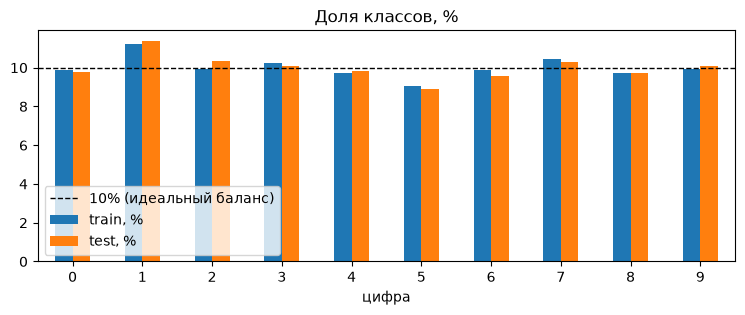

In [5]:
counts = pd.DataFrame({
    "train": pd.Series(y_train_full).value_counts().sort_index(),
    "test":  pd.Series(y_test).value_counts().sort_index(),
})
counts["train, %"] = (100 * counts["train"] / counts["train"].sum()).round(2)
counts["test, %"]  = (100 * counts["test"]  / counts["test"].sum()).round(2)
counts.index.name = "цифра"
display(counts)
print(f"самый большой класс / самый маленький: train {counts['train'].max() / counts['train'].min():.2f}, "
      f"test {counts['test'].max() / counts['test'].min():.2f}")

ax = counts[["train, %", "test, %"]].plot.bar(figsize=(9, 3), rot=0, title="Доля классов, %")
ax.axhline(10, color="k", ls="--", lw=1, label="10% (идеальный баланс)")
ax.legend(); plt.show()

Классы почти сбалансированы: самый большой класс больше самого маленького в 1,24 раза в train и в 1,27 в test.
Поэтому метрика accuracy, веса классов не нужны. Валидацию отрезаю со стратификацией.

### 1.3 Как выглядят картинки

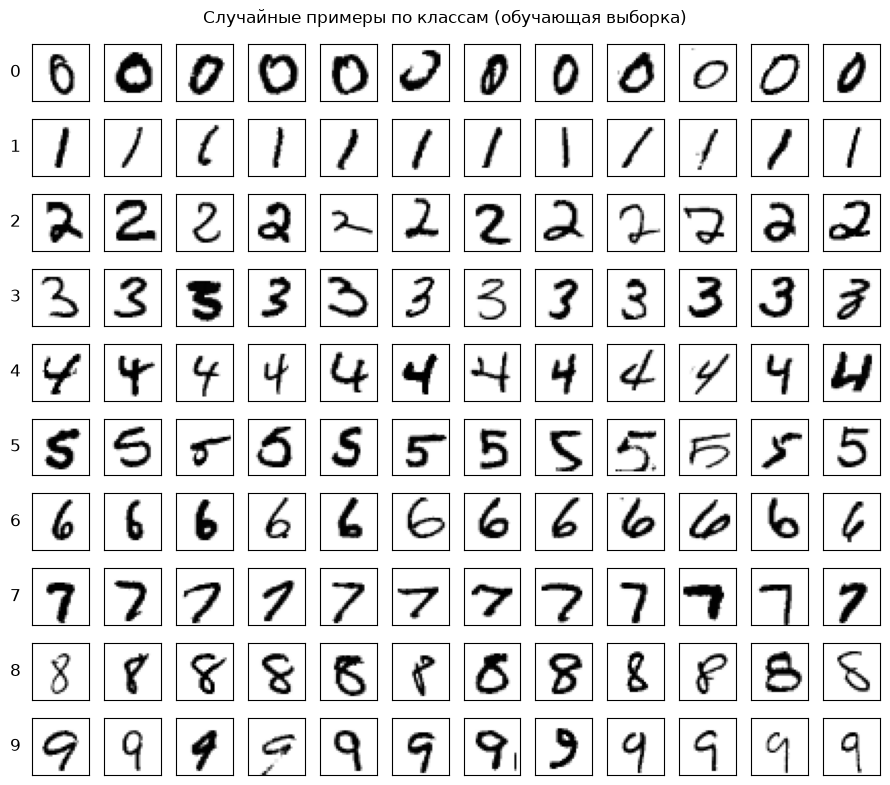

In [6]:
# по 12 случайных примеров каждой цифры
rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(10, 12, figsize=(9, 8))
for d in range(10):
    idx = rng.choice(np.flatnonzero(y_train_full == d), size=12, replace=False)
    for j, i in enumerate(idx):
        axes[d, j].imshow(x_train_full[i], cmap="gray_r")
        axes[d, j].set_xticks([]); axes[d, j].set_yticks([])
    axes[d, 0].set_ylabel(str(d), rotation=0, labelpad=12, fontsize=12, va="center")
fig.suptitle("Случайные примеры по классам (обучающая выборка)")
plt.tight_layout(); plt.show()

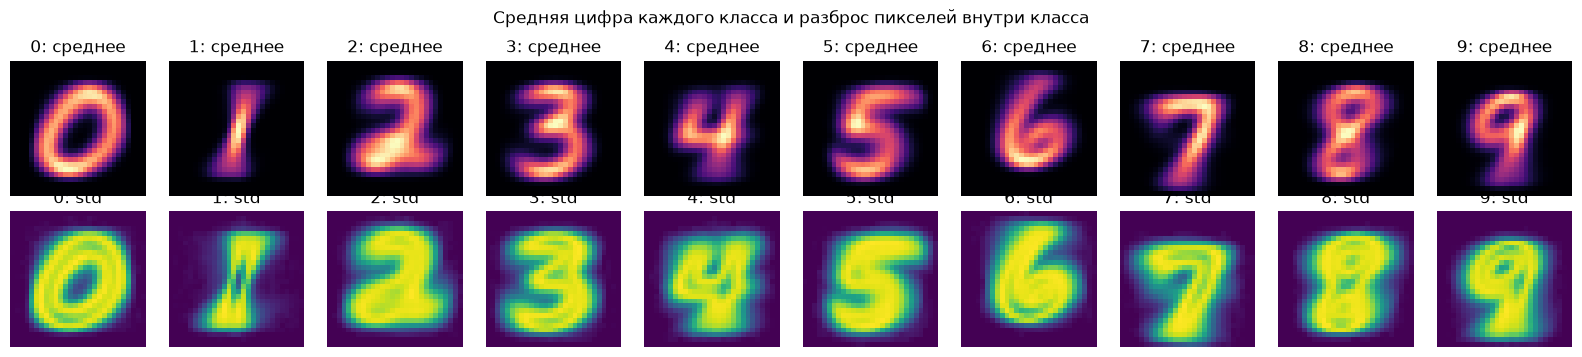

In [7]:
x01_full = x_train_full.astype(np.float32) / 255.0     # яркость в [0, 1], так удобнее считать статистику

fig, axes = plt.subplots(2, 10, figsize=(16, 3.6))
for d in range(10):
    imgs = x01_full[y_train_full == d]
    axes[0, d].imshow(imgs.mean(0), cmap="magma");  axes[0, d].set_title(f"{d}: среднее")
    axes[1, d].imshow(imgs.std(0),  cmap="viridis"); axes[1, d].set_title(f"{d}: std")
for ax in axes.flat:
    ax.axis("off")
fig.suptitle("Средняя цифра каждого класса и разброс пикселей внутри класса")
plt.tight_layout(); plt.show()

Средние картинки классов легко узнать. На картах std видно, где почерки расходятся сильнее всего.

### 1.4 Распределение яркости и нормализация

доля нулевых (фоновых) пикселей: 80.9%
доля пикселей = 255: 0.7%
среднее / std яркости по всему train (в [0, 1]): 0.1307 / 0.3081


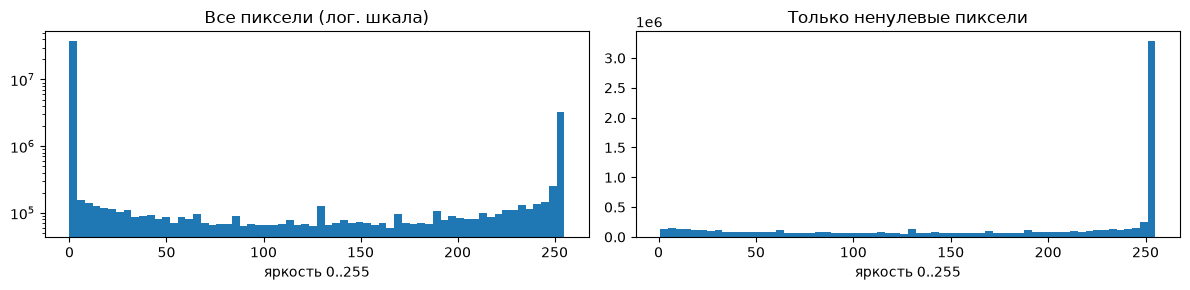

In [8]:
zero_share = (x_train_full == 0).mean()
full_share = (x_train_full == 255).mean()
print(f"доля нулевых (фоновых) пикселей: {zero_share:.1%}")
print(f"доля пикселей = 255: {full_share:.1%}")
print(f"среднее / std яркости по всему train (в [0, 1]): {x01_full.mean():.4f} / {x01_full.std():.4f}")

fig, ax = plt.subplots(1, 2, figsize=(12, 3))
ax[0].hist(x_train_full.ravel(), bins=64, log=True)
ax[0].set_title("Все пиксели (лог. шкала)"); ax[0].set_xlabel("яркость 0..255")
ax[1].hist(x_train_full[x_train_full > 0].ravel(), bins=64)
ax[1].set_title("Только ненулевые пиксели"); ax[1].set_xlabel("яркость 0..255")
plt.tight_layout(); plt.show()

Фоновых пикселей 80,9%, среднее яркости 0,1307, std 0,3081. Вход нормализую как $x' = (x/255 - \mu)/\sigma$,
среднее и std считаю только по обучающей части.

### 1.5 Где находится цифра и какого она размера

высота цифры: медиана 20 px, от 9 до 20
ширина цифры: медиана 16 px, от 2 до 20
центр масс: y = 14.00 ± 0.29, x = 14.01 ± 0.29 (центр кадра 13.5)
картинок, где штрих заходит в рамку 4 px у края: 75.62%
медианная ширина по цифрам: {0: 19.0, 1: 8.0, 2: 20.0, 3: 16.0, 4: 16.0, 5: 20.0, 6: 15.0, 7: 16.0, 8: 16.0, 9: 14.0}


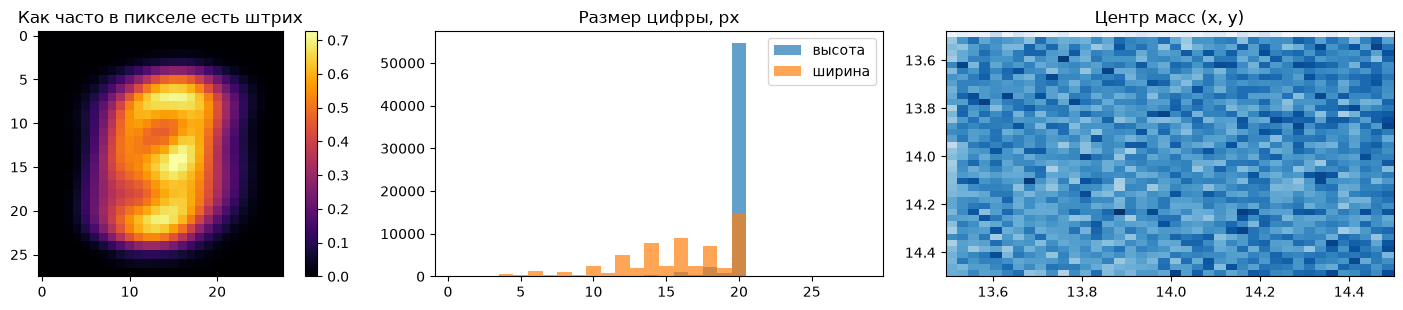

In [9]:
ink = x_train_full > 0                                     # маска "есть штрих"
rows_any, cols_any = ink.any(axis=2), ink.any(axis=1)     # (N, 28): есть ли штрих в строке / в столбце


def extent(mask_1d: np.ndarray) -> np.ndarray:
    """Длина отрезка от первого до последнего True в каждой строке массива (N, 28). Это высота или ширина цифры."""
    first = mask_1d.argmax(axis=1)
    last = mask_1d.shape[1] - 1 - mask_1d[:, ::-1].argmax(axis=1)
    return last - first + 1


height, width = extent(rows_any), extent(cols_any)

ii = np.arange(28)
mass = x01_full.sum(axis=(1, 2))                           # "масса" картинки = сумма яркостей
cy = (x01_full.sum(axis=2) @ ii) / mass                    # центр масс по вертикали
cx = (x01_full.sum(axis=1) @ ii) / mass                    # и по горизонтали

border = np.ones((28, 28), dtype=bool); border[4:-4, 4:-4] = False
print(f"высота цифры: медиана {np.median(height):.0f} px, от {height.min()} до {height.max()}")
print(f"ширина цифры: медиана {np.median(width):.0f} px, от {width.min()} до {width.max()}")
print(f"центр масс: y = {cy.mean():.2f} ± {cy.std():.2f}, x = {cx.mean():.2f} ± {cx.std():.2f} (центр кадра 13.5)")
print(f"картинок, где штрих заходит в рамку 4 px у края: {(x_train_full[:, border] > 0).any(axis=1).mean():.2%}")
print("медианная ширина по цифрам:", pd.Series(width).groupby(y_train_full).median().to_dict())

fig, ax = plt.subplots(1, 3, figsize=(15, 3.2))
im = ax[0].imshow(ink.mean(0), cmap="inferno"); ax[0].set_title("Как часто в пикселе есть штрих")
plt.colorbar(im, ax=ax[0])
ax[1].hist(height, bins=np.arange(0.5, 29.5), alpha=.7, label="высота")
ax[1].hist(width,  bins=np.arange(0.5, 29.5), alpha=.7, label="ширина")
ax[1].legend(); ax[1].set_title("Размер цифры, px")
ax[2].hist2d(cx, cy, bins=40, cmap="Blues"); ax[2].invert_yaxis(); ax[2].set_title("Центр масс (x, y)")
plt.tight_layout(); plt.show()

Медианная высота цифры 20 px, ширина 16 px, центр масс около 14,0 по обеим осям. Цифры в MNIST уже отцентрованы,
поэтому при аугментации картинку можно сдвигать и поворачивать только немного.

### 1.6 Сколько "чернил" у разных цифр

сумма яркостей            доля штриха       
                mean        std        mean    std
цифра                                             
0         135.945007  33.011002       0.245  0.043
1          59.583000  17.242001       0.109  0.025
2         116.795998  29.834999       0.215  0.042
3         110.959999  29.628000       0.208  0.043
4          95.151001  25.000999       0.181  0.035
5         100.940002  29.216999       0.194  0.043
6         107.644997  29.347000       0.200  0.042
7          89.790001  24.018000       0.168  0.034
8         117.722000  30.290001       0.221  0.042
9          96.111000  25.438000       0.182  0.036

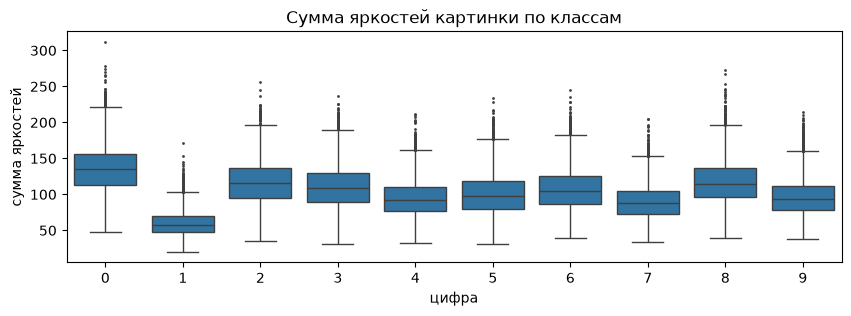

In [10]:
ink_df = pd.DataFrame({"цифра": y_train_full, "сумма яркостей": mass, "доля штриха": ink.mean(axis=(1, 2))})
display(ink_df.groupby("цифра")[["сумма яркостей", "доля штриха"]].agg(["mean", "std"]).round(3))

plt.figure(figsize=(10, 3))
sns.boxplot(data=ink_df, x="цифра", y="сумма яркостей", fliersize=1)
plt.title("Сумма яркостей картинки по классам"); plt.show()

У единицы средняя сумма яркостей 59,583, у нуля 135,945, но разброс внутри классов большой (std от 17 до 33).
По количеству чернил класс не определить, нужны признаки формы.

### 1.7 Дубликаты и пересечение train и test

In [11]:
def image_hashes(X: np.ndarray) -> np.ndarray:
    """MD5 от байтов каждой картинки. У точных дубликатов хеш одинаковый."""
    return np.array([hashlib.md5(img.tobytes()).hexdigest() for img in X])


h_train, h_test = image_hashes(x_train_full), image_hashes(x_test)
print(f"точных дубликатов внутри train: {len(h_train) - len(set(h_train))}")
print(f"точных дубликатов внутри test: {len(h_test) - len(set(h_test))}")
print(f"картинок test, которые есть и в train: {len(set(h_test) & set(h_train))}")

точных дубликатов внутри train: 0
точных дубликатов внутри test: 0
картинок test, которые есть и в train: 0


Точных дубликатов нет, тестовые картинки в train не встречаются.

### 1.8 Структура данных: PCA и t-SNE

80% дисперсии объясняют 43 главных компонент из 784
90% дисперсии объясняют 86 главных компонент из 784
95% дисперсии объясняют 152 главных компонент из 784
99% дисперсии объясняют 329 главных компонент из 784


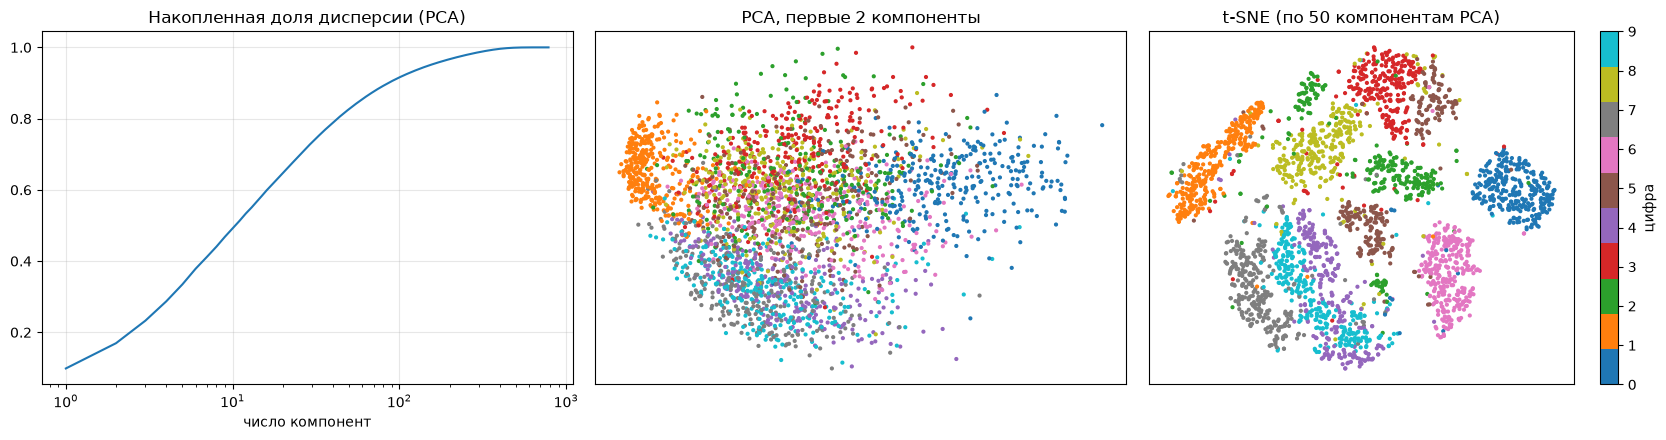

In [12]:
X_flat = x01_full.reshape(len(x01_full), -1)                      # 784 признака, по одному на пиксель
pca = PCA(random_state=SEED).fit(X_flat[:20000])                    # sklearn.decomposition.PCA, все компоненты
cum = np.cumsum(pca.explained_variance_ratio_)
for p in (0.80, 0.90, 0.95, 0.99):
    print(f"{p:.0%} дисперсии объясняют {np.searchsorted(cum, p) + 1} главных компонент из 784")

rng = np.random.default_rng(SEED)
sub = rng.choice(len(X_flat), size=3000, replace=False)
Z_pca = pca.transform(X_flat[sub])
# t-SNE считаю по первым 50 компонентам PCA: так быстрее и меньше шума
Z_tsne = TSNE(n_components=2, perplexity=30, init="pca", random_state=SEED).fit_transform(Z_pca[:, :50])

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
ax[0].plot(np.arange(1, len(cum) + 1), cum); ax[0].set_xscale("log"); ax[0].grid(alpha=.3)
ax[0].set_title("Накопленная доля дисперсии (PCA)"); ax[0].set_xlabel("число компонент")
for a, Z, t in ((ax[1], Z_pca[:, :2], "PCA, первые 2 компоненты"), (ax[2], Z_tsne, "t-SNE (по 50 компонентам PCA)")):
    sc = a.scatter(Z[:, 0], Z[:, 1], c=y_train_full[sub], cmap="tab10", s=4)
    a.set_title(t); a.set_xticks([]); a.set_yticks([])
fig.colorbar(sc, ax=ax[2], ticks=range(10), label="цифра")
plt.tight_layout(); plt.show()

Для 95% дисперсии нужно 152 компоненты из 784. На плоскости двух первых компонент классы сильно перекрываются,
а t-SNE разводит их по отдельным облакам. Значит, классы разделяются нелинейно, и с этим должна справиться небольшая CNN.

### 1.9 Разбиение на train и validation, подготовка тензоров

In [13]:
# тест (10 000) не трогаю до самого конца. от обучающих 60 000 отрезаю валидацию для подбора гиперпараметров.
# stratify сохраняет доли классов в обеих частях
x_tr, x_val, y_tr, y_val = train_test_split(
    x_train_full, y_train_full, test_size=VAL_SIZE, stratify=y_train_full, random_state=SEED)

if FAST:   # отладка: стратифицированная подвыборка обучающей части
    x_tr, _, y_tr, _ = train_test_split(x_tr, y_tr, train_size=12_000, stratify=y_tr, random_state=SEED)

split = pd.DataFrame({
    "train, %": pd.Series(y_tr).value_counts(normalize=True).sort_index() * 100,
    "val, %":   pd.Series(y_val).value_counts(normalize=True).sort_index() * 100,
    "test, %":  pd.Series(y_test).value_counts(normalize=True).sort_index() * 100,
}).round(2)
print(f"train: {len(x_tr)} | val: {len(x_val)} | test: {len(x_test)}")
display(split.T)

train: 54000 | val: 6000 | test: 10000


,0,1,2,3,4,5,6,7,8,9
"train, %",9.87,11.24,9.93,10.22,9.74,9.04,9.86,10.44,9.75,9.91
"val, %",9.87,11.23,9.93,10.22,9.73,9.03,9.87,10.45,9.75,9.92
"test, %",9.80,11.35,10.32,10.10,9.82,8.92,9.58,10.28,9.74,10.09


In [14]:
# параметры нормализации считаю ТОЛЬКО по обучающей части
MEAN = float((x_tr / 255.0).mean())
STD = float((x_tr / 255.0).std())
BG = (0.0 - MEAN) / STD          # значение фона после нормализации, понадобится в аугментации
print(f"MEAN = {MEAN:.4f}, STD = {STD:.4f}, фон после нормализации = {BG:.4f}")


def preprocess(x: np.ndarray) -> np.ndarray:
    """uint8 [0..255] -> float32, стандартизация (x/255 - MEAN) / STD."""
    return ((x.astype(np.float32) / 255.0) - MEAN) / STD


# Keras: формат NHWC (N, высота, ширина, каналы). метки целыми числами, для sparse-кросс-энтропии one-hot не нужен
Xk_tr, Xk_val, Xk_test = (preprocess(x)[..., None] for x in (x_tr, x_val, x_test))
yk_tr, yk_val, yk_test = (y.astype(np.int32) for y in (y_tr, y_val, y_test))

# PyTorch: формат NCHW (N, каналы, высота, ширина), метки int64 (так требует nn.CrossEntropyLoss).
# весь MNIST во float32 занимает ~170 МБ, поэтому кладу его на GPU целиком и режу батчи индексами.
# так быстрее, чем DataLoader, который копирует каждый батч с CPU на GPU
Xt_tr, Xt_val, Xt_test = (torch.from_numpy(preprocess(x)[:, None]).to(DEVICE) for x in (x_tr, x_val, x_test))
yt_tr, yt_val, yt_test = (torch.from_numpy(y.astype(np.int64)).to(DEVICE) for y in (y_tr, y_val, y_test))

print("Keras:  ", Xk_tr.shape, Xk_tr.dtype, "| метки", yk_tr.shape, yk_tr.dtype)
print("PyTorch:", tuple(Xt_tr.shape), Xt_tr.dtype, "| метки", tuple(yt_tr.shape), yt_tr.dtype, "|", Xt_tr.device)
print(f"после нормализации: mean = {Xk_tr.mean():.4f}, std = {Xk_tr.std():.4f}")

del x01_full, X_flat   # освобождаю ~400 МБ памяти

MEAN = 0.1307, STD = 0.3082, фон после нормализации = -0.4242


Keras:   (54000, 28, 28, 1) float32 | метки (54000,) int32
PyTorch: (54000, 1, 28, 28) torch.float32 | метки (54000,) torch.int64 | cuda:0
после нормализации: mean = 0.0000, std = 1.0000


### 1.10 Что получилось по данным

* 60 000 обучающих и 10 000 тестовых картинок 28x28, классы почти сбалансированы.
* Разбиение: train 54 000, val 6 000, test 10 000. По валидации подбираю гиперпараметры, тест только для итоговых моделей.
* Нормализация по train: mean 0,1307, std 0,3082.

## 2. Подбор гиперпараметров на Keras и PyTorch

### 2.0 Базовая архитектура

Сеть в обоих фреймворках задаётся одним словарём `cfg` (функции `build_keras(cfg)` и `TorchCNN(cfg)`),
поэтому результаты Keras и PyTorch можно сравнивать напрямую. За основу взял уменьшенную VGG:

```
вход 28x28x1
блок 1: Conv3x3(32) BN ReLU, Conv3x3(32) BN ReLU, MaxPool 2x2, Dropout 0.25   выход 14x14x32
блок 2: Conv3x3(64) BN ReLU, Conv3x3(64) BN ReLU, MaxPool 2x2, Dropout 0.25   выход 7x7x64
Flatten (3136), Dense(128) ReLU, Dropout 0.5, Dense(10)
```

Две свёртки 3x3 подряд видят область 5x5, как одна свёртка 5x5, но параметров у них меньше. MaxPool уменьшает карту вдвое,
BatchNorm ускоряет обучение, dropout работает против переобучения. Свёртки без bias (его заменяет сдвиг в BN),
инициализация He-uniform. У Keras и PyTorch разные значения по умолчанию (инициализация, momentum и eps у BN, eps у Adam),
поэтому все их я задаю явно. Число параметров по слоям печатается ниже.

Функция потерь: кросс-энтропия по логитам, `SparseCategoricalCrossentropy(from_logits=True)` в Keras и `nn.CrossEntropyLoss` в PyTorch.
У каждой картинки один правильный класс из 10, а softmax и логарифм внутри функции потерь считаются вместе, так численно устойчивее.
Поэтому у последнего слоя нет активации. Оптимизатор Adam.

### План экспериментов

От базы меняю по одному гиперпараметру и смотрю на точность на валидации, число параметров и время эпохи.
Ранняя остановка по `val_loss`, из прогона берутся веса лучшей эпохи.

| Группа | Значения (в скобках база) |
|---|---|
| `lr` | (1e-3), 1e-2, 3e-3, 3e-4, 1e-4 |
| `batch_size` | (128), 64, 512 |
| `n_blocks` | (2), 1, 3 |
| `base_filters` | (32), 16, 64 |
| `convs_per_block` | (2), 1 |
| `batch_norm` | (да), нет |
| `dropout` (после свёрток / в голове) | (0.25/0.5), 0/0, 0.1/0.3, 0.4/0.6 |
| `head` (тип / нейронов) | (flatten/128), flatten/32, gap/128, gap/0 |
| `init` | (he_uniform), glorot_uniform, normal_0.05 |

Потом из каждой группы беру лучшее значение, обучаю кандидатов дольше и выбираю итоговую модель по валидации.
Отдельно обучаю компактную модель.

#### Общие функции: конфигурации, журнал экспериментов, WandB, аугментация

In [15]:
# базовая конфигурация: все гиперпараметры модели и обучения заданы явно
BASE = dict(
    # архитектура
    n_blocks=2,            # число свёрточных блоков (в блоке: свёртки, MaxPool, Dropout)
    base_filters=32,       # фильтров в первом блоке, в каждом следующем вдвое больше
    convs_per_block=2,     # свёрток в блоке
    kernel_size=3,         # размер ядра свёртки
    batch_norm=True,       # BatchNorm после каждой свёртки
    conv_dropout=0.25,     # dropout после каждого блока
    head_type="flatten",   # "flatten": Flatten + Dense; "gap": Global Average Pooling
    dense_units=128,       # нейронов в скрытом полносвязном слое (0 - без него)
    dense_dropout=0.5,     # dropout перед выходным слоем
    init="he_uniform",     # инициализация весов свёрток и скрытого Dense
    # обучение
    lr=1e-3,               # шаг Adam
    batch_size=128,
    aug="none",            # аугментация, пресеты в AUG_PRESETS (раздел 3)
    max_epochs=MAX_EPOCHS,
    patience=PATIENCE,     # ранняя остановка
    early_stopping=True,
    reduce_lr=False,       # ReduceLROnPlateau, включаю для итоговых моделей
)
HP_KEYS = ["lr", "batch_size", "n_blocks", "base_filters", "convs_per_block", "kernel_size", "batch_norm",
           "conv_dropout", "head_type", "dense_units", "dense_dropout", "init", "aug"]

GRID = {
    "lr":              [1e-2, 3e-3, 1e-3, 3e-4, 1e-4],
    "batch_size":      [64, 128, 512],
    "n_blocks":        [1, 2, 3],
    "base_filters":    [16, 32, 64],
    "convs_per_block": [1, 2],
    "batch_norm":      [False, True],
    "dropout":         [(0.0, 0.0), (0.1, 0.3), (0.25, 0.5), (0.4, 0.6)],
    "head":            [("flatten", 128), ("flatten", 32), ("gap", 128), ("gap", 0)],
    "init":            ["he_uniform", "glorot_uniform", "normal_0.05"],
}
# группы, которые меняют сразу несколько ключей cfg
COMPOSITE = {"dropout": ("conv_dropout", "dense_dropout"), "head": ("head_type", "dense_units")}

# аугментация: (поворот, градусы; сдвиг, доля размера; масштаб, +-доля). подробно в разделе 3
AUG_PRESETS = {
    "none":   (0, 0.0, 0.0),
    "rot":    (10, 0.0, 0.0),
    "shift":  (0, 0.1, 0.0),
    "zoom":   (0, 0.0, 0.1),
    "all":    (10, 0.1, 0.1),
    "strong": (40, 0.25, 0.3),    # специально слишком сильная
}


def py(v):
    """numpy-скаляр в обычный python-тип (чтобы cfg нормально сохранялся в JSON и принимался слоями)."""
    return v.item() if isinstance(v, np.generic) else v


def fmt(v) -> str:
    return "/".join(map(str, v)) if isinstance(v, tuple) else str(v)


def base_value(group: str):
    return tuple(BASE[k] for k in COMPOSITE[group]) if group in COMPOSITE else BASE[group]


def apply_variant(cfg: dict, group: str, value) -> dict:
    new = dict(cfg)
    if group in COMPOSITE:
        new.update(zip(COMPOSITE[group], value))
    else:
        new[group] = value
    return new


# все обучения серии: база и по одному отличию от неё
SERIES = [("base", "base", BASE)]
for g, values in GRID.items():
    for v in values:
        if v != base_value(g):
            SERIES.append((g, fmt(v), apply_variant(BASE, g, v)))
print(f"обучений в серии на один фреймворк: {len(SERIES)}")
display(pd.Series({k: BASE[k] for k in HP_KEYS + ["max_epochs", "patience"]}, name="BASE").to_frame().T)

обучений в серии на один фреймворк: 21


,lr,batch_size,n_blocks,base_filters,convs_per_block,kernel_size,batch_norm,conv_dropout,head_type,dense_units,dense_dropout,init,aug,max_epochs,patience
BASE,0.001,128,2,32,2,3,True,0.25,flatten,128,0.5,he_uniform,none,15,3


Каждое обучение пишется в список `RUNS` (из него таблицы и `artifacts/runs_log.csv`) и в WandB:
гиперпараметры в config, loss, accuracy и lr по эпохам. Без ключа WandB прогоны пишутся офлайн в `artifacts/wandb/`.

In [16]:
try:
    import wandb
except ImportError:
    wandb = None


def wandb_key_saved() -> bool:
    """Есть ли сохранённый ключ WandB (после `wandb login` он лежит в ~/.netrc или ~/_netrc)."""
    if os.environ.get("WANDB_API_KEY"):
        return True
    for f in (Path.home() / ".netrc", Path.home() / "_netrc"):
        if f.exists() and "api.wandb.ai" in f.read_text(errors="ignore"):
            return True
    return False


if not USE_WANDB or wandb is None:
    WANDB_MODE = "disabled"
elif os.environ.get("WANDB_MODE"):
    WANDB_MODE = os.environ["WANDB_MODE"]
elif wandb_key_saved():
    WANDB_MODE = "online"
elif IN_COLAB:
    WANDB_MODE = "online" if wandb.login() else "offline"   # Colab попросит вставить API-ключ
else:
    WANDB_MODE = "offline"
os.environ["WANDB_MODE"] = WANDB_MODE   # чтобы и служебная телеметрия wandb не ходила в сеть в офлайн-режиме
print("WandB:", WANDB_MODE, "| проект:", WANDB_PROJECT)

LOG_KEYS = HP_KEYS + ["max_epochs", "patience", "reduce_lr"]
RUNS = []        # строки журнала всех обучений тетрадки


class Tracker:
    """Один прогон в WandB: конфиг при создании, метрики по эпохам, итог при закрытии."""

    def __init__(self, name: str, framework: str, group: str, cfg: dict, n_params: int):
        self.run = None
        if WANDB_MODE != "disabled":
            self.run = wandb.init(
                project=WANDB_PROJECT, name=f"{framework}/{group}/{name}", group=group, job_type=framework,
                config={"framework": framework, "group": group, "variant": name, "params": n_params,
                        **{k: cfg.get(k) for k in LOG_KEYS}},
                mode=WANDB_MODE, dir=str(ART_DIR))

    def log(self, epoch: int, metrics: dict) -> None:
        if self.run is not None:
            try:
                self.run.log({"epoch": epoch, **metrics})
            except Exception as e:      # сбой логирования не должен останавливать обучение
                print("WandB log:", e)

    def finish(self, **summary) -> None:
        if self.run is not None:
            try:
                self.run.summary.update(summary)
                self.run.finish()
            except Exception as e:
                print("WandB finish:", e)
            self.run = None


def new_hist() -> dict:
    return {k: [] for k in ("loss", "accuracy", "val_loss", "val_accuracy", "epoch_time", "lr")}


def summarize(framework: str, group: str, variant: str, cfg: dict, hist: dict, n_params: int, total_s: float) -> dict:
    """Строка журнала: метрики лучшей по val_loss эпохи и все гиперпараметры."""
    vl = np.asarray(hist["val_loss"])
    be = int(vl.argmin())
    return dict(
        framework=framework, group=group, variant=variant,
        val_acc=hist["val_accuracy"][be], val_loss=float(vl[be]),
        train_acc=hist["accuracy"][be], train_loss=hist["loss"][be],
        gap=hist["accuracy"][be] - hist["val_accuracy"][be],     # train - val, признак переобучения
        best_epoch=be + 1, epochs=len(vl), params=int(n_params),
        s_per_epoch=float(np.median(hist["epoch_time"])),        # медиана, чтобы не считать компиляцию в 1-й эпохе
        time_s=total_s, test_acc=np.nan,
        **{k: cfg.get(k) for k in HP_KEYS},
    )


def close_run(tracker: Tracker, row: dict, **extra) -> None:
    tracker.finish(best_val_acc=row["val_acc"], best_val_loss=row["val_loss"], best_epoch=row["best_epoch"],
                   epochs=row["epochs"], params=row["params"], s_per_epoch=row["s_per_epoch"], **extra)


def group_view(df: pd.DataFrame, group: str) -> pd.DataFrame:
    """Строки одной группы и базовая строка (база - одно из значений группы), в порядке значений из GRID."""
    order = [fmt(v) for v in GRID[group]]
    sub = df[df["group"].isin([group, "base"])].copy()
    sub["is_base"] = sub["group"] == "base"
    sub["value"] = [fmt(base_value(group)) if b else v for b, v in zip(sub["is_base"], sub["variant"])]
    sub["label"] = [v + (" (base)" if b else "") for v, b in zip(sub["value"], sub["is_base"])]
    sub["order"] = sub["value"].map(order.index)
    return sub.sort_values("order")


def best_config(df: pd.DataFrame, tol: float = 5e-4) -> tuple[dict, pd.DataFrame]:
    """Лучшее значение каждой группы по val_acc. При разнице в пределах tol берётся вариант с меньшим числом параметров."""
    cfg, rows = dict(BASE), []
    for group in GRID:
        sub = group_view(df, group)
        top = sub[sub["val_acc"] >= sub["val_acc"].max() - tol]
        pick = top.sort_values(["params", "val_acc"], ascending=[True, False]).iloc[0]
        keys = COMPOSITE.get(group, (group,))
        cfg.update({k: py(pick[k]) for k in keys})
        rows.append(dict(group=group, base=fmt(base_value(group)), chosen=pick["value"],
                         val_acc_chosen=pick["val_acc"], val_acc_best=sub["val_acc"].max(), params=pick["params"]))
    return cfg, pd.DataFrame(rows)


def softmax(z: np.ndarray) -> np.ndarray:
    z = z - z.max(axis=1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=1, keepdims=True)

WandB: offline | проект: cnn-mnist-lab2


In [17]:
def plot_history(hist: dict, title: str) -> None:
    """Кривые одного прогона: loss, accuracy (train и val) и шаг обучения."""
    ep = np.arange(1, len(hist["loss"]) + 1)
    best = int(np.argmin(hist["val_loss"])) + 1
    fig, ax = plt.subplots(1, 3, figsize=(17, 3.6))
    ax[0].plot(ep, hist["loss"], "o-", label="train"); ax[0].plot(ep, hist["val_loss"], "o-", label="val")
    ax[0].set_title("loss (кросс-энтропия)")
    ax[1].plot(ep, hist["accuracy"], "o-", label="train"); ax[1].plot(ep, hist["val_accuracy"], "o-", label="val")
    ax[1].set_title("accuracy"); ax[1].set_ylim(max(0.9, min(hist["val_accuracy"]) - 0.005), 1.0)
    for a in ax[:2]:
        a.axvline(best, color="gray", ls=":", label=f"лучшая эпоха: {best}")
        a.legend(); a.grid(alpha=.3); a.set_xlabel("эпоха")
    ax[2].plot(ep, hist["lr"], "o-"); ax[2].set_yscale("log"); ax[2].set_title("learning rate")
    ax[2].grid(alpha=.3); ax[2].set_xlabel("эпоха")
    fig.suptitle(title); plt.tight_layout(); plt.show()


def plot_series_curves(curves: dict, framework: str, metric: str, ylim: tuple) -> None:
    """metric по эпохам для всех вариантов каждой группы (пунктир - база)."""
    fig, axes = plt.subplots(3, 3, figsize=(19, 11), sharey=True)
    base_h = curves[("base", "base")]
    for ax, group in zip(axes.flat, GRID):
        ax.plot(np.arange(1, len(base_h[metric]) + 1), base_h[metric], "k--", lw=2,
                label=f"{fmt(base_value(group))} (base)")
        for (g, label), h in curves.items():
            if g == group:
                ax.plot(np.arange(1, len(h[metric]) + 1), h[metric], marker=".", label=label)
        ax.set_title(group); ax.grid(alpha=.3); ax.legend(fontsize=8); ax.set_xlabel("эпоха")
    axes[0, 0].set_ylim(*ylim)
    fig.suptitle(f"{framework}: {metric} по эпохам"); plt.tight_layout(); plt.show()


def plot_series_bars(df: pd.DataFrame, framework: str) -> None:
    """val_acc лучшей эпохи по вариантам (оранжевый - база); подпись: точность | параметры | секунд на эпоху."""
    fig, axes = plt.subplots(3, 3, figsize=(20, 10))
    for ax, group in zip(axes.flat, GRID):
        sub = group_view(df, group)
        ax.barh(sub["label"], sub["val_acc"], color=["tab:orange" if b else "tab:blue" for b in sub["is_base"]])
        for y, (acc, p, s) in enumerate(zip(sub["val_acc"], sub["params"], sub["s_per_epoch"])):
            ax.text(acc, y, f" {acc:.4f} | {p / 1e3:.0f}k | {s:.1f}s", va="center", fontsize=8)
        ax.set_xlim(sub["val_acc"].min() - 0.004, 1.0 + 0.004)
        ax.invert_yaxis(); ax.set_title(group); ax.grid(axis="x", alpha=.3)
    fig.suptitle(f"{framework}: val accuracy лучшей эпохи | число параметров | секунд на эпоху")
    plt.tight_layout(); plt.show()


SHOW_COLS = ["group", "variant", "val_acc", "val_loss", "train_acc", "gap", "best_epoch", "epochs",
             "params", "s_per_epoch", "time_s"]

#### Аугментация (функции)

Ключ `aug` входит в `cfg`, поэтому функции нужны уже здесь, а сама аугментация разобрана в разделе 3.
В Keras это слои `RandomRotation`, `RandomTranslation`, `RandomZoom` в начале модели, в PyTorch функция `augment_torch`
на GPU (`F.affine_grid` и `F.grid_sample`). Обе работают только при обучении, пустые края заполняются цветом фона `BG`.
Под Windows Keras работает на бэкенде torch, и там штатные слои очень медленные. Поэтому на этом бэкенде используется
свой слой `TorchAffineAug`, он вызывает ту же `augment_torch`.

In [18]:
@keras.saving.register_keras_serializable(package="lab2")
class TorchAffineAug(layers.Layer):
    """Тот же поворот, сдвиг и масштаб, что в augment_torch, но в виде слоя Keras. Нужен только на бэкенде torch:
    там штатные RandomRotation/RandomTranslation/RandomZoom у меня шли примерно в 17 раз медленнее, чем на TF."""
    def __init__(self, preset: str, **kw):
        super().__init__(**kw)
        self.preset = preset

    def call(self, x, training=None):
        if not training:
            return x
        return augment_torch(x.permute(0, 3, 1, 2), self.preset).permute(0, 2, 3, 1)   # NHWC -> NCHW и обратно

    def compute_output_shape(self, input_shape):
        return input_shape

    def get_config(self):
        return {**super().get_config(), "preset": self.preset}


def keras_aug_layers(name: str) -> list:
    """Слои аугментации Keras для пресета name (активны только при обучении)."""
    rot, shift, zoom = AUG_PRESETS[name]
    if name != "none" and keras.backend.backend() == "torch":
        return [TorchAffineAug(name, name="aug_affine")]
    out = []
    if rot:   # factor задаётся в долях полного оборота
        out.append(layers.RandomRotation(rot / 360, fill_mode="constant", fill_value=BG, seed=SEED, name="aug_rot"))
    if shift:
        out.append(layers.RandomTranslation(shift, shift, fill_mode="constant", fill_value=BG, seed=SEED, name="aug_shift"))
    if zoom:  # width_factor=None: ширина масштабируется так же, как высота
        out.append(layers.RandomZoom(zoom, fill_mode="constant", fill_value=BG, seed=SEED, name="aug_zoom"))
    return out


def augment_torch(x: torch.Tensor, name: str) -> torch.Tensor:
    """Случайный поворот, сдвиг и масштаб, у каждой картинки батча свои. x: (N, 1, 28, 28) на GPU."""
    rot, shift, zoom = AUG_PRESETS[name]
    n, dev = x.shape[0], x.device
    u = lambda: torch.rand(n, device=dev) * 2 - 1          # равномерно в [-1, 1]
    ang = u() * math.radians(rot)
    scale = 1 + u() * zoom
    # в координатах affine_grid картинка занимает отрезок [-1, 1], т.е. её ширина равна 2
    tx, ty = u() * shift * 2, u() * shift * 2
    cos, sin = torch.cos(ang) / scale, torch.sin(ang) / scale
    theta = torch.stack([torch.stack([cos, -sin, tx], 1), torch.stack([sin, cos, ty], 1)], 1)   # (N, 2, 3)
    grid = F.affine_grid(theta, list(x.shape), align_corners=False)
    # grid_sample заполняет края нулями, а фон у нас BG. поэтому вычитаю фон до и прибавляю после
    return F.grid_sample(x - BG, grid, mode="bilinear", padding_mode="zeros", align_corners=False) + BG

### 2.1 Keras

Модель `keras.Sequential`, обучение через `model.fit`. Колбэки: `EarlyStopping`, `ModelCheckpoint` (веса лучшей эпохи),
`ReduceLROnPlateau` для итоговых моделей и свой `EpochLogger`, который пишет время эпохи и метрики в журнал и WandB.

In [19]:
def keras_init(name: str):
    """Инициализатор весов по имени из cfg. Каждый раз новый объект, иначе Keras предупреждает о повторном использовании."""
    if name == "normal_0.05":
        return keras.initializers.RandomNormal(mean=0.0, stddev=0.05)
    return keras.initializers.get(name)        # "he_uniform" или "glorot_uniform"


def build_keras(cfg: dict) -> keras.Model:
    """CNN по словарю гиперпараметров cfg (см. BASE). Последний слой выдаёт логиты, без softmax."""
    bn = cfg["batch_norm"]
    model = keras.Sequential(name="cnn_keras")
    model.add(keras.Input(shape=(28, 28, 1)))                    # NHWC: 28x28, 1 канал
    for l in keras_aug_layers(cfg.get("aug", "none")):           # аугментация, если есть (только при обучении)
        model.add(l)
    for b in range(cfg["n_blocks"]):
        filters = cfg["base_filters"] * 2 ** b                    # 32, 64, 128: каналов вдвое больше, карта вдвое меньше
        for c in range(cfg["convs_per_block"]):
            model.add(layers.Conv2D(
                filters=filters,
                kernel_size=cfg["kernel_size"],
                strides=1,
                padding="same",                                   # края дополняются нулями, размер карты не меняется
                use_bias=not bn,                                  # с BN bias не нужен, его роль играет сдвиг beta
                kernel_initializer=keras_init(cfg["init"]),
                name=f"b{b + 1}_conv{c + 1}"))
            if bn:
                model.add(layers.BatchNormalization(momentum=0.9, epsilon=1e-5, name=f"b{b + 1}_bn{c + 1}"))
            model.add(layers.ReLU(name=f"b{b + 1}_relu{c + 1}"))
        model.add(layers.MaxPooling2D(pool_size=2, strides=2, name=f"b{b + 1}_pool"))   # H, W уменьшаются вдвое
        if cfg["conv_dropout"] > 0:
            model.add(layers.Dropout(cfg["conv_dropout"], name=f"b{b + 1}_drop"))
    # "голова"
    if cfg["head_type"] == "flatten":
        model.add(layers.Flatten(name="flatten"))                 # HxWxC -> вектор длины H*W*C
    elif cfg["head_type"] == "gap":
        model.add(layers.GlobalAveragePooling2D(name="gap"))     # HxWxC -> C (среднее по каждой карте), 0 параметров
    else:
        raise ValueError(f"неизвестный head_type: {cfg['head_type']}")
    if cfg["dense_units"] > 0:
        model.add(layers.Dense(cfg["dense_units"], kernel_initializer=keras_init(cfg["init"]), name="fc"))
        model.add(layers.ReLU(name="fc_relu"))
    if cfg["dense_dropout"] > 0:
        model.add(layers.Dropout(cfg["dense_dropout"], name="fc_drop"))
    # 10 логитов. выходной слой всегда Glorot, на нём нет ReLU
    model.add(layers.Dense(10, kernel_initializer="glorot_uniform", dtype="float32", name="logits"))
    return model


def count_keras(model: keras.Model) -> int:
    """Число обучаемых параметров (без скользящих статистик BatchNorm)."""
    return int(sum(np.prod(w.shape) for w in model.trainable_weights))


def keras_param_table(model: keras.Model) -> pd.DataFrame:
    """Таблица по слоям: тип, форма выхода, обучаемые и необучаемые параметры, доля от всех обучаемых."""
    rows, x = [], keras.ops.convert_to_tensor(np.zeros((1, 28, 28, 1), dtype="float32"))
    for layer in model.layers:
        x = layer(x)                                              # прогоняю пустую картинку, чтобы узнать форму выхода
        rows.append(dict(layer=layer.name, type=type(layer).__name__, output=tuple(int(d) for d in x.shape[1:]),
                         trainable=int(sum(np.prod(w.shape) for w in layer.trainable_weights)),
                         non_trainable=int(sum(np.prod(w.shape) for w in layer.non_trainable_weights))))
    df = pd.DataFrame(rows)
    df["share_%"] = (100 * df["trainable"] / df["trainable"].sum()).round(2)
    return df


m = build_keras(BASE)
m.summary()
keras_base_table = keras_param_table(m)
display(keras_base_table)
print(f"обучаемых параметров: {count_keras(m):,}")

Model: "cnn_keras"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ b1_conv1 (Conv2D)               │ (None, 28, 28, 32)     │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b1_bn1 (BatchNormalization)     │ (None, 28, 28, 32)     │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b1_relu1 (ReLU)                 │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b1_conv2 (Conv2D)               │ (None, 28, 28, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b1_bn2 (BatchNormalization)     │ (None, 28, 28, 32)     │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b1_relu2 (ReLU)                 │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b1_pool (MaxPooling2D)          │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b1_drop (Dropout)               │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b2_conv1 (Conv2D)               │ (None, 14, 14, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b2_bn1 (BatchNormalization)     │ (None, 14, 14, 64)     │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b2_relu1 (ReLU)                 │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b2_conv2 (Conv2D)               │ (None, 14, 14, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b2_bn2 (BatchNormalization)     │ (None, 14, 14, 64)     │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b2_relu2 (ReLU)                 │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b2_pool (MaxPooling2D)          │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b2_drop (Dropout)               │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc (Dense)                      │ (None, 128)            │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc_relu (ReLU)                  │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc_drop (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ logits (Dense)                  │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 468,394 (1.79 MB)

 Trainable params: 468,010 (1.79 MB)

 Non-trainable params: 384 (1.50 KB)

,layer,type,output,trainable,non_trainable,share_%
0,b1_conv1,Conv2D,"(28, 28, 32)",288,0,0.06
1,b1_bn1,BatchNormalization,"(28, 28, 32)",64,64,0.01
2,b1_relu1,ReLU,"(28, 28, 32)",0,0,0.00
3,b1_conv2,Conv2D,"(28, 28, 32)",9216,0,1.97
4,b1_bn2,BatchNormalization,"(28, 28, 32)",64,64,0.01
5,b1_relu2,ReLU,"(28, 28, 32)",0,0,0.00
6,b1_pool,MaxPooling2D,"(14, 14, 32)",0,0,0.00
7,b1_drop,Dropout,"(14, 14, 32)",0,0,0.00
8,b2_conv1,Conv2D,"(14, 14, 64)",18432,0,3.94
9,b2_bn1,BatchNormalization,"(14, 14, 64)",128,128,0.03


обучаемых параметров: 468,010


In [20]:
class EpochLogger(keras.callbacks.Callback):
    """Пишет в hist время эпохи, lr и метрики, и отправляет их в WandB."""

    def __init__(self, tracker: Tracker, hist: dict):
        super().__init__()
        self.tracker, self.hist = tracker, hist

    def on_epoch_begin(self, epoch, logs=None):
        self.t0 = time.perf_counter()
        self.lr = float(keras.ops.convert_to_numpy(self.model.optimizer.learning_rate))

    def on_epoch_end(self, epoch, logs=None):
        self.hist["epoch_time"].append(time.perf_counter() - self.t0)
        self.hist["lr"].append(self.lr)
        for k in ("loss", "accuracy", "val_loss", "val_accuracy"):
            self.hist[k].append(float(logs[k]))
        self.tracker.log(len(self.hist["loss"]), {k: self.hist[k][-1] for k in self.hist})


def fit_keras(model, cfg, lr, epochs, hist, tracker, ckpt) -> None:
    """compile + fit. История дописывается в hist, поэтому обучение можно вести в несколько фаз (раздел 4)."""
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=lr, beta_1=0.9, beta_2=0.999, epsilon=1e-7),
        loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),   # метки целые, выход - логиты
        metrics=[keras.metrics.SparseCategoricalAccuracy(name="accuracy")],
        jit_compile="auto",          # XLA-компиляция, если бэкенд её поддерживает (TF на GPU)
    )
    callbacks = [EpochLogger(tracker, hist), ckpt]
    if cfg["early_stopping"]:
        callbacks.append(keras.callbacks.EarlyStopping(monitor="val_loss", patience=cfg["patience"]))
    if cfg["reduce_lr"]:             # lr в 2 раза меньше, если val_loss не улучшается 2 эпохи
        callbacks.append(keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6))
    model.fit(Xk_tr, yk_tr, batch_size=cfg["batch_size"], epochs=epochs,
              validation_data=(Xk_val, yk_val), shuffle=True, callbacks=callbacks, verbose=0)


def keras_ckpt(path: Path):
    """Колбэк, который сохраняет веса лучшей по val_loss эпохи."""
    return keras.callbacks.ModelCheckpoint(str(path), monitor="val_loss", save_best_only=True, save_weights_only=True)


def train_keras(cfg: dict, name: str, group: str = "series", keep_open: bool = False):
    """Обучает build_keras(cfg). Возвращает модель с весами лучшей эпохи, историю, строку журнала и трекер WandB."""
    keras.backend.clear_session()             # сбрасываю всё, что осталось от прошлых моделей
    set_seed(SEED)                            # одинаковая инициализация весов и порядок батчей
    model = build_keras(cfg)
    tracker = Tracker(name, "keras", group, cfg, count_keras(model))
    hist, path = new_hist(), ART_DIR / "keras_best.weights.h5"
    t0 = time.perf_counter()
    fit_keras(model, cfg, cfg["lr"], cfg["max_epochs"], hist, tracker, keras_ckpt(path))
    total = time.perf_counter() - t0
    model.load_weights(str(path))             # веса лучшей эпохи
    row = summarize("keras", group, name, cfg, hist, count_keras(model), total)
    RUNS.append(row)
    if not keep_open:
        close_run(tracker, row)
    return model, hist, row, tracker

#### Серия Keras (21 обучение)

In [21]:
rows_k, curves_k = [], {}
t_series = time.perf_counter()
for group, variant, cfg in SERIES:
    _, hist, r, _ = train_keras(cfg, variant, group)
    rows_k.append(r)
    curves_k[(group, variant)] = hist
    print(f"{group:15s} {variant:14s} | val_acc {r['val_acc']:.4f} | val_loss {r['val_loss']:.4f} | "
          f"эпоха {r['best_epoch']:2d}/{r['epochs']:2d} | {r['params']:>9,} парам. | {r['s_per_epoch']:.1f} с/эп")
print(f"серия Keras: {(time.perf_counter() - t_series) / 60:.1f} мин")

res_k = pd.DataFrame(rows_k)
res_k.to_csv(ART_DIR / "results_keras.csv", index=False)
display(res_k[SHOW_COLS].round(4))

base            base           | val_acc 0.9895 | val_loss 0.0428 | эпоха  6/ 9 |   468,010 парам. | 4.6 с/эп


lr              0.01           | val_acc 0.9843 | val_loss 0.0646 | эпоха 15/15 |   468,010 парам. | 4.6 с/эп


lr              0.003          | val_acc 0.9912 | val_loss 0.0416 | эпоха 13/15 |   468,010 парам. | 4.6 с/эп


lr              0.0003         | val_acc 0.9912 | val_loss 0.0355 | эпоха 10/13 |   468,010 парам. | 4.6 с/эп


lr              0.0001         | val_acc 0.9895 | val_loss 0.0395 | эпоха 15/15 |   468,010 парам. | 4.6 с/эп


batch_size      64             | val_acc 0.9940 | val_loss 0.0290 | эпоха 12/15 |   468,010 парам. | 9.1 с/эп


... (12 outputs left out)

head            gap/0          | val_acc 0.9888 | val_loss 0.0368 | эпоха 15/15 |    65,834 парам. | 4.4 с/эп


init            glorot_uniform | val_acc 0.9907 | val_loss 0.0336 | эпоха 11/14 |   468,010 парам. | 4.6 с/эп


init            normal_0.05    | val_acc 0.9897 | val_loss 0.0409 | эпоха  8/11 |   468,010 парам. | 4.6 с/эп
серия Keras: 21.8 мин


,group,variant,val_acc,val_loss,train_acc,gap,best_epoch,epochs,params,s_per_epoch,time_s
0,base,base,0.9895,0.0428,0.9679,-0.0216,6,9,468010,4.6051,45.0290
1,lr,0.01,0.9843,0.0646,0.9145,-0.0699,15,15,468010,4.5934,69.3523
2,lr,0.003,0.9912,0.0416,0.9467,-0.0444,13,15,468010,4.6136,69.6163
3,lr,0.0003,0.9912,0.0355,0.9841,-0.0070,10,13,468010,4.5922,60.0960
4,lr,0.0001,0.9895,0.0395,0.9823,-0.0072,15,15,468010,4.6064,69.6938
5,batch_size,64,0.9940,0.0290,0.9854,-0.0086,12,15,468010,9.0656,139.2474
6,batch_size,512,0.9895,0.0403,0.9769,-0.0126,15,15,468010,2.0252,35.7987
7,n_blocks,1,0.9882,0.0439,0.9760,-0.0122,12,15,813866,3.1464,47.3792
8,n_blocks,3,0.9913,0.0336,0.9860,-0.0053,6,9,435754,6.2226,57.7909
9,base_filters,16,0.9915,0.0370,0.9849,-0.0066,12,15,218586,4.6074,72.6520


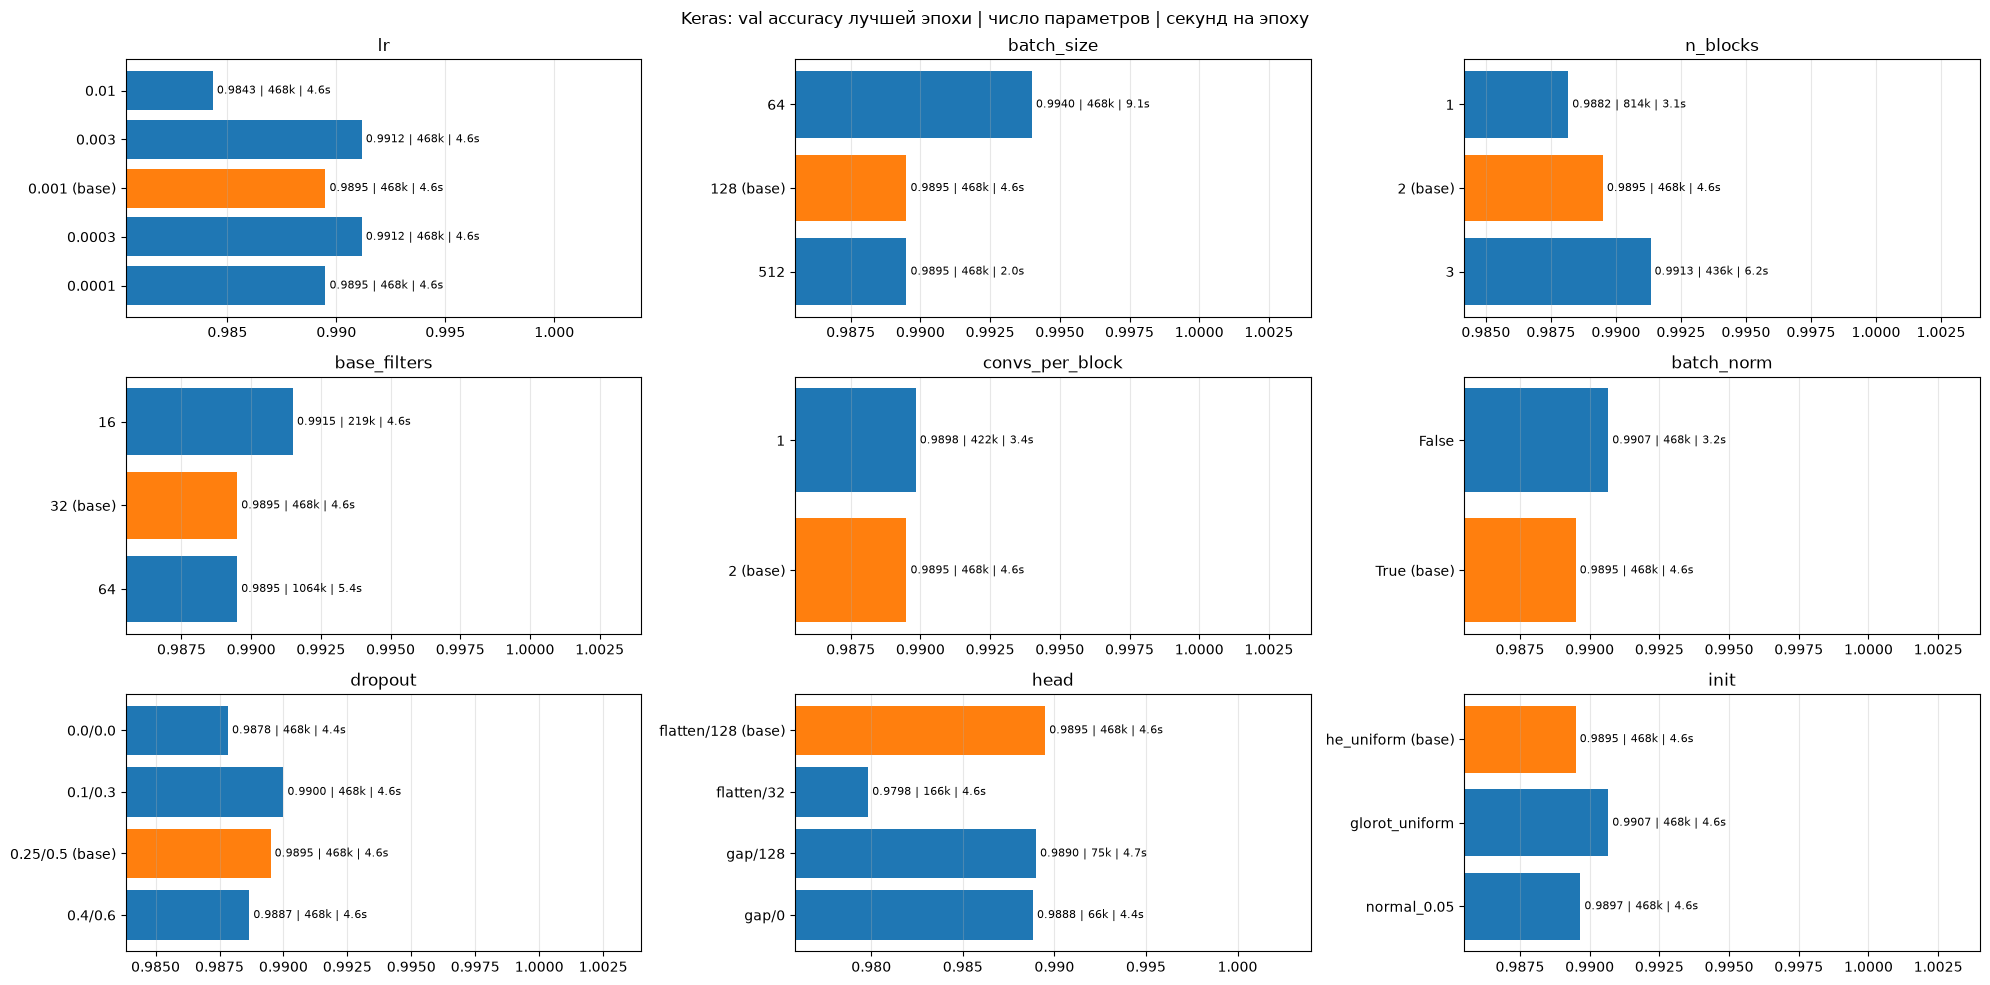

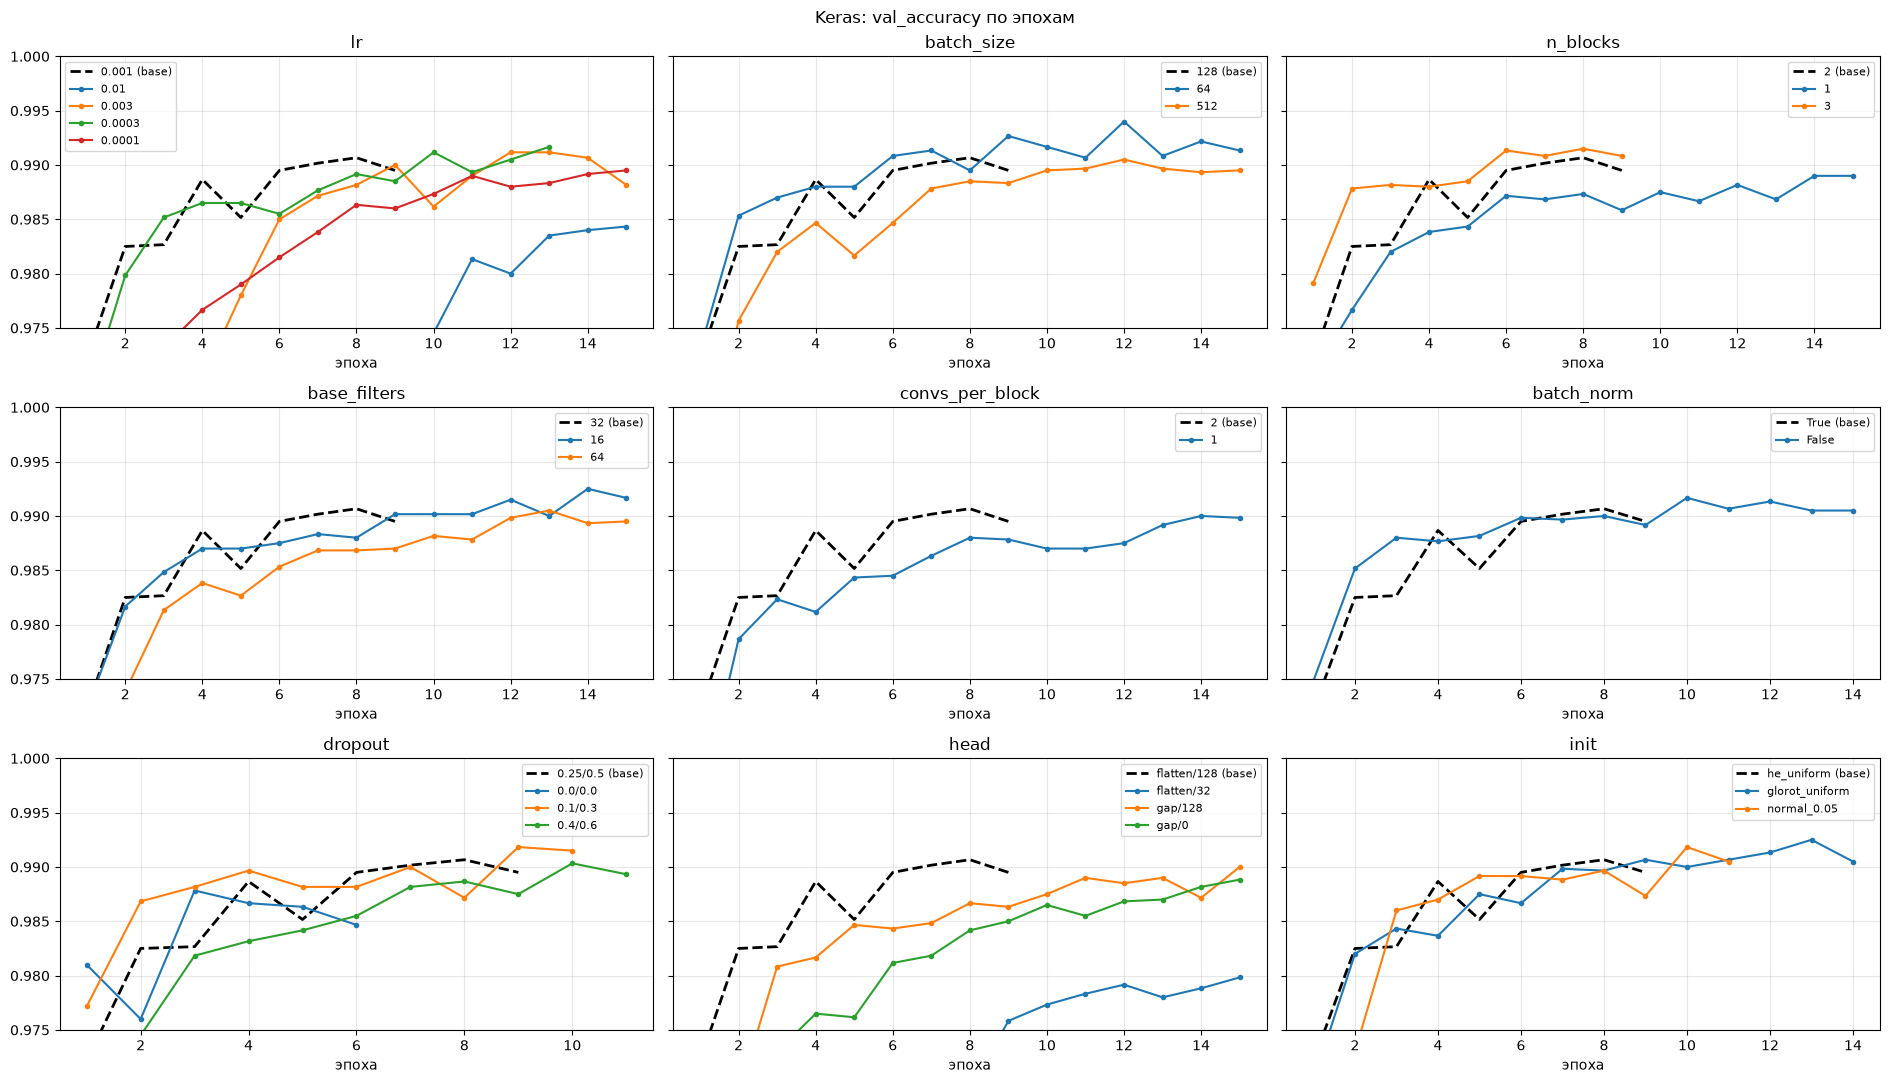

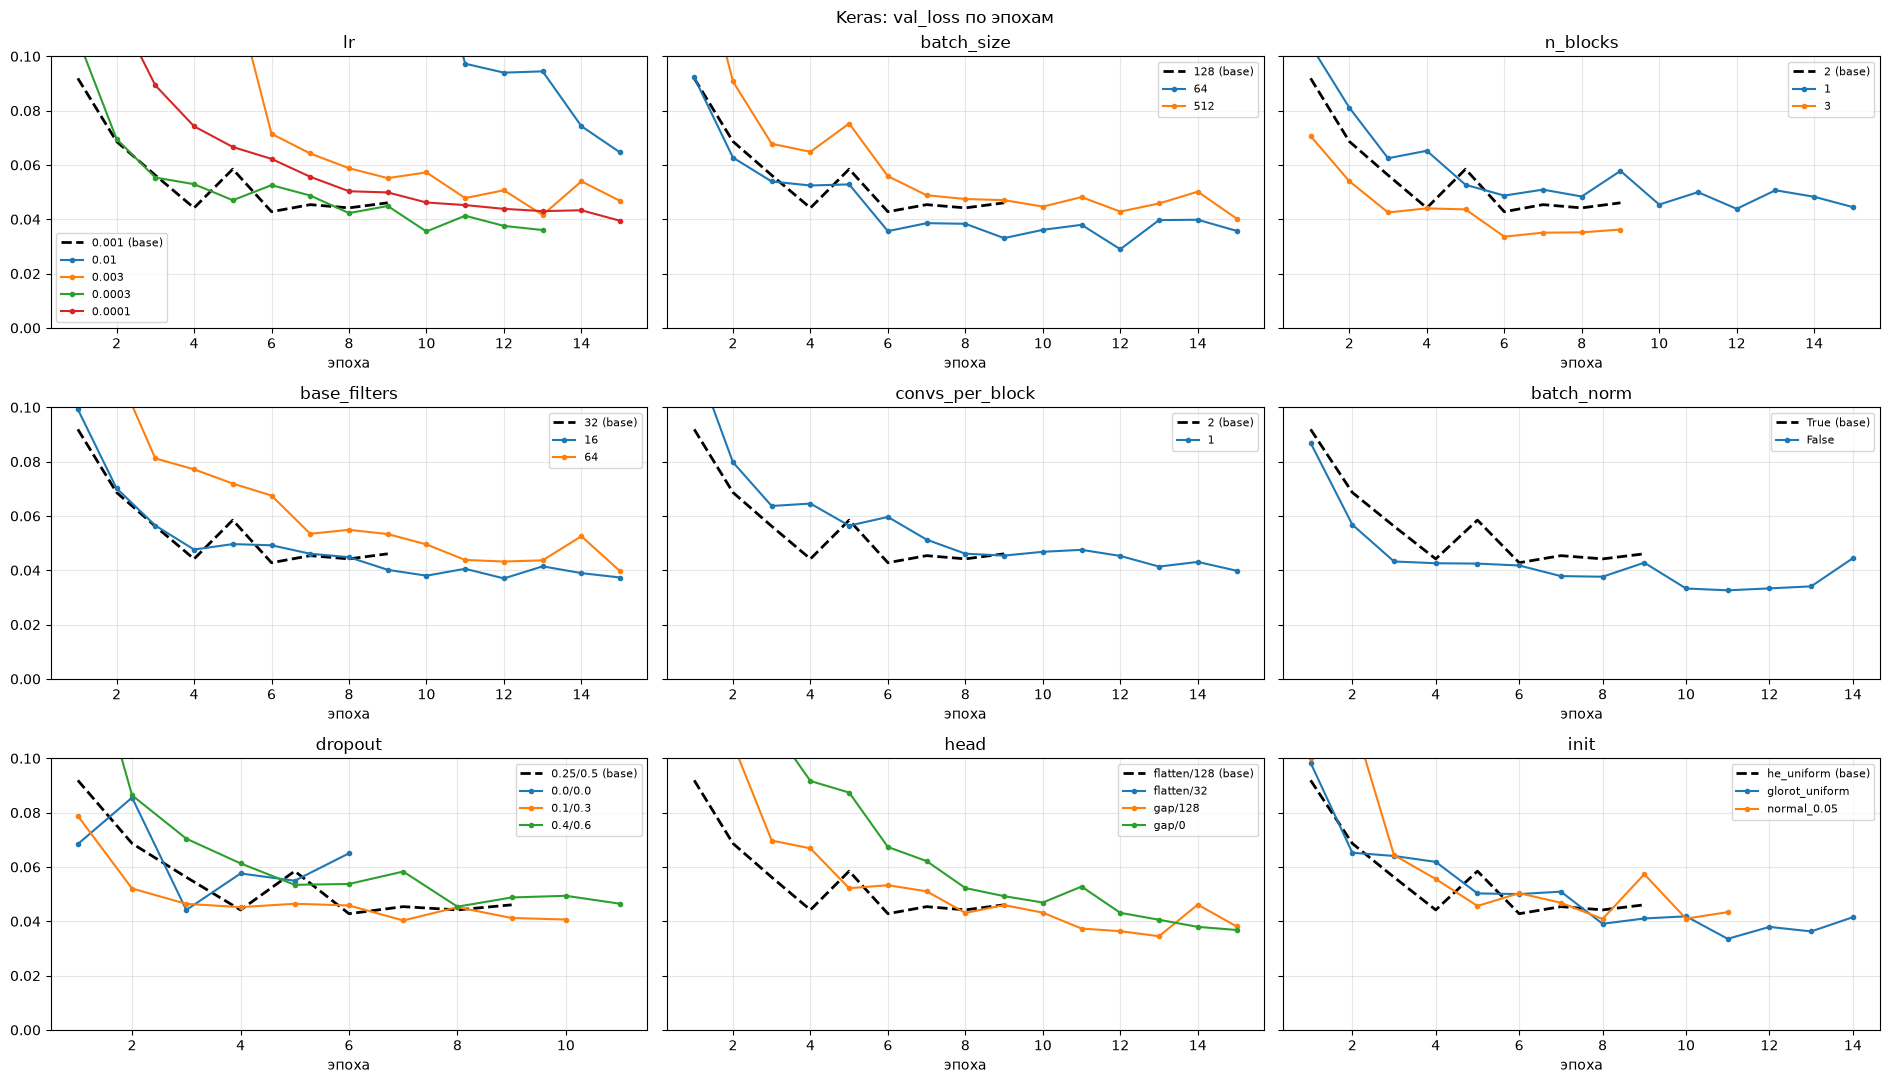

In [22]:
plot_series_bars(res_k, "Keras")
plot_series_curves(curves_k, "Keras", "val_accuracy", ylim=(0.975, 1.0))
plot_series_curves(curves_k, "Keras", "val_loss", ylim=(0.0, 0.1))

У базы 0,9895 на валидации. Лучший вариант серии батч 64 (0,9940), но его эпоха 9,1 с против 4,6 с у базы.
Хуже всех голова flatten/32 (0,9798) и lr 1e-2 (0,9843). С одним блоком 0,9882 и больше всего параметров (813 866),
а GAP со слоем 128 дал 0,9890 при 74 794 параметрах. Серия заняла 21,8 мин.

### 2.2 PyTorch

Та же архитектура в виде `nn.Module`. Цикл обучения написан вручную: прямой проход, `CrossEntropyLoss`, `backward()`,
шаг Adam, валидация в режиме `model.eval()`. Отличия от Keras: формат NCHW вместо NHWC, momentum у `BatchNorm2d` 0.1
соответствует 0.9 в Keras, режимы `train()` и `eval()` переключаются вручную.

In [23]:
def torch_init_(weight: torch.Tensor, name: str) -> None:
    """Инициализация весов как в Keras."""
    if name == "he_uniform":
        nn.init.kaiming_uniform_(weight, mode="fan_in", nonlinearity="relu")
    elif name == "glorot_uniform":
        nn.init.xavier_uniform_(weight)
    elif name == "normal_0.05":
        nn.init.normal_(weight, mean=0.0, std=0.05)
    else:
        raise ValueError(name)


class TorchCNN(nn.Module):
    """CNN по словарю cfg. Архитектура совпадает с build_keras(cfg)."""

    def __init__(self, cfg: dict):
        super().__init__()
        bn, k = cfg["batch_norm"], cfg["kernel_size"]
        feats, in_ch = [], 1
        for b in range(cfg["n_blocks"]):
            out_ch = cfg["base_filters"] * 2 ** b
            for c in range(cfg["convs_per_block"]):
                feats.append(nn.Conv2d(in_ch, out_ch, kernel_size=k, stride=1, padding="same", bias=not bn))
                if bn:
                    feats.append(nn.BatchNorm2d(out_ch, eps=1e-5, momentum=0.1))
                feats.append(nn.ReLU(inplace=True))
                in_ch = out_ch
            feats.append(nn.MaxPool2d(kernel_size=2, stride=2))
            if cfg["conv_dropout"] > 0:
                feats.append(nn.Dropout(cfg["conv_dropout"]))
        if cfg["head_type"] == "flatten":
            feats.append(nn.Flatten())                                   # (N, C, H, W) -> (N, C*H*W)
        elif cfg["head_type"] == "gap":
            feats += [nn.AdaptiveAvgPool2d(1), nn.Flatten()]           # (N, C, H, W) -> (N, C)
        else:
            raise ValueError(f"неизвестный head_type: {cfg['head_type']}")
        self.features = nn.Sequential(*feats)                          # свёрточная часть, на выходе вектор признаков

        self.features.eval()                       # пробный проход в eval, чтобы не трогать статистики BatchNorm
        with torch.no_grad():
            n_feat = self.features(torch.zeros(1, 1, 28, 28)).shape[1]   # длина вектора признаков
        self.features.train()

        head, n_in = [], n_feat
        if cfg["dense_units"] > 0:
            head += [nn.Linear(n_in, cfg["dense_units"]), nn.ReLU(inplace=True)]
            n_in = cfg["dense_units"]
        if cfg["dense_dropout"] > 0:
            head.append(nn.Dropout(cfg["dense_dropout"]))
        head.append(nn.Linear(n_in, 10))                               # логиты
        self.head = nn.Sequential(*head)

        # инициализация как в Keras: свёртки и скрытый Linear по cfg["init"], выходной слой Glorot, bias = 0
        for m in self.modules():
            if isinstance(m, (nn.Conv2d, nn.Linear)):
                torch_init_(m.weight, cfg["init"])
                if m.bias is not None:
                    nn.init.zeros_(m.bias)
        nn.init.xavier_uniform_(self.head[-1].weight)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.head(self.features(x))


def count_torch(model: nn.Module) -> int:
    return sum(p.numel() for p in model.parameters())


def torch_param_table(model: TorchCNN) -> pd.DataFrame:
    rows = []
    x = torch.zeros(1, 1, 28, 28, device=next(model.parameters()).device)
    model.eval()
    with torch.no_grad():
        for prefix, seq in (("features", model.features), ("head", model.head)):
            for name, layer in seq.named_children():
                x = layer(x)
                rows.append(dict(layer=f"{prefix}.{name}", type=type(layer).__name__, output=tuple(x.shape[1:]),
                                 trainable=sum(p.numel() for p in layer.parameters() if p.requires_grad),
                                 non_trainable=sum(b.numel() for b in layer.buffers() if b.is_floating_point())))
    df = pd.DataFrame(rows)
    df["share_%"] = (100 * df["trainable"] / df["trainable"].sum()).round(2)
    return df


tm = TorchCNN(BASE)
print(tm)
torch_base_table = torch_param_table(tm)
display(torch_base_table)

# проверка: у Keras и PyTorch одинаковое число обучаемых параметров для ВСЕХ конфигураций серии
check = pd.DataFrame([dict(group=g, variant=v, keras=count_keras(build_keras(c)), pytorch=count_torch(TorchCNN(c)))
                      for g, v, c in SERIES])
keras.backend.clear_session()
check["совпадает"] = check["keras"] == check["pytorch"]
display(check)
assert check["совпадает"].all(), "архитектуры Keras и PyTorch различаются"

TorchCNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=same, bias=False)
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=same, bias=False)
    (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU(inplace=True)
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (7): Dropout(p=0.25, inplace=False)
    (8): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=same, bias=False)
    (9): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU(inplace=True)
    (11): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=same, bias=False)
    (12): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (13): ReLU(inplace=True)
    (14): MaxPool2d(kernel_si

,layer,type,output,trainable,non_trainable,share_%
0,features.0,Conv2d,"(32, 28, 28)",288,0,0.06
1,features.1,BatchNorm2d,"(32, 28, 28)",64,64,0.01
2,features.2,ReLU,"(32, 28, 28)",0,0,0.00
3,features.3,Conv2d,"(32, 28, 28)",9216,0,1.97
4,features.4,BatchNorm2d,"(32, 28, 28)",64,64,0.01
5,features.5,ReLU,"(32, 28, 28)",0,0,0.00
6,features.6,MaxPool2d,"(32, 14, 14)",0,0,0.00
7,features.7,Dropout,"(32, 14, 14)",0,0,0.00
8,features.8,Conv2d,"(64, 14, 14)",18432,0,3.94
9,features.9,BatchNorm2d,"(64, 14, 14)",128,128,0.03


,group,variant,keras,pytorch,совпадает
0,base,base,468010,468010,True
1,lr,0.01,468010,468010,True
2,lr,0.003,468010,468010,True
3,lr,0.0003,468010,468010,True
4,lr,0.0001,468010,468010,True
5,batch_size,64,468010,468010,True
6,batch_size,512,468010,468010,True
7,n_blocks,1,813866,813866,True
8,n_blocks,3,435754,435754,True
9,base_filters,16,218586,218586,True


In [24]:
@torch.no_grad()
def evaluate_torch(model: nn.Module, X: torch.Tensor, y: torch.Tensor, batch_size: int = 2048) -> tuple[float, float]:
    """Средний loss и accuracy (режим eval: Dropout выключен, BatchNorm берёт накопленные статистики)."""
    model.eval()
    loss_sum = torch.zeros((), device=X.device)
    correct = torch.zeros((), device=X.device, dtype=torch.long)
    for i in range(0, len(X), batch_size):
        logits = model(X[i:i + batch_size])
        yb = y[i:i + batch_size]
        loss_sum += F.cross_entropy(logits.float(), yb, reduction="sum")
        correct += (logits.argmax(dim=1) == yb).sum()
    return loss_sum.item() / len(X), correct.item() / len(X)


@torch.no_grad()
def predict_torch(model: nn.Module, X: torch.Tensor, batch_size: int = 2048) -> np.ndarray:
    """Логиты для всей выборки в виде numpy."""
    model.eval()
    return torch.cat([model(X[i:i + batch_size]).float() for i in range(0, len(X), batch_size)]).cpu().numpy()


def fit_torch(model, cfg, lr, epochs, hist, tracker, best, amp=False, frozen_bn=None) -> None:
    """Цикл обучения PyTorch. История дописывается в hist, лучшая эпоха по val_loss хранится в best
    (общий для нескольких фаз). frozen_bn: модуль, у которого BatchNorm держу в режиме eval (раздел 4)."""
    params = [p for p in model.parameters() if p.requires_grad]
    optimizer = torch.optim.Adam(params, lr=lr, betas=(0.9, 0.999), eps=1e-7, weight_decay=0.0)
    scheduler = (torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=2, min_lr=1e-6)
                 if cfg["reduce_lr"] else None)
    loss_fn = nn.CrossEntropyLoss()                        # LogSoftmax + NLLLoss, принимает логиты и номера классов
    amp = amp and DEVICE.type == "cuda"
    scaler = torch.amp.GradScaler("cuda", enabled=amp)     # масштабирует loss, чтобы маленькие градиенты не обнулились во float16
    aug = cfg.get("aug", "none")
    n, bs, wait = len(Xt_tr), cfg["batch_size"], 0
    for epoch in range(epochs):
        t0 = time.perf_counter()
        hist["lr"].append(optimizer.param_groups[0]["lr"])
        model.train()                                      # Dropout включён, BatchNorm считает статистики по батчу
        if frozen_bn is not None:
            for m in frozen_bn.modules():
                if isinstance(m, nn.BatchNorm2d):
                    m.eval()
        perm = torch.randperm(n, device=DEVICE)            # новое перемешивание каждую эпоху
        loss_sum = torch.zeros((), device=DEVICE)          # копим на GPU, чтобы не синхронизироваться на каждом батче
        correct = torch.zeros((), device=DEVICE, dtype=torch.long)
        seen = 0
        for i in range(0, n, bs):
            idx = perm[i:i + bs]
            if len(idx) < 2:                               # BatchNorm при обучении не работает на батче из одной картинки
                continue
            xb, yb = Xt_tr[idx], yt_tr[idx]
            if aug != "none":
                xb = augment_torch(xb, aug)
            optimizer.zero_grad(set_to_none=True)          # обнуляю градиенты с прошлого шага
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=amp):
                logits = model(xb)                         # прямой проход
                loss = loss_fn(logits, yb)
            scaler.scale(loss).backward()                  # обратное распространение ошибки
            scaler.step(optimizer)                         # шаг Adam
            scaler.update()
            loss_sum += loss.detach().float() * len(idx)
            correct += (logits.argmax(dim=1) == yb).sum()
            seen += len(idx)
        train_loss, train_acc = loss_sum.item() / seen, correct.item() / seen
        val_loss, val_acc = evaluate_torch(model, Xt_val, yt_val)
        hist["loss"].append(train_loss); hist["accuracy"].append(train_acc)
        hist["val_loss"].append(val_loss); hist["val_accuracy"].append(val_acc)
        hist["epoch_time"].append(time.perf_counter() - t0)   # .item() выше дожидается GPU, так что время замеряется правильно
        tracker.log(len(hist["loss"]), {k: hist[k][-1] for k in hist})
        if scheduler is not None:
            scheduler.step(val_loss)
        if val_loss < best["loss"]:                        # запоминаю веса лучшей эпохи в памяти
            best["loss"], best["state"], wait = val_loss, copy.deepcopy(model.state_dict()), 0
        else:
            wait += 1
        if cfg["early_stopping"] and wait >= cfg["patience"]:
            break


def train_torch(cfg: dict, name: str, group: str = "series", amp: bool = False, keep_open: bool = False):
    """Обучает TorchCNN(cfg). Возвращает модель с весами лучшей эпохи, историю, строку журнала и трекер.
    amp=True: смешанная точность float16 (только GPU), см. 2.5."""
    set_seed(SEED)
    model = TorchCNN(cfg).to(DEVICE)
    tracker = Tracker(name, "pytorch", group, cfg, count_torch(model))
    hist, best = new_hist(), {"loss": float("inf"), "state": None}
    t0 = time.perf_counter()
    fit_torch(model, cfg, cfg["lr"], cfg["max_epochs"], hist, tracker, best, amp=amp)
    total = time.perf_counter() - t0
    model.load_state_dict(best["state"])                   # веса лучшей эпохи
    row = summarize("pytorch", group, name, cfg, hist, count_torch(model), total)
    RUNS.append(row)
    if not keep_open:
        close_run(tracker, row)
    return model, hist, row, tracker

#### Серия PyTorch (21 обучение)

In [25]:
rows_t, curves_t = [], {}
t_series = time.perf_counter()
for group, variant, cfg in SERIES:
    model, hist, r, _ = train_torch(cfg, variant, group)
    rows_t.append(r)
    curves_t[(group, variant)] = hist
    print(f"{group:15s} {variant:14s} | val_acc {r['val_acc']:.4f} | val_loss {r['val_loss']:.4f} | "
          f"эпоха {r['best_epoch']:2d}/{r['epochs']:2d} | {r['params']:>9,} парам. | {r['s_per_epoch']:.1f} с/эп")
    del model
print(f"серия PyTorch: {(time.perf_counter() - t_series) / 60:.1f} мин")

res_t = pd.DataFrame(rows_t)
res_t.to_csv(ART_DIR / "results_pytorch.csv", index=False)
display(res_t[SHOW_COLS].round(4))

base            base           | val_acc 0.9925 | val_loss 0.0338 | эпоха 14/15 |   468,010 парам. | 0.9 с/эп


lr              0.01           | val_acc 0.9878 | val_loss 0.0495 | эпоха 10/13 |   468,010 парам. | 1.0 с/эп


lr              0.003          | val_acc 0.9885 | val_loss 0.0466 | эпоха 10/13 |   468,010 парам. | 1.0 с/эп


lr              0.0003         | val_acc 0.9903 | val_loss 0.0341 | эпоха 11/14 |   468,010 парам. | 1.0 с/эп


lr              0.0001         | val_acc 0.9890 | val_loss 0.0385 | эпоха 15/15 |   468,010 парам. | 1.0 с/эп


batch_size      64             | val_acc 0.9883 | val_loss 0.0450 | эпоха  5/ 8 |   468,010 парам. | 1.9 с/эп


... (12 outputs left out)

head            gap/0          | val_acc 0.9865 | val_loss 0.0429 | эпоха 12/15 |    65,834 парам. | 0.9 с/эп


init            glorot_uniform | val_acc 0.9907 | val_loss 0.0353 | эпоха  7/10 |   468,010 парам. | 1.0 с/эп


init            normal_0.05    | val_acc 0.9903 | val_loss 0.0364 | эпоха  7/10 |   468,010 парам. | 1.0 с/эп
серия PyTorch: 5.1 мин


,group,variant,val_acc,val_loss,train_acc,gap,best_epoch,epochs,params,s_per_epoch,time_s
0,base,base,0.9925,0.0338,0.9793,-0.0132,14,15,468010,0.9401,21.1611
1,lr,0.01,0.9878,0.0495,0.9212,-0.0666,10,13,468010,0.9641,12.5855
2,lr,0.003,0.9885,0.0466,0.8826,-0.1059,10,13,468010,0.9708,12.6449
3,lr,0.0003,0.9903,0.0341,0.9851,-0.0052,11,14,468010,0.9691,13.6090
4,lr,0.0001,0.9890,0.0385,0.9822,-0.0068,15,15,468010,0.9795,14.7051
5,batch_size,64,0.9883,0.0450,0.9695,-0.0188,5,8,468010,1.8547,17.9027
6,batch_size,512,0.9912,0.0387,0.9675,-0.0236,14,15,468010,0.8465,15.8691
7,n_blocks,1,0.9858,0.0523,0.9564,-0.0295,9,12,813866,0.6647,8.1236
8,n_blocks,3,0.9907,0.0382,0.9842,-0.0064,6,9,435754,1.2738,14.6796
9,base_filters,16,0.9908,0.0343,0.9852,-0.0056,13,15,218586,0.9412,20.6097


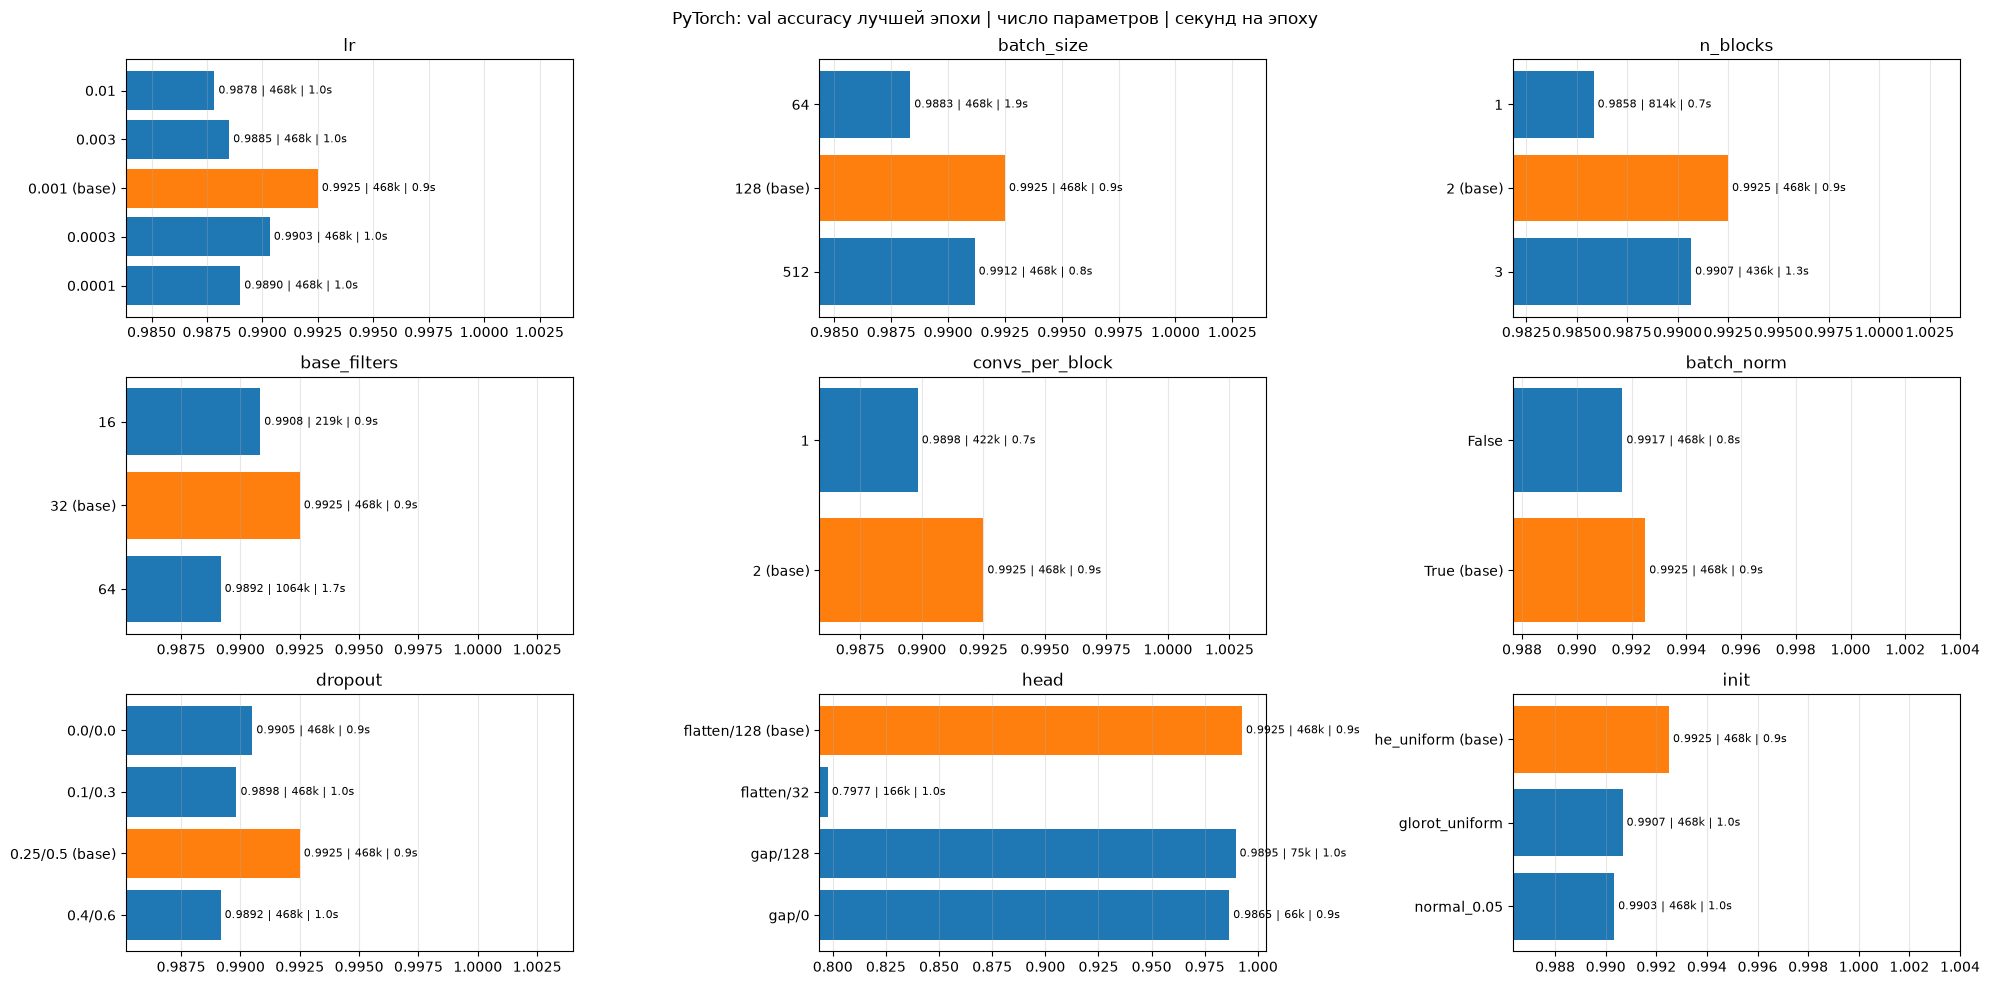

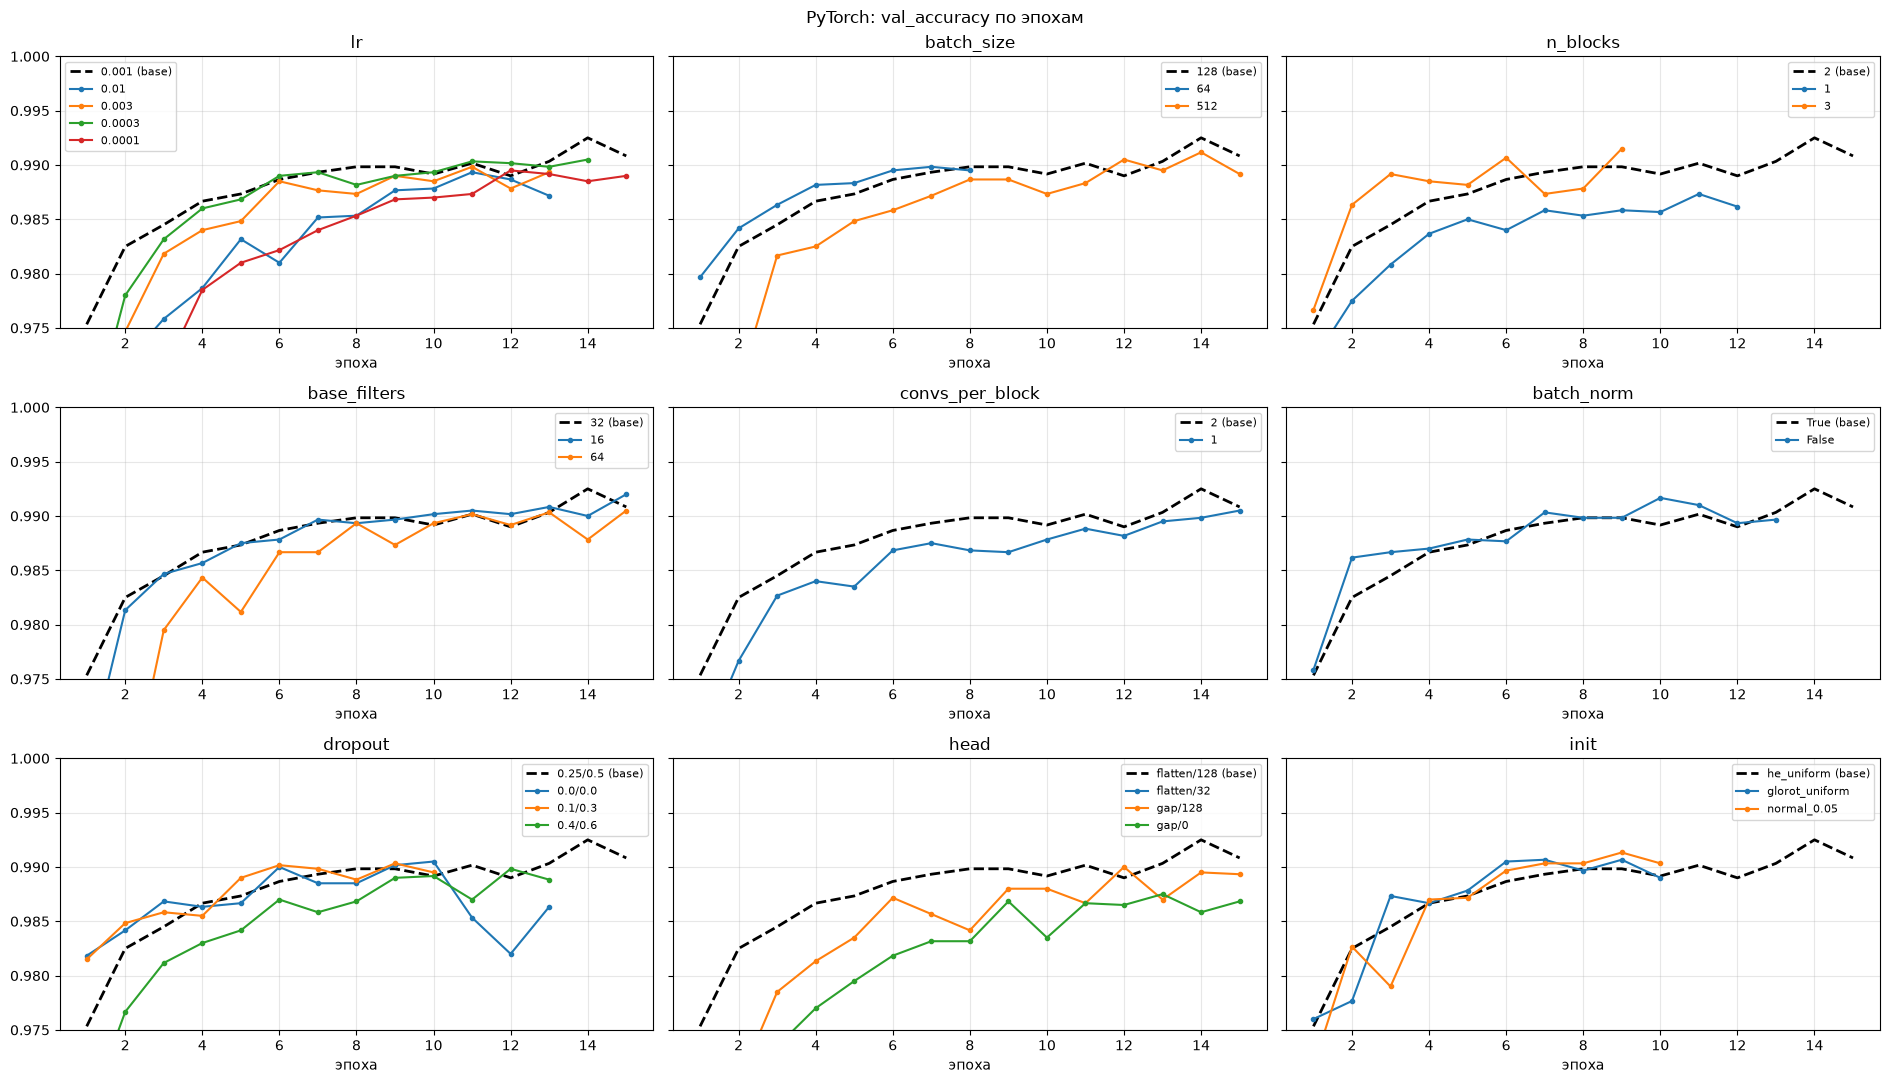

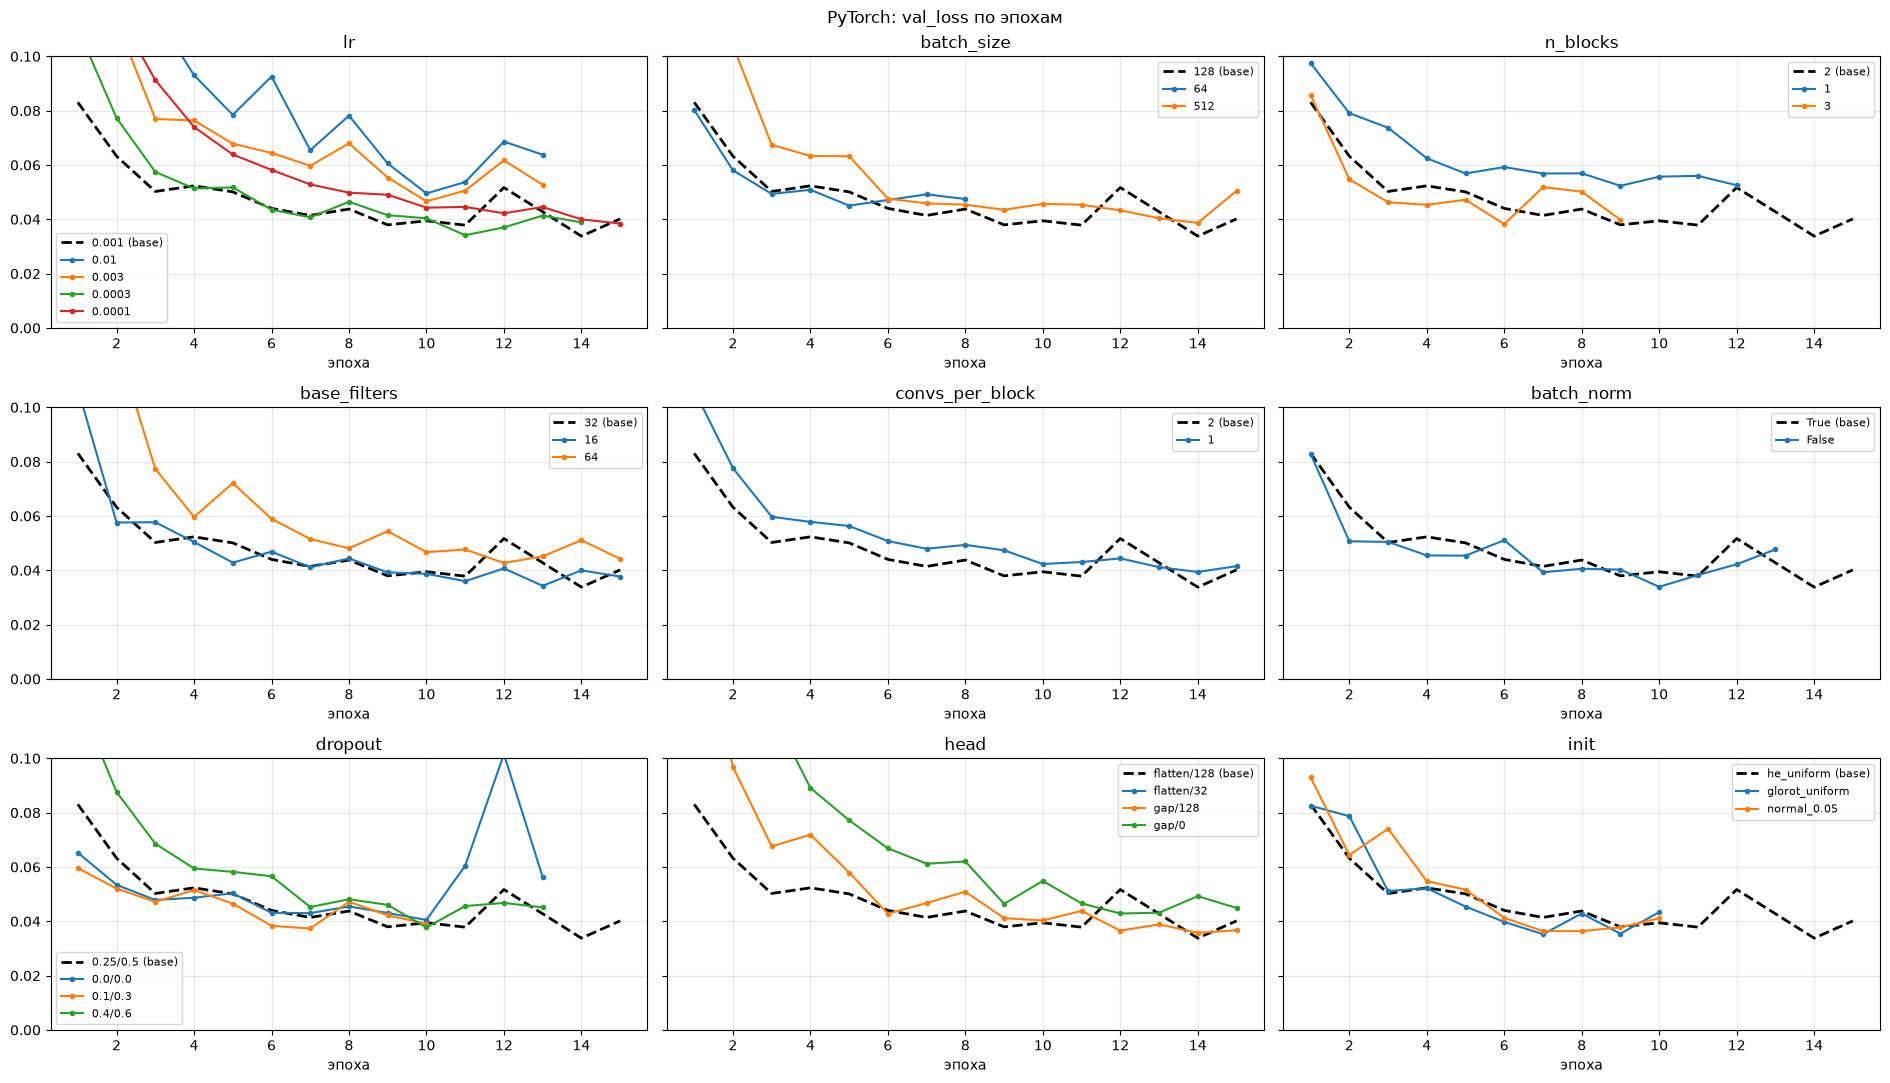

In [26]:
plot_series_bars(res_t, "PyTorch")
plot_series_curves(curves_t, "PyTorch", "val_accuracy", ylim=(0.975, 1.0))
plot_series_curves(curves_t, "PyTorch", "val_loss", ylim=(0.0, 0.1))

В PyTorch база (0,9925) оказалась лучше всех вариантов. Хуже всего flatten/32 (0,7977) и один блок (0,9858).
Эпоха базы 0,94 с против 4,6 с в Keras: в PyTorch весь датасет заранее лежит на GPU. Серия заняла 5,1 мин.

### 2.3 Сравнение серий и влияние гиперпараметров

Ниже таблица val accuracy Keras и PyTorch по каждому варианту, график в параллельных координатах
(одна линия - одно обучение, цвет - val accuracy) и два графика "размер или время против точности".

In [27]:
res_all = pd.concat([res_k, res_t], ignore_index=True)
res_all.to_csv(ART_DIR / "results_all.csv", index=False)

cmp = res_all.pivot_table(index=["group", "variant"], columns="framework",
                          values=["val_acc", "best_epoch", "s_per_epoch"], aggfunc="first")
cmp = cmp.reindex([(g, v) for g, v, _ in SERIES])                     # порядок как в серии
cmp.columns = [f"{m}_{fw}" for m, fw in cmp.columns]
cmp["params"] = res_k.set_index(["group", "variant"])["params"]
display(cmp.round(4))
print("корреляция val_acc Keras и PyTorch по вариантам:",
      round(np.corrcoef(cmp["val_acc_keras"], cmp["val_acc_pytorch"])[0, 1], 3))

best_epoch_keras  best_epoch_pytorch  \
group           variant                                                
base            base                           6                  14   
lr              0.01                          15                  10   
                0.003                         13                  10   
                0.0003                        10                  11   
                0.0001                        15                  15   
batch_size      64                            12                   5   
                512                           15                  14   
n_blocks        1                             12                   9   
                3                              6                   6   
base_filters    16                            12                  13   
                64                            15                  12   
convs_per_block 1                             15                  14   
batch_norm      False                         11                  10   
dropout         0.0/0.0                        3                  10   
                0.1/0.3                        7                   7   
                0.4/0.6                        8                  10   
head            flatten/32                    15                  15   
                gap/128                       13                  14   
                gap/0                         15                  12   
init            glorot_uniform                11                   7   
                normal_0.05                    8                   7   

                                s_per_epoch_keras  s_per_epoch_pytorch  \
group           variant                                                  
base            base                       4.6051               0.9401   
lr              0.01                       4.5934               0.9641   
                0.003                      4.6136               0.9708   
                0.0003                     4.5922               0.9691   
                0.0001                     4.6064               0.9795   
batch_size      64                         9.0656               1.8547   
                512                        2.0252               0.8465   
n_blocks        1                          3.1464               0.6647   
                3                          6.2226               1.2738   
base_filters    16                         4.6074               0.9412   
                64                         5.4000               1.6500   
convs_per_block 1                          3.3659               0.7128   
batch_norm      False                      3.2179               0.8394   
dropout         0.0/0.0                    4.3883               0.8954   
                0.1/0.3                    4.6381               0.9727   
                0.4/0.6                    4.6398               0.9776   
head            flatten/32                 4.6291               0.9956   
                gap/128                    4.6750               1.0312   
                gap/0                      4.4036               0.9320   
init            glorot_uniform             4.6303               0.9897   
                normal_0.05                4.6475               0.9907   

                                val_acc_keras  val_acc_pytorch   params  
group           variant                                                  
base            base                   0.9895           0.9925   468010  
lr              0.01                   0.9843           0.9878   468010  
                0.003                  0.9912           0.9885   468010  
                0.0003                 0.9912           0.9903   468010  
                0.0001                 0.9895           0.9890   468010  
batch_size      64                     0.9940           0.9883   468010  
                512                    0.9895           0.9912   468010  
n_bloc

корреляция val_acc Keras и PyTorch по вариантам: 0.768


In [28]:
import plotly.express as px   # https://plotly.com/python/parallel-coordinates-plot/


def parallel_plot(df: pd.DataFrame, title: str):
    """Параллельные координаты: каждая линия - одно обучение, цвет - val accuracy."""
    pc = df.copy()
    pc["framework (0=keras, 1=torch)"] = (pc["framework"] == "pytorch").astype(int)
    pc["log10(lr)"] = np.log10(pc["lr"].astype(float))
    pc["batch_norm"] = pc["batch_norm"].astype(float)
    pc["head (0=flatten, 1=gap)"] = (pc["head_type"] == "gap").astype(int)
    pc["init (0=he, 1=glorot, 2=normal)"] = pc["init"].map({"he_uniform": 0, "glorot_uniform": 1, "normal_0.05": 2})
    pc["aug (0=none ... 5=strong)"] = pc["aug"].map({k: i for i, k in enumerate(AUG_PRESETS)})
    pc["log10(params)"] = np.log10(pc["params"])
    dims = ["framework (0=keras, 1=torch)", "log10(lr)", "batch_size", "n_blocks", "base_filters", "convs_per_block",
            "batch_norm", "conv_dropout", "dense_dropout", "head (0=flatten, 1=gap)", "dense_units",
            "init (0=he, 1=glorot, 2=normal)", "aug (0=none ... 5=strong)", "log10(params)", "s_per_epoch", "val_acc"]
    dims = [d for d in dims if pc[d].notna().all()]
    fig = px.parallel_coordinates(pc, dimensions=dims, color="val_acc", color_continuous_scale="Viridis",
                                  range_color=[pc["val_acc"].quantile(0.1), pc["val_acc"].max()], title=title)
    fig.show()


parallel_plot(res_all, f"Влияние гиперпараметров на val accuracy ({len(res_all)} обучений серии)")

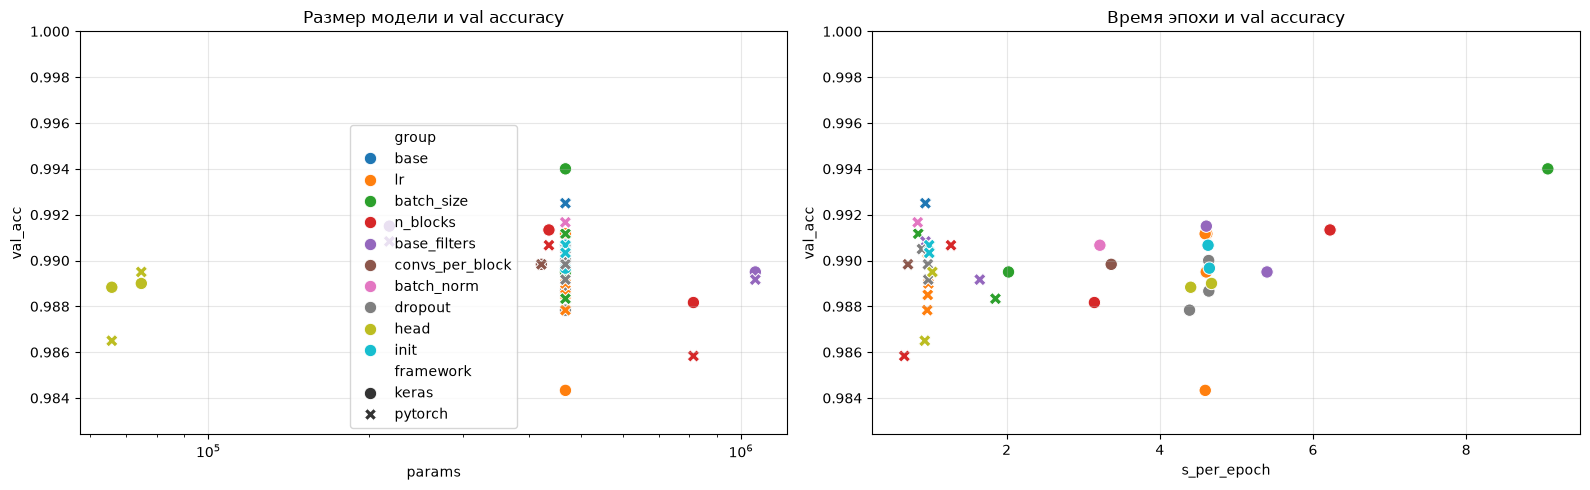

In [29]:
fig, ax = plt.subplots(1, 2, figsize=(16, 5))
sns.scatterplot(data=res_all, x="params", y="val_acc", hue="group", style="framework", s=80, ax=ax[0])
ax[0].set_xscale("log"); ax[0].set_title("Размер модели и val accuracy"); ax[0].grid(alpha=.3)
ax[0].set_ylim(res_all["val_acc"].quantile(0.05) - 0.002, 1.0)
sns.scatterplot(data=res_all, x="s_per_epoch", y="val_acc", hue="group", style="framework", s=80, ax=ax[1], legend=False)
ax[1].set_title("Время эпохи и val accuracy"); ax[1].grid(alpha=.3)
ax[1].set_ylim(res_all["val_acc"].quantile(0.05) - 0.002, 1.0)
plt.tight_layout(); plt.show()

In [30]:
def describe_series(df: pd.DataFrame, framework: str) -> None:
    """Сводка по группам: лучшее и худшее значение, разброс точности, размер и время."""
    base = df[df["group"] == "base"].iloc[0]
    print(f"=== {framework}: база val_acc {base['val_acc']:.4f}, {base['params']:,} параметров, "
          f"лучшая эпоха {base['best_epoch']}, {base['s_per_epoch']:.1f} с/эпоху")
    for group in GRID:
        sub = group_view(df, group)
        b, w = sub.loc[sub["val_acc"].idxmax()], sub.loc[sub["val_acc"].idxmin()]
        print(f"  {group:15s}: лучше {b['label']:18s} {b['val_acc']:.4f} | хуже {w['label']:18s} {w['val_acc']:.4f} | "
              f"разброс {100 * (b['val_acc'] - w['val_acc']):.2f} п.п. | параметры {sub['params'].min():,}...{sub['params'].max():,} | "
              f"эпох до лучшей {sub['best_epoch'].min()}...{sub['best_epoch'].max()}")


describe_series(res_k, "Keras")
describe_series(res_t, "PyTorch")

=== Keras: база val_acc 0.9895, 468,010 параметров, лучшая эпоха 6, 4.6 с/эпоху
  lr             : лучше 0.003              0.9912 | хуже 0.01               0.9843 | разброс 0.68 п.п. | параметры 468,010...468,010 | эпох до лучшей 6...15
  batch_size     : лучше 64                 0.9940 | хуже 128 (base)         0.9895 | разброс 0.45 п.п. | параметры 468,010...468,010 | эпох до лучшей 6...15
  n_blocks       : лучше 3                  0.9913 | хуже 1                  0.9882 | разброс 0.32 п.п. | параметры 435,754...813,866 | эпох до лучшей 6...12
  base_filters   : лучше 16                 0.9915 | хуже 32 (base)          0.9895 | разброс 0.20 п.п. | параметры 218,586...1,063,626 | эпох до лучшей 6...15
  convs_per_block: лучше 1                  0.9898 | хуже 2 (base)           0.9895 | разброс 0.03 п.п. | параметры 421,738...468,010 | эпох до лучшей 6...15
  batch_norm     : лучше False              0.9907 | хуже True (base)        0.9895 | разброс 0.12 п.п. | параметры 467,818...46

Кроме flatten/32, все варианты дают на валидации от 0,9843 до 0,9940, и порядок вариантов в двух фреймворках часто разный.
Например, батч 64 лучший в Keras (0,9940) и один из худших в PyTorch (0,9883). Корреляция val_acc между фреймворками 0,768.
Поэтому доверяю только тому, что повторилось в обоих:
* голова flatten/32 хуже всех (0,9798 и 0,7977);
* один блок хуже базы (0,9882 и 0,9858);
* lr 1e-2 хуже базы (0,9843 и 0,9878);
* от инициализации результат почти не зависит.

train_acc у многих вариантов ниже val_acc, потому что на обучающей выборке точность считается с включённым dropout.

### 2.4 Контроль переобучения

Обучаю в PyTorch базовую модель с dropout и без него, 25 эпох без ранней остановки.
Вертикальные линии на графике показывают, где сработала бы ранняя остановка.

без dropout       : min val_loss 0.0391 на эпохе 9, в конце 0.0447 | train_loss в конце 0.00175 | val_acc в конце 0.9915 | ранняя остановка сработала бы на эпохе 8
с dropout (база)  : min val_loss 0.0282 на эпохе 19, в конце 0.0341 | train_loss в конце 0.02745 | val_acc в конце 0.9928 | ранняя остановка сработала бы на эпохе 12


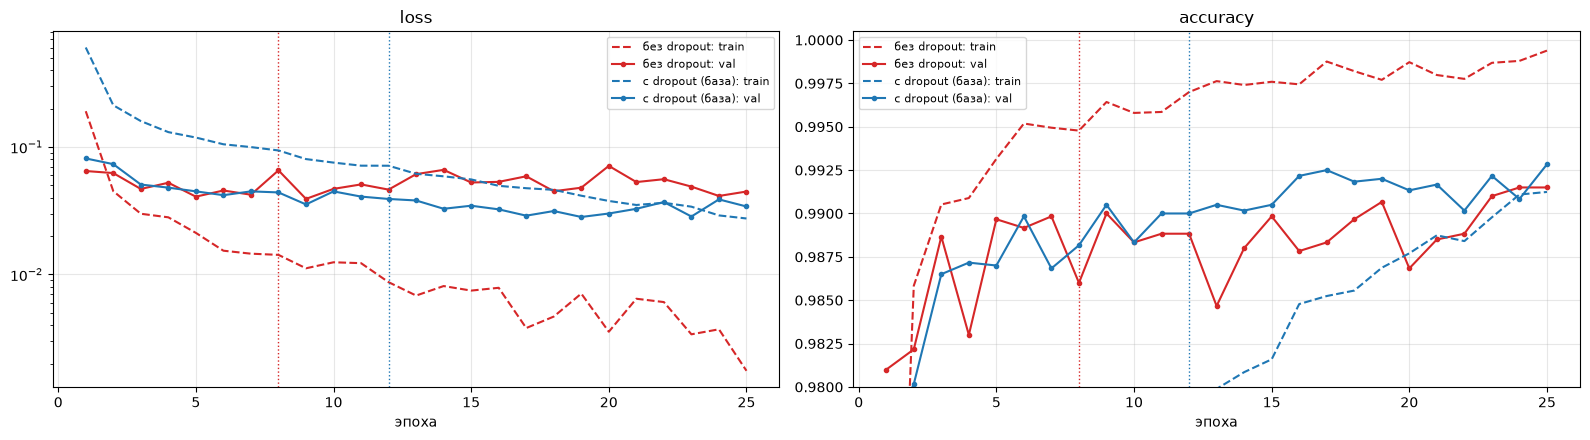

In [31]:
DEMO_EPOCHS = 6 if FAST else 25
demo = {}
for name, extra in (("без dropout", dict(conv_dropout=0.0, dense_dropout=0.0)), ("с dropout (база)", {})):
    cfg = {**BASE, **extra, "max_epochs": DEMO_EPOCHS, "early_stopping": False}
    _, demo[name], _, _ = train_torch(cfg, name, group="overfit_demo")


def es_stop_epoch(val_loss: list, patience: int) -> int:
    """Эпоха (с 1), на которой сработала бы ранняя остановка с таким терпением."""
    best, wait = float("inf"), 0
    for e, v in enumerate(val_loss, 1):
        best, wait = (v, 0) if v < best else (best, wait + 1)
        if wait >= patience:
            return e
    return len(val_loss)


fig, ax = plt.subplots(1, 2, figsize=(16, 4.5))
for (name, h), color in zip(demo.items(), ("tab:red", "tab:blue")):
    ep = np.arange(1, len(h["loss"]) + 1)
    ax[0].plot(ep, h["loss"], "--", color=color, label=f"{name}: train")
    ax[0].plot(ep, h["val_loss"], "-o", ms=3, color=color, label=f"{name}: val")
    ax[1].plot(ep, h["accuracy"], "--", color=color, label=f"{name}: train")
    ax[1].plot(ep, h["val_accuracy"], "-o", ms=3, color=color, label=f"{name}: val")
    stop = es_stop_epoch(h["val_loss"], PATIENCE)
    for a in ax:
        a.axvline(stop, color=color, ls=":", lw=1)
    print(f"{name:18s}: min val_loss {min(h['val_loss']):.4f} на эпохе {int(np.argmin(h['val_loss'])) + 1}, "
          f"в конце {h['val_loss'][-1]:.4f} | train_loss в конце {h['loss'][-1]:.5f} | "
          f"val_acc в конце {h['val_accuracy'][-1]:.4f} | ранняя остановка сработала бы на эпохе {stop}")
ax[0].set_title("loss"); ax[0].set_yscale("log"); ax[1].set_title("accuracy"); ax[1].set_ylim(0.98, 1.0005)
for a in ax:
    a.grid(alpha=.3); a.legend(fontsize=8); a.set_xlabel("эпоха")
plt.tight_layout(); plt.show()

Без dropout train_loss к концу падает до 0,00175, а val_loss после минимума 0,0391 на 9-й эпохе растёт до 0,0447.
Это переобучение. С dropout минимум val_loss 0,0282 на 19-й эпохе.

Против переобучения в работе использую отдельную валидацию (тест проверяю один раз), раннюю остановку с возвратом лучших весов,
dropout, `ReduceLROnPlateau`, модели с GAP и аугментацию.

### 2.5 Ускорение обучения

Сравниваю время эпохи базовой модели PyTorch в float32 и со смешанной точностью (AMP).

In [32]:
if DEVICE.type == "cuda":
    bench = []
    for amp in (False, True):
        _, h, _, _ = train_torch({**BASE, "max_epochs": 4, "early_stopping": False}, f"amp={amp}", group="speed", amp=amp)
        bench.append(dict(AMP=amp, s_per_epoch=float(np.median(h["epoch_time"][1:])),   # 1-я эпоха - прогрев
                          val_acc_after_4_epochs=h["val_accuracy"][-1]))
    bench = pd.DataFrame(bench)
    bench["ускорение"] = bench["s_per_epoch"].iloc[0] / bench["s_per_epoch"]
    display(bench.round(4))
else:
    print("AMP (float16) ускоряет только на GPU, на CPU замер пропускаю")

bs = res_all[res_all["group"].isin(["batch_size", "base"])]
display(bs.pivot_table(index="batch_size", columns="framework", values=["s_per_epoch", "val_acc", "best_epoch"]).round(4))

,AMP,s_per_epoch,val_acc_after_4_epochs,ускорение
0,False,0.9971,0.9853,1.0000
1,True,1.2595,0.9877,0.7917


best_epoch         s_per_epoch         val_acc        
framework       keras pytorch       keras pytorch   keras pytorch
batch_size                                                       
64               12.0     5.0      9.0656  1.8547  0.9940  0.9883
128               6.0    14.0      4.6051  0.9401  0.9895  0.9925
512              15.0    14.0      2.0252  0.8465  0.9895  0.9912

AMP тут замедлил обучение: 1,2595 с на эпоху против 0,9971 с. Сеть маленькая, и выигрыша от float16 не видно.
Сильнее влияет размер батча: в Keras эпоха 9,1 с при батче 64 и 2,0 с при 512. Ещё ускоряют обучение данные, заранее
лежащие на GPU (так сделано в PyTorch), ранняя остановка и меньшее число слоёв.

### 2.6 Итоговые модели (максимум качества)

Сборка лучших значений из разных групп не обязательно даёт лучшую модель, поэтому обучаю кандидатов дольше
(до `FINAL_EPOCHS` эпох, lr уменьшается на плато): combo (лучшее значение из каждой группы), лучший одиночный прогон и base.
Итоговая модель выбирается по валидации, на тесте проверяю только её.

In [33]:
def stage2_candidates(df: pd.DataFrame) -> tuple[dict, pd.DataFrame]:
    """Кандидаты второго этапа: сборка лучших значений групп, лучший одиночный прогон, база (без повторов)."""
    combo, choice = best_config(df)
    top = df.loc[df["val_acc"].idxmax()]
    single = {**BASE, **{k: py(top[k]) for k in HP_KEYS}}
    named = [("combo", combo), (f"best_run {top['group']}={top['variant']}", single), ("base", dict(BASE))]
    cands, seen = {}, set()
    for name, cfg in named:
        key = tuple(cfg[k] for k in HP_KEYS)
        if key not in seen:                      # одинаковые конфигурации обучаю один раз
            seen.add(key)
            cands[name] = {**cfg, "max_epochs": FINAL_EPOCHS, "patience": FINAL_PATIENCE,
                           "early_stopping": True, "reduce_lr": True}
    return cands, choice


def pick_final(stage2: pd.DataFrame, tol: float = 5e-4) -> str:
    """Лучший кандидат по val_acc, при разнице до tol - с меньшим числом параметров."""
    top = stage2[stage2["val_acc"] >= stage2["val_acc"].max() - tol]
    return top.sort_values(["params", "val_acc"], ascending=[True, False]).iloc[0]["variant"]


STAGE2_COLS = ["variant", "val_acc", "val_loss", "train_acc", "best_epoch", "epochs", "params", "time_s"] + HP_KEYS
cands_k, choice_k = stage2_candidates(res_k)
cands_t, choice_t = stage2_candidates(res_t)
print("Выбор по группам, Keras:");   display(choice_k)
print("Выбор по группам, PyTorch:"); display(choice_t)

Выбор по группам, Keras:


,group,base,chosen,val_acc_chosen,val_acc_best,params
0,lr,0.001,0.003,0.991167,0.991167,468010
1,batch_size,128,64,0.994000,0.994000,468010
2,n_blocks,2,3,0.991333,0.991333,435754
3,base_filters,32,16,0.991500,0.991500,218586
4,convs_per_block,2,1,0.989833,0.989833,421738
5,batch_norm,True,False,0.990667,0.990667,467818
6,dropout,0.25/0.5,0.1/0.3,0.990000,0.990000,468010
7,head,flatten/128,gap/128,0.989000,0.989500,74794
8,init,he_uniform,glorot_uniform,0.990667,0.990667,468010


Выбор по группам, PyTorch:


,group,base,chosen,val_acc_chosen,val_acc_best,params
0,lr,0.001,0.001,0.9925,0.9925,468010
1,batch_size,128,128,0.9925,0.9925,468010
2,n_blocks,2,2,0.9925,0.9925,468010
3,base_filters,32,32,0.9925,0.9925,468010
4,convs_per_block,2,2,0.9925,0.9925,468010
5,batch_norm,True,True,0.9925,0.9925,468010
6,dropout,0.25/0.5,0.25/0.5,0.9925,0.9925,468010
7,head,flatten/128,flatten/128,0.9925,0.9925,468010
8,init,he_uniform,he_uniform,0.9925,0.9925,468010


In [34]:
def test_report(y_true: np.ndarray, logits: np.ndarray, title: str, plots: bool = True) -> float:
    """accuracy на тесте; при plots=True ещё classification report, матрица ошибок и самые уверенные ошибки."""
    proba = softmax(logits)
    pred = proba.argmax(axis=1)
    acc = accuracy_score(y_true, pred)
    print(f"{title}: test accuracy = {acc:.4f} (ошибок: {(pred != y_true).sum()} из {len(y_true)})")
    if not plots:
        return acc
    print(classification_report(y_true, pred, digits=4))

    cm = confusion_matrix(y_true, pred)
    off = cm.copy(); np.fill_diagonal(off, 0)
    fig, ax = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [1, 1.2]})
    sns.heatmap(off, annot=True, fmt="d", cmap="Reds", cbar=False, ax=ax[0])
    ax[0].set_xlabel("предсказано"); ax[0].set_ylabel("истина"); ax[0].set_title("Матрица ошибок (без диагонали)")
    pairs = pd.DataFrame([(t, p, off[t, p]) for t in range(10) for p in range(10) if off[t, p] > 0],
                         columns=["истина", "предсказано", "ошибок"]).sort_values("ошибок", ascending=False).head(8)
    ax[1].axis("off"); ax[1].table(cellText=pairs.values, colLabels=pairs.columns, loc="center").scale(1, 1.6)
    ax[1].set_title("Самые частые путаницы"); plt.tight_layout(); plt.show()

    wrong = np.flatnonzero(pred != y_true)
    wrong = wrong[np.argsort(-proba[wrong, pred[wrong]])][:24]            # самые "уверенные" ошибки
    fig, axes = plt.subplots(3, 8, figsize=(14, 6))
    for ax_, i in zip(axes.flat, wrong):
        ax_.imshow(x_test[i], cmap="gray_r"); ax_.axis("off")
        ax_.set_title(f"ист {y_true[i]}, пред {pred[i]}\np={proba[i, pred[i]]:.2f}", fontsize=9)
    for ax_ in axes.flat[len(wrong):]:
        ax_.axis("off")
    fig.suptitle(f"{title}: самые уверенные ошибки на тесте"); plt.tight_layout(); plt.show()
    return acc


def keras_logits(model, X=None) -> np.ndarray:
    return keras.ops.convert_to_numpy(model.predict(Xk_test if X is None else X, batch_size=2048, verbose=0))

#### Keras: итоговая модель

In [35]:
rows, runs_k = [], {}
for i, (name, cfg) in enumerate(cands_k.items()):
    m, h, r, tr = train_keras(cfg, name, group="stage2")   # WandB держит один открытый прогон, закрываю сразу
    p = ART_DIR / f"keras_stage2_{i}.keras"
    m.save(str(p))                         # сохраняю каждого кандидата, чтобы потом загрузить выбранного
    rows.append(r)
    runs_k[name] = (p, h, r, tr)
    print(f"{name:34s} | val_acc {r['val_acc']:.4f} | эпох {r['epochs']} | {r['time_s']:.0f} с")
stage2_k = pd.DataFrame(rows)
display(stage2_k[STAGE2_COLS].round(4))

final_name_k = pick_final(stage2_k)
final_cfg_k = cands_k[final_name_k]
path_s2, hist_fk, row_fk, tr_fk = runs_k[final_name_k]
final_k = keras.models.load_model(str(path_s2))
print("итоговая модель Keras:", final_name_k)

combo                              | val_acc 0.9927 | эпох 21 | 126 с


best_run batch_size=64             | val_acc 0.9923 | эпох 18 | 164 с


base                               | val_acc 0.9907 | эпох 17 | 79 с


,variant,val_acc,val_loss,train_acc,best_epoch,epochs,params,time_s,lr,batch_size,...,base_filters,convs_per_block,kernel_size,batch_norm,conv_dropout,head_type,dense_units,dense_dropout,init,aug
0,combo,0.9927,0.0278,0.9923,15,21,32906,125.5682,0.003,64,...,16,1,3,False,0.10,gap,128,0.3,glorot_uniform,none
1,best_run batch_size=64,0.9923,0.0273,0.9890,12,18,468010,163.5469,0.001,64,...,32,2,3,True,0.25,flatten,128,0.5,he_uniform,none
2,base,0.9907,0.0332,0.9733,11,17,468010,78.8670,0.001,128,...,32,2,3,True,0.25,flatten,128,0.5,he_uniform,none


итоговая модель Keras: combo


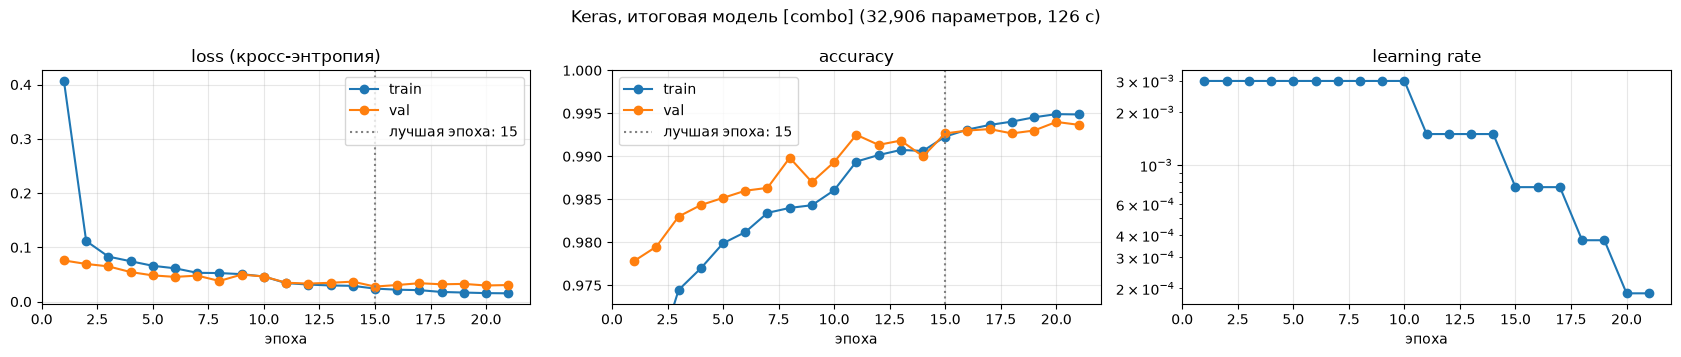

Keras final: test accuracy = 0.9929 (ошибок: 71 из 10000)
              precision    recall  f1-score   support

           0     0.9959    0.9980    0.9969       980
           1     0.9921    1.0000    0.9961      1135
           2     0.9932    0.9971    0.9952      1032
           3     0.9902    0.9980    0.9941      1010
           4     0.9979    0.9837    0.9908       982
           5     0.9944    0.9865    0.9904       892
           6     0.9958    0.9906    0.9932       958
           7     0.9932    0.9903    0.9917      1028
           8     0.9938    0.9938    0.9938       974
           9     0.9833    0.9891    0.9862      1009

    accuracy                         0.9929     10000
   macro avg     0.9930    0.9927    0.9928     10000
weighted avg     0.9929    0.9929    0.9929     10000



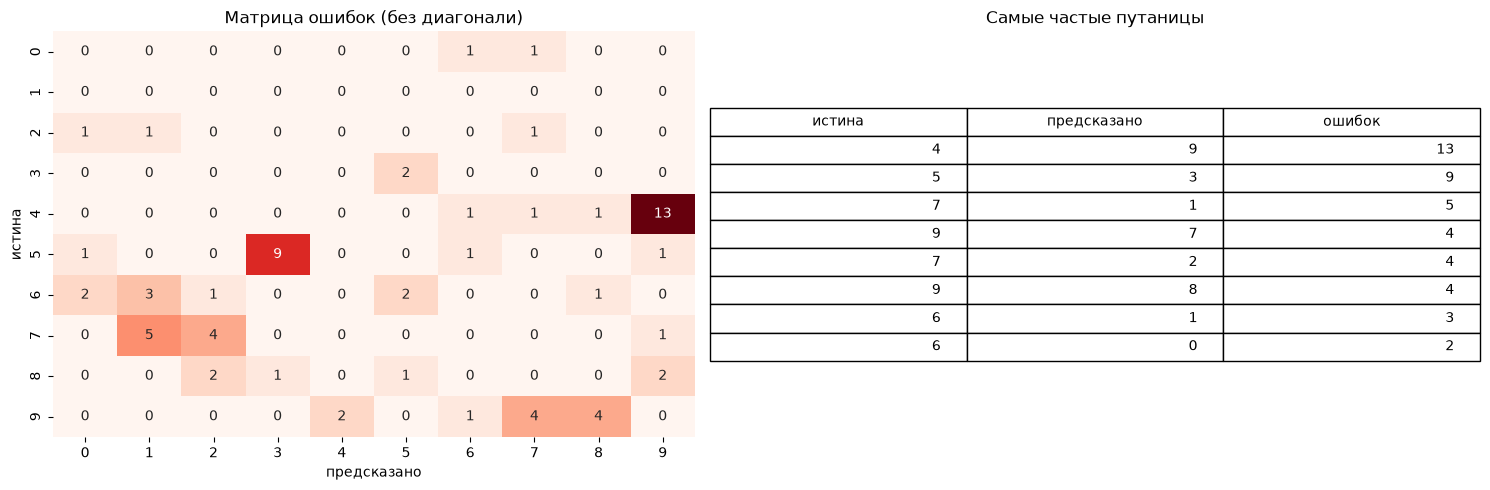

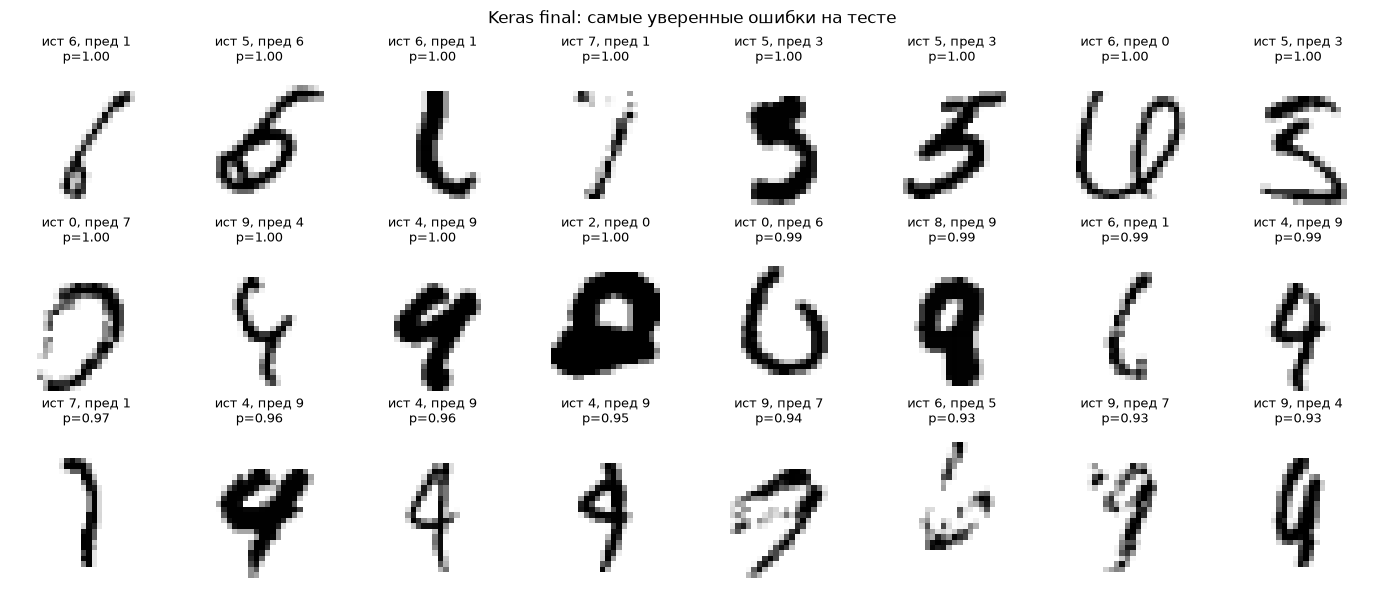

сохранено: artifacts\keras_final.keras (0.44 МБ), точность после загрузки: 0.9929


In [36]:
plot_history(hist_fk, f"Keras, итоговая модель [{final_name_k}] ({count_keras(final_k):,} параметров, {row_fk['time_s']:.0f} с)")
test_acc_fk = test_report(yk_test, keras_logits(final_k), "Keras final")
row_fk["test_acc"] = test_acc_fk          # в WandB точность на тесте попадёт в итоговую таблицу (раздел 5)

path_fk = ART_DIR / "keras_final.keras"
final_k.save(str(path_fk))                                           # архитектура + веса + состояние оптимизатора
reloaded = keras.models.load_model(str(path_fk))                     # проверяю, что загруженная модель даёт то же самое
acc_reloaded = accuracy_score(yk_test, keras_logits(reloaded).argmax(1))
print(f"сохранено: {path_fk} ({path_fk.stat().st_size / 2**20:.2f} МБ), точность после загрузки: {acc_reloaded:.4f}")

#### PyTorch: итоговая модель

In [37]:
def save_torch(model: TorchCNN, cfg: dict, path: Path) -> None:
    """Сохраняю веса, cfg (по нему восстанавливается архитектура) и параметры нормализации входа."""
    torch.save({"state_dict": model.state_dict(), "cfg": {k: cfg[k] for k in HP_KEYS + ["kernel_size"]},
                "mean": MEAN, "std": STD}, path)


def load_torch(path: Path) -> TorchCNN:
    ckpt = torch.load(path, map_location=DEVICE, weights_only=True)
    model = TorchCNN(ckpt["cfg"]).to(DEVICE)
    model.load_state_dict(ckpt["state_dict"])
    return model.eval()


rows, runs_t = [], {}
for name, cfg in cands_t.items():
    m, h, r, tr = train_torch(cfg, name, group="stage2")
    rows.append(r)
    runs_t[name] = (m, h, r, tr)            # модели PyTorch маленькие, держу кандидатов в памяти
    print(f"{name:34s} | val_acc {r['val_acc']:.4f} | эпох {r['epochs']} | {r['time_s']:.0f} с")
stage2_t = pd.DataFrame(rows)
display(stage2_t[STAGE2_COLS].round(4))

final_name_t = pick_final(stage2_t)
final_cfg_t = cands_t[final_name_t]
final_t, hist_ft, row_ft, tr_ft = runs_t[final_name_t]
print("итоговая модель PyTorch:", final_name_t)

combo                              | val_acc 0.9928 | эпох 22 | 21 с


,variant,val_acc,val_loss,train_acc,best_epoch,epochs,params,time_s,lr,batch_size,...,base_filters,convs_per_block,kernel_size,batch_norm,conv_dropout,head_type,dense_units,dense_dropout,init,aug
0,combo,0.9928,0.0296,0.9844,16,22,468010,20.8954,0.001,128,...,32,2,3,True,0.25,flatten,128,0.5,he_uniform,none


итоговая модель PyTorch: combo


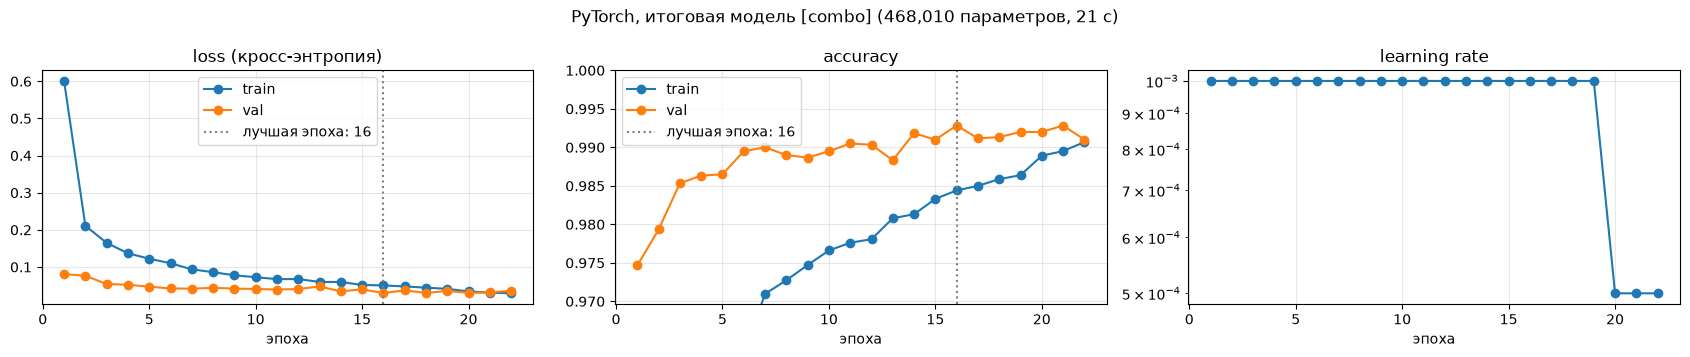

PyTorch final: test accuracy = 0.9944 (ошибок: 56 из 10000)
              precision    recall  f1-score   support

           0     0.9959    0.9980    0.9969       980
           1     0.9939    1.0000    0.9969      1135
           2     0.9952    0.9961    0.9956      1032
           3     0.9950    0.9931    0.9941      1010
           4     0.9959    0.9949    0.9954       982
           5     0.9867    0.9944    0.9905       892
           6     0.9989    0.9875    0.9932       958
           7     0.9922    0.9961    0.9942      1028
           8     0.9979    0.9897    0.9938       974
           9     0.9921    0.9931    0.9926      1009

    accuracy                         0.9944     10000
   macro avg     0.9944    0.9943    0.9943     10000
weighted avg     0.9944    0.9944    0.9944     10000



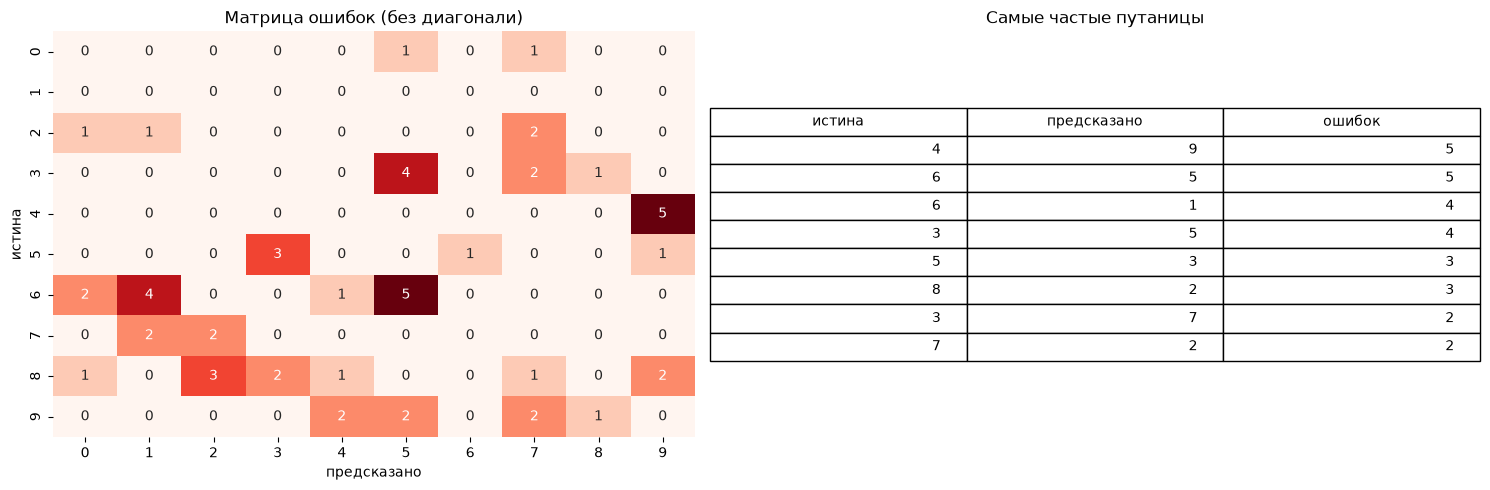

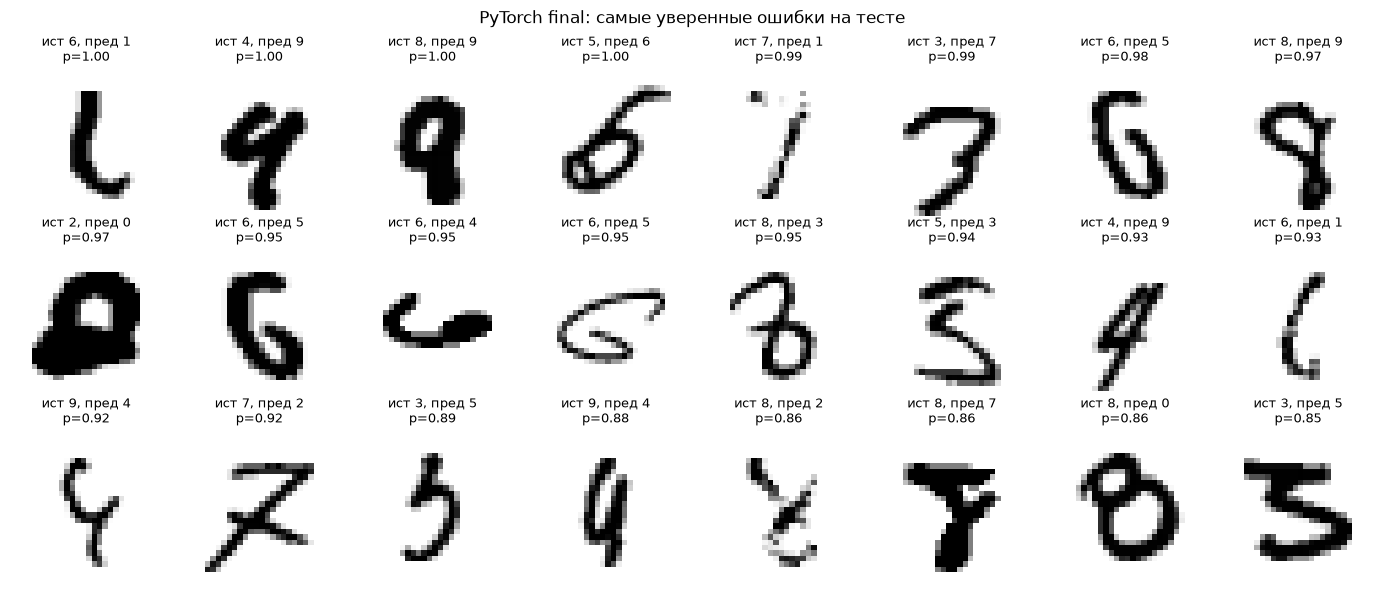

сохранено: artifacts\torch_final.pt (1.80 МБ), точность после загрузки: 0.9944


In [38]:
plot_history(hist_ft, f"PyTorch, итоговая модель [{final_name_t}] ({count_torch(final_t):,} параметров, {row_ft['time_s']:.0f} с)")
test_acc_ft = test_report(y_test, predict_torch(final_t, Xt_test), "PyTorch final")
row_ft["test_acc"] = test_acc_ft

path_ft = ART_DIR / "torch_final.pt"
save_torch(final_t, final_cfg_t, path_ft)
acc_reloaded = accuracy_score(y_test, predict_torch(load_torch(path_ft), Xt_test).argmax(1))
print(f"сохранено: {path_ft} ({path_ft.stat().st_size / 2**20:.2f} МБ), точность после загрузки: {acc_reloaded:.4f}")

В Keras победила combo: 32 906 параметров, 0,9927 на валидации и 0,9929 на тесте (71 ошибка).
В PyTorch база была лучшей в каждой группе, поэтому combo совпала с базой: 0,9928 на валидации и 0,9944 на тесте (56 ошибок).
Какие цифры сети путают, видно на матрицах ошибок.

### 2.7 Компактные модели (минимум размера)

Больше всего параметров у базы в Dense после Flatten (401 536 из 468 010). В компактной модели вместо него
Global Average Pooling и один слой Dense 64x10, три блока по две свёртки (16, 32 и 64 фильтра), dropout 0.1/0.2.
lr, батч и инициализация берутся из итоговой модели.

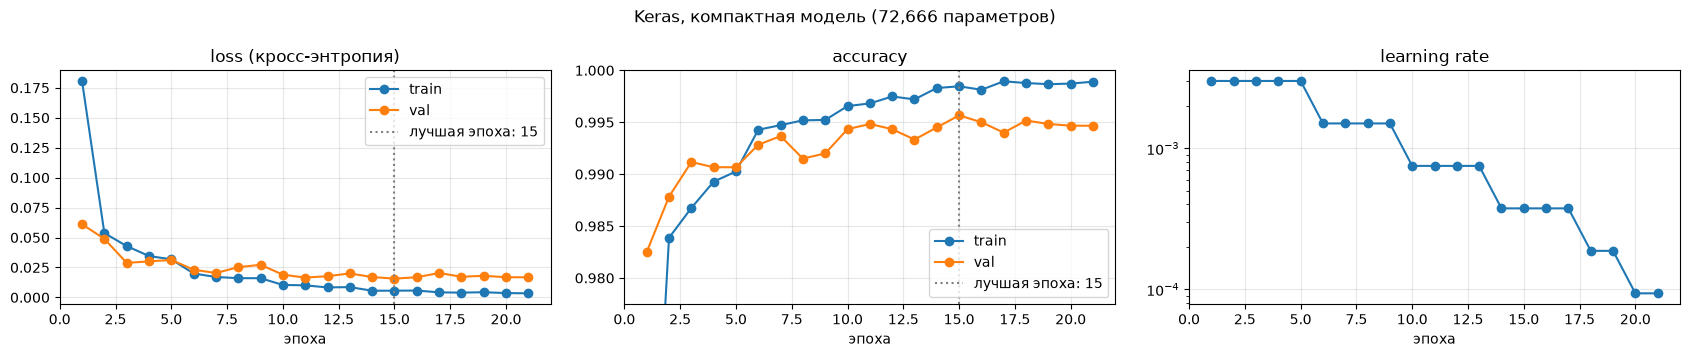

Keras compact: test accuracy = 0.9959 (ошибок: 41 из 10000)


In [39]:
def compact_from(final_cfg: dict) -> dict:
    return {**BASE, "n_blocks": 3, "base_filters": 16, "convs_per_block": 2, "batch_norm": True,
            "conv_dropout": 0.1, "head_type": "gap", "dense_units": 0, "dense_dropout": 0.2,
            "lr": final_cfg["lr"], "batch_size": final_cfg["batch_size"], "init": final_cfg["init"],
            "max_epochs": FINAL_EPOCHS, "patience": FINAL_PATIENCE, "early_stopping": True, "reduce_lr": True}


compact_cfg_k, compact_cfg_t = compact_from(final_cfg_k), compact_from(final_cfg_t)

compact_k, hist_ck, row_ck, tr = train_keras(compact_cfg_k, "compact", group="compact", keep_open=True)
plot_history(hist_ck, f"Keras, компактная модель ({count_keras(compact_k):,} параметров)")
row_ck["test_acc"] = test_report(yk_test, keras_logits(compact_k), "Keras compact", plots=False)
close_run(tr, row_ck, test_acc=row_ck["test_acc"])
path_ck = ART_DIR / "keras_compact.keras"; compact_k.save(str(path_ck))

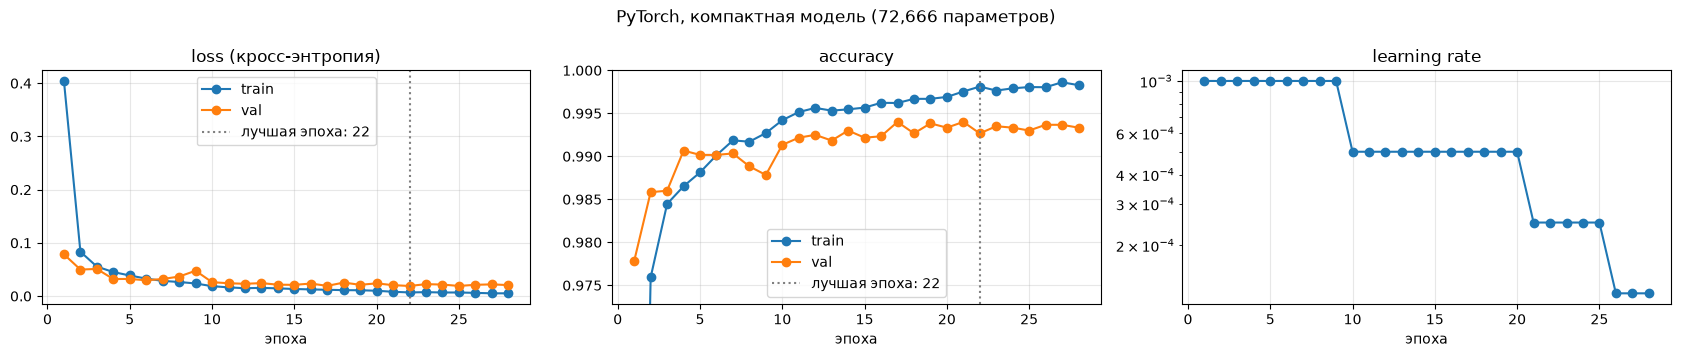

PyTorch compact: test accuracy = 0.9956 (ошибок: 44 из 10000)


In [40]:
compact_t, hist_ct, row_ct, tr = train_torch(compact_cfg_t, "compact", group="compact", keep_open=True)
plot_history(hist_ct, f"PyTorch, компактная модель ({count_torch(compact_t):,} параметров)")
row_ct["test_acc"] = test_report(y_test, predict_torch(compact_t, Xt_test), "PyTorch compact", plots=False)
close_run(tr, row_ct, test_acc=row_ct["test_acc"])
path_ct = ART_DIR / "torch_compact.pt"
save_torch(compact_t, compact_cfg_t, path_ct)

Компактные модели (72 666 параметров) на тесте точнее итоговых: 0,9959 в Keras и 0,9956 в PyTorch.
В серии OFAT голова GAP проверялась только с двумя блоками, поэтому такое сочетание там не встретилось.

### 2.8 Сколько параметров и где их больше всего

* `Conv2D`: $k_h \cdot k_w \cdot C_{in} \cdot C_{out}$, плюс $C_{out}$, если есть bias;
* `BatchNorm`: $2C$ обучаемых (γ и β) и $2C$ необучаемых (скользящие среднее и дисперсия);
* `Dense`: $N_{in} \cdot N_{out} + N_{out}$;
* у `MaxPool`, `ReLU`, `Dropout`, `Flatten`, `GAP` параметров нет.

In [41]:
def split_params(table: pd.DataFrame) -> pd.Series:
    conv = table[table["type"].isin(["Conv2D", "BatchNormalization", "Conv2d", "BatchNorm2d"])]["trainable"].sum()
    dense = table[table["type"].isin(["Dense", "Linear"])]["trainable"].sum()
    return pd.Series({"свёрточная часть": conv, "полносвязная часть": dense, "всего": conv + dense,
                      "доля свёрточной, %": round(100 * conv / (conv + dense), 1)})


final_k = keras.models.load_model(str(path_fk))   # заново из файла, чтобы не зависеть от clear_session() в других обучениях
tables = {
    "base (Keras)": keras_base_table,
    "final (Keras)": keras_param_table(final_k),
    "compact (Keras)": keras_param_table(compact_k),
    "final (PyTorch)": torch_param_table(final_t),
    "compact (PyTorch)": torch_param_table(compact_t),
}
display(pd.DataFrame({name: split_params(t) for name, t in tables.items()}).T)
for name, t in tables.items():
    top = t.nlargest(3, "trainable")
    print(f"{name:18s} самые тяжёлые слои: " +
          "; ".join(f"{r['layer']} ({r['type']}) {r['trainable']:,} = {r['share_%']:.1f}%" for _, r in top.iterrows()))

,свёрточная часть,полносвязная часть,всего,"доля свёрточной, %"
base (Keras),65184.0,402826.0,468010.0,13.9
final (Keras),23296.0,9610.0,32906.0,70.8
compact (Keras),72016.0,650.0,72666.0,99.1
final (PyTorch),65184.0,402826.0,468010.0,13.9
compact (PyTorch),72016.0,650.0,72666.0,99.1


base (Keras)       самые тяжёлые слои: fc (Dense) 401,536 = 85.8%; b2_conv2 (Conv2D) 36,864 = 7.9%; b2_conv1 (Conv2D) 18,432 = 3.9%
final (Keras)      самые тяжёлые слои: b3_conv1 (Conv2D) 18,496 = 56.2%; fc (Dense) 8,320 = 25.3%; b2_conv1 (Conv2D) 4,640 = 14.1%
compact (Keras)    самые тяжёлые слои: b3_conv2 (Conv2D) 36,864 = 50.7%; b3_conv1 (Conv2D) 18,432 = 25.4%; b2_conv2 (Conv2D) 9,216 = 12.7%
final (PyTorch)    самые тяжёлые слои: head.0 (Linear) 401,536 = 85.8%; features.11 (Conv2d) 36,864 = 7.9%; features.8 (Conv2d) 18,432 = 3.9%
compact (PyTorch)  самые тяжёлые слои: features.19 (Conv2d) 36,864 = 50.7%; features.16 (Conv2d) 18,432 = 25.4%; features.11 (Conv2d) 9,216 = 12.7%


In [42]:
print("Итоговая модель Keras по слоям:")
display(tables["final (Keras)"])
print("Компактная модель Keras по слоям:")
display(tables["compact (Keras)"])

Итоговая модель Keras по слоям:


,layer,type,output,trainable,non_trainable,share_%
0,b1_conv1,Conv2D,"(28, 28, 16)",160,0,0.49
1,b1_relu1,ReLU,"(28, 28, 16)",0,0,0.00
2,b1_pool,MaxPooling2D,"(14, 14, 16)",0,0,0.00
3,b1_drop,Dropout,"(14, 14, 16)",0,0,0.00
4,b2_conv1,Conv2D,"(14, 14, 32)",4640,0,14.10
5,b2_relu1,ReLU,"(14, 14, 32)",0,0,0.00
6,b2_pool,MaxPooling2D,"(7, 7, 32)",0,0,0.00
7,b2_drop,Dropout,"(7, 7, 32)",0,0,0.00
8,b3_conv1,Conv2D,"(7, 7, 64)",18496,0,56.21
9,b3_relu1,ReLU,"(7, 7, 64)",0,0,0.00


Компактная модель Keras по слоям:


,layer,type,output,trainable,non_trainable,share_%
0,b1_conv1,Conv2D,"(28, 28, 16)",144,0,0.20
1,b1_bn1,BatchNormalization,"(28, 28, 16)",32,32,0.04
2,b1_relu1,ReLU,"(28, 28, 16)",0,0,0.00
3,b1_conv2,Conv2D,"(28, 28, 16)",2304,0,3.17
4,b1_bn2,BatchNormalization,"(28, 28, 16)",32,32,0.04
5,b1_relu2,ReLU,"(28, 28, 16)",0,0,0.00
6,b1_pool,MaxPooling2D,"(14, 14, 16)",0,0,0.00
7,b1_drop,Dropout,"(14, 14, 16)",0,0,0.00
8,b2_conv1,Conv2D,"(14, 14, 32)",4608,0,6.34
9,b2_bn1,BatchNormalization,"(14, 14, 32)",64,64,0.09


У базы 85,8% параметров в одном слое Dense после Flatten. У итоговой модели Keras самый тяжёлый слой
свёртка третьего блока (56,2%). У компактной на свёртки приходится 99,1%, больше всего весит последняя свёртка (50,7%).
Чтобы уменьшить модель, нужно убрать большой Dense после Flatten и не увеличивать число фильтров без нужды.

## 3. Аугментация

Аугментация на каждой эпохе случайно поворачивает, сдвигает и масштабирует обучающие картинки, метка остаётся прежней.
Так сеть меньше запоминает конкретные картинки. Пресеты: `rot` (поворот до 10°), `shift` (сдвиг до 10%), `zoom` (масштаб ±10%),
`all` (все три сразу) и `strong` (40°, 25%, ±30%), чтобы посмотреть на слишком сильную аугментацию.
Отражать цифры нельзя, а сильный поворот превращает 6 в 9.

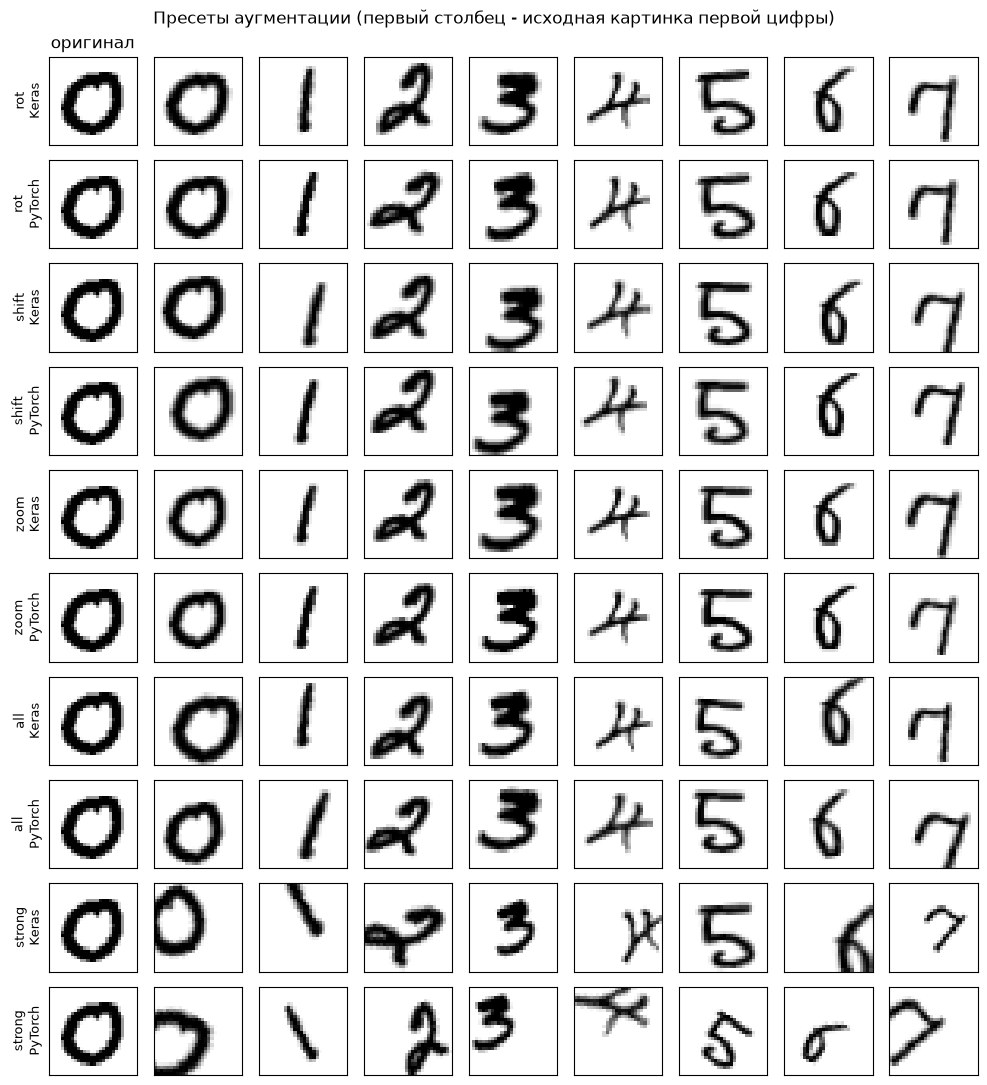

In [43]:
# как выглядят пресеты. Keras: слои аугментации вызываю с training=True; PyTorch: augment_torch
sample = np.concatenate([np.flatnonzero(y_val == d)[:1] for d in range(10)])[:8]
presets = [p for p in AUG_PRESETS if p != "none"]
fig, axes = plt.subplots(2 * len(presets), 9, figsize=(10, 2.1 * len(presets) * 1.05))
for r, p in enumerate(presets):
    xk = keras.ops.convert_to_tensor(Xk_val[sample])
    for l in keras_aug_layers(p):
        xk = l(xk, training=True)
    xk = keras.ops.convert_to_numpy(xk)[..., 0]
    torch.manual_seed(r)
    xt = augment_torch(Xt_val[sample], p).cpu().numpy()[:, 0]
    for rr, (imgs, fw) in enumerate(((xk, "Keras"), (xt, "PyTorch"))):
        row = 2 * r + rr
        axes[row, 0].imshow(Xk_val[sample[0], ..., 0], cmap="gray_r"); axes[row, 0].set_ylabel(f"{p}\n{fw}", fontsize=9)
        for j in range(8):
            axes[row, j + 1].imshow(imgs[j], cmap="gray_r", vmin=BG, vmax=(1 - MEAN) / STD)
for a in axes.flat:
    a.set_xticks([]); a.set_yticks([])
axes[0, 0].set_title("оригинал"); fig.suptitle("Пресеты аугментации (первый столбец - исходная картинка первой цифры)")
plt.tight_layout(); plt.show()

### 3.1 Какие преобразования помогают (PyTorch, базовая модель)

Обучаю базовую конфигурацию с каждым пресетом, всем даю `FINAL_EPOCHS` эпох и уменьшение lr на плато.

none    | val_acc 0.9930 | val_loss 0.0309 | train_acc 0.9864 | лучшая эпоха 16/22 | 0.99 с/эп | всего 22 с


rot     | val_acc 0.9928 | val_loss 0.0246 | train_acc 0.9888 | лучшая эпоха 26/30 | 1.23 с/эп | всего 37 с


shift   | val_acc 0.9935 | val_loss 0.0216 | train_acc 0.9865 | лучшая эпоха 28/30 | 1.23 с/эп | всего 37 с


zoom    | val_acc 0.9923 | val_loss 0.0289 | train_acc 0.9814 | лучшая эпоха 13/19 | 1.23 с/эп | всего 24 с


all     | val_acc 0.9942 | val_loss 0.0175 | train_acc 0.9873 | лучшая эпоха 28/30 | 1.25 с/эп | всего 38 с


strong  | val_acc 0.9815 | val_loss 0.0627 | train_acc 0.9216 | лучшая эпоха 23/29 | 1.24 с/эп | всего 36 с


,variant,val_acc,val_loss,train_acc,gap,best_epoch,epochs,s_per_epoch,time_s
0,none,0.9930,0.0309,0.9864,-0.0066,16,22,0.9865,22.0624
1,rot,0.9928,0.0246,0.9888,-0.0041,26,30,1.2280,36.9054
2,shift,0.9935,0.0216,0.9865,-0.0070,28,30,1.2288,36.9200
3,zoom,0.9923,0.0289,0.9814,-0.0110,13,19,1.2309,23.5686
4,all,0.9942,0.0175,0.9873,-0.0069,28,30,1.2461,37.5715
5,strong,0.9815,0.0627,0.9216,-0.0599,23,29,1.2351,35.9839


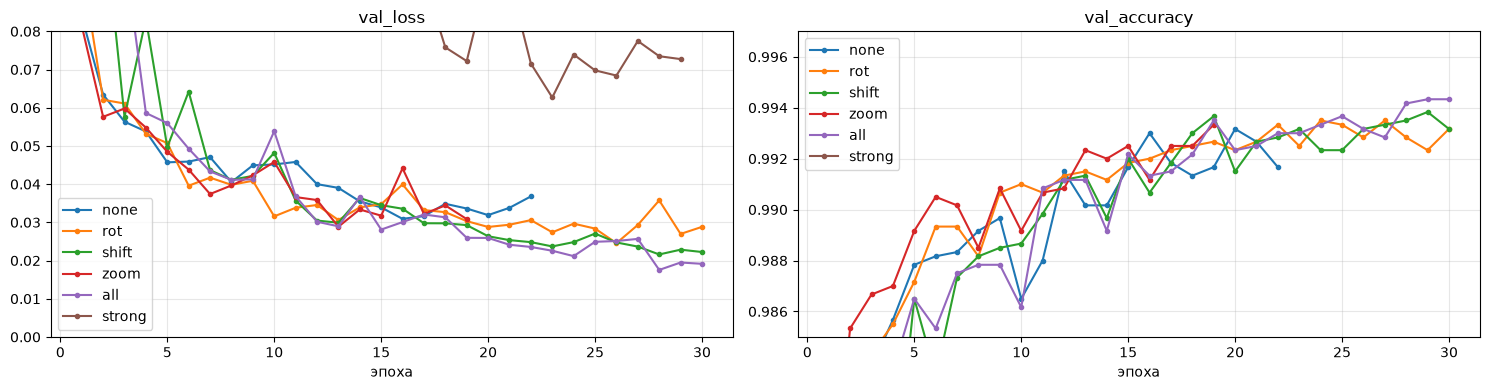

In [44]:
aug_models, aug_rows, aug_hists = {}, [], {}
for p in AUG_PRESETS:
    cfg = {**BASE, "aug": p, "max_epochs": FINAL_EPOCHS, "patience": FINAL_PATIENCE, "reduce_lr": True}
    m, h, r, _ = train_torch(cfg, p, group="aug")
    aug_models[p], aug_hists[p] = m, h
    aug_rows.append(r)
    print(f"{p:7s} | val_acc {r['val_acc']:.4f} | val_loss {r['val_loss']:.4f} | train_acc {r['train_acc']:.4f} | "
          f"лучшая эпоха {r['best_epoch']:2d}/{r['epochs']:2d} | {r['s_per_epoch']:.2f} с/эп | всего {r['time_s']:.0f} с")
aug_df = pd.DataFrame(aug_rows)
display(aug_df[["variant", "val_acc", "val_loss", "train_acc", "gap", "best_epoch", "epochs", "s_per_epoch", "time_s"]].round(4))

fig, ax = plt.subplots(1, 2, figsize=(15, 4))
for p, h in aug_hists.items():
    ep = np.arange(1, len(h["val_loss"]) + 1)
    ax[0].plot(ep, h["val_loss"], marker=".", label=p); ax[1].plot(ep, h["val_accuracy"], marker=".", label=p)
ax[0].set_title("val_loss"); ax[0].set_ylim(0, 0.08); ax[1].set_title("val_accuracy"); ax[1].set_ylim(0.985, 0.997)
for a in ax:
    a.legend(); a.grid(alpha=.3); a.set_xlabel("эпоха")
plt.tight_layout(); plt.show()

Валидационные цифры отцентрованы так же, как обучающие, поэтому дополнительно проверяю устойчивость:
та же валидация, но повёрнутая, сдвинутая или масштабированная.

In [45]:
@torch.no_grad()
def perturb(X: torch.Tensor, angle: float = 0.0, shift_px: float = 0.0, scale: float = 1.0) -> torch.Tensor:
    """Одно и то же аффинное преобразование для всех картинок (для проверки устойчивости)."""
    a = math.radians(angle)
    t = shift_px / 14.0                                   # 14 px = 1 в координатах affine_grid
    theta = torch.tensor([[math.cos(a) / scale, -math.sin(a) / scale, -t],
                          [math.sin(a) / scale,  math.cos(a) / scale, -t]], device=X.device).expand(len(X), 2, 3)
    grid = F.affine_grid(theta, list(X.shape), align_corners=False)
    return F.grid_sample(X - BG, grid, align_corners=False) + BG


TESTS = {"исходная": {}, "поворот 15°": dict(angle=15), "поворот -15°": dict(angle=-15),
         "сдвиг 3 px": dict(shift_px=3), "сдвиг 5 px": dict(shift_px=5), "уменьшение 0.8": dict(scale=0.8),
         "увеличение 1.2": dict(scale=1.2)}
robust = pd.DataFrame({p: {t: evaluate_torch(m, perturb(Xt_val, **kw), yt_val)[1] for t, kw in TESTS.items()}
                       for p, m in aug_models.items()})
display(robust.style.format("{:.4f}").background_gradient(axis=1, cmap="RdYlGn"))

,none,rot,shift,zoom,all,strong
исходная,0.9930,0.9928,0.9935,0.9923,0.9942,0.9815
поворот 15°,0.9808,0.9878,0.9852,0.9803,0.9875,0.9808
поворот -15°,0.9730,0.9870,0.9803,0.9763,0.9880,0.9825
сдвиг 3 px,0.6038,0.7055,0.9860,0.7015,0.9875,0.9805
сдвиг 5 px,0.1127,0.1477,0.8252,0.1485,0.8733,0.9775
уменьшение 0.8,0.9878,0.9900,0.9908,0.9885,0.9917,0.9810
увеличение 1.2,0.9882,0.9910,0.9927,0.9885,0.9927,0.9790


На обычной валидации лучший пресет `all` (0,9942), без аугментации 0,9930, `strong` хуже всех (0,9815).
Эпоха с аугментацией 1,23-1,25 с против 0,99 с.

Разница видна в таблице устойчивости: при сдвиге на 3 px модель без аугментации даёт 0,6038, с `shift` 0,9860, с `all` 0,9875.
`strong` держит даже сдвиг на 5 px (0,9775). Дальше использую `all`.

### 3.2 Итоговые и компактные модели с аугментацией

Обучаю итоговые и компактные модели из раздела 2 ещё раз с пресетом `all`.

Keras final + aug: test accuracy = 0.9945 (ошибок: 55 из 10000)


Keras compact + aug: test accuracy = 0.9959 (ошибок: 41 из 10000)


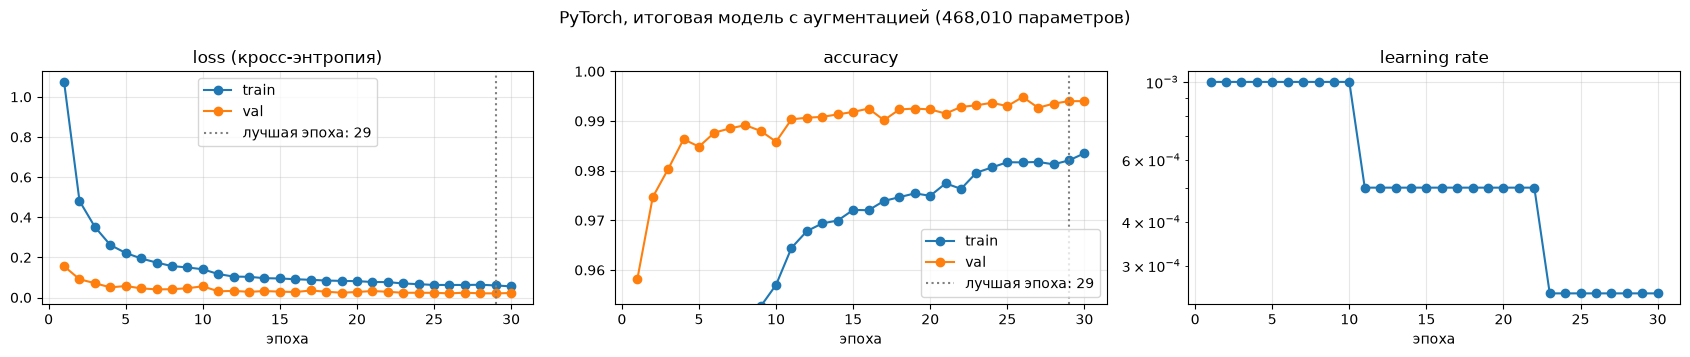

PyTorch final + aug: test accuracy = 0.9955 (ошибок: 45 из 10000)
              precision    recall  f1-score   support

           0     0.9959    0.9990    0.9975       980
           1     0.9947    0.9956    0.9952      1135
           2     0.9932    0.9981    0.9957      1032
           3     0.9941    0.9960    0.9951      1010
           4     0.9970    0.9990    0.9980       982
           5     0.9966    0.9922    0.9944       892
           6     0.9989    0.9916    0.9953       958
           7     0.9903    0.9971    0.9937      1028
           8     0.9969    0.9938    0.9954       974
           9     0.9980    0.9921    0.9950      1009

    accuracy                         0.9955     10000
   macro avg     0.9956    0.9954    0.9955     10000
weighted avg     0.9955    0.9955    0.9955     10000



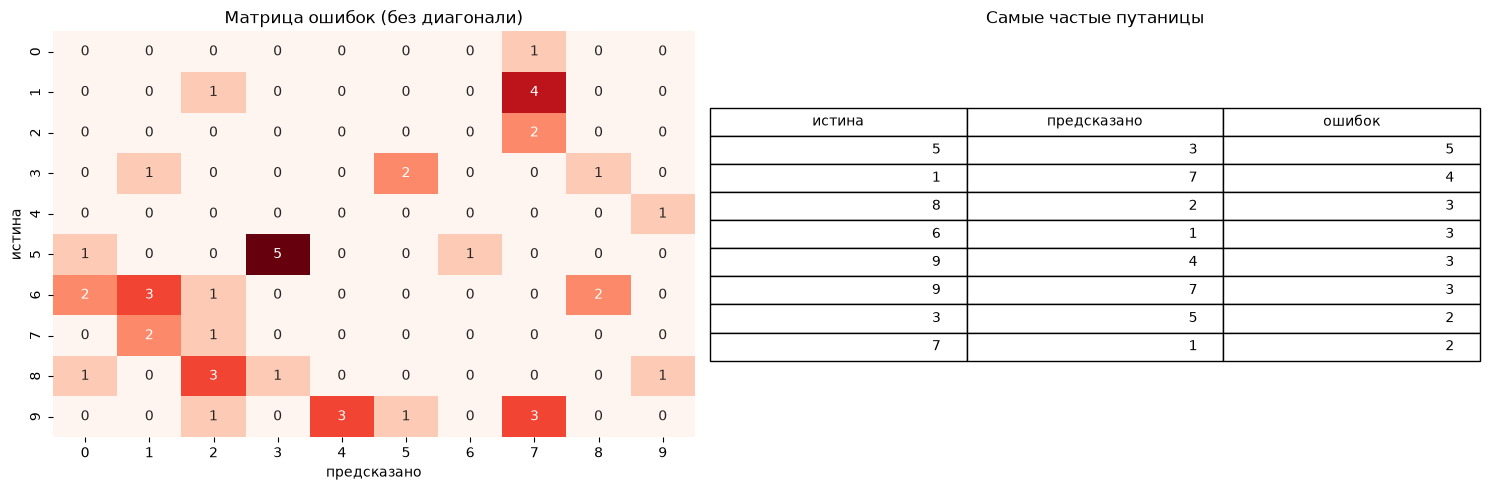

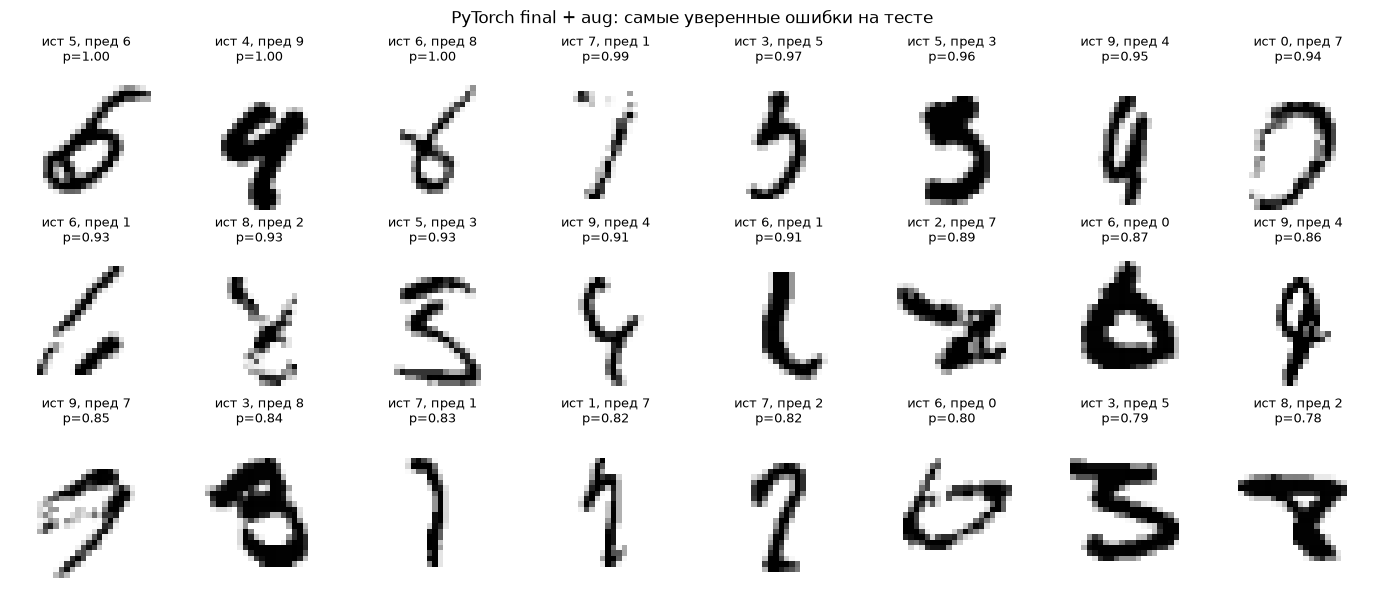

PyTorch compact + aug: test accuracy = 0.9970 (ошибок: 30 из 10000)


In [46]:
final_aug_cfg_k = {**final_cfg_k, "aug": "all"}
final_aug_cfg_t = {**final_cfg_t, "aug": "all"}
compact_aug_cfg_k = {**compact_cfg_k, "aug": "all"}
compact_aug_cfg_t = {**compact_cfg_t, "aug": "all"}

final_aug_k, hist_fak, row_fak, tr = train_keras(final_aug_cfg_k, "final+aug", group="final_aug", keep_open=True)
row_fak["test_acc"] = test_report(yk_test, keras_logits(final_aug_k), "Keras final + aug", plots=False)
close_run(tr, row_fak, test_acc=row_fak["test_acc"])
path_fak = ART_DIR / "keras_final_aug.keras"; final_aug_k.save(str(path_fak))

compact_aug_k, hist_cak, row_cak, tr = train_keras(compact_aug_cfg_k, "compact+aug", group="final_aug", keep_open=True)
row_cak["test_acc"] = test_report(yk_test, keras_logits(compact_aug_k), "Keras compact + aug", plots=False)
close_run(tr, row_cak, test_acc=row_cak["test_acc"])
path_cak = ART_DIR / "keras_compact_aug.keras"; compact_aug_k.save(str(path_cak))

final_aug_t, hist_fat, row_fat, tr = train_torch(final_aug_cfg_t, "final+aug", group="final_aug", keep_open=True)
plot_history(hist_fat, f"PyTorch, итоговая модель с аугментацией ({count_torch(final_aug_t):,} параметров)")
row_fat["test_acc"] = test_report(y_test, predict_torch(final_aug_t, Xt_test), "PyTorch final + aug")
close_run(tr, row_fat, test_acc=row_fat["test_acc"])
path_fat = ART_DIR / "torch_final_aug.pt"; save_torch(final_aug_t, final_aug_cfg_t, path_fat)

compact_aug_t, hist_cat, row_cat, tr = train_torch(compact_aug_cfg_t, "compact+aug", group="final_aug", keep_open=True)
row_cat["test_acc"] = test_report(y_test, predict_torch(compact_aug_t, Xt_test), "PyTorch compact + aug", plots=False)
close_run(tr, row_cat, test_acc=row_cat["test_acc"])
path_cat = ART_DIR / "torch_compact_aug.pt"; save_torch(compact_aug_t, compact_aug_cfg_t, path_cat)

In [47]:
# устойчивость итоговых моделей PyTorch к сдвигам и поворотам: без аугментации и с ней
robust_final = pd.DataFrame({
    name: {t: evaluate_torch(m, perturb(Xt_val, **kw), yt_val)[1] for t, kw in TESTS.items()}
    for name, m in (("final", final_t), ("final+aug", final_aug_t), ("compact", compact_t), ("compact+aug", compact_aug_t))})
display(robust_final.style.format("{:.4f}").background_gradient(axis=1, cmap="RdYlGn"))

,final,final+aug,compact,compact+aug
исходная,0.9928,0.9940,0.9927,0.9943
поворот 15°,0.9797,0.9853,0.9843,0.9897
поворот -15°,0.9712,0.9878,0.9832,0.9892
сдвиг 3 px,0.5833,0.9852,0.9837,0.9937
сдвиг 5 px,0.1003,0.8562,0.9060,0.9898
уменьшение 0.8,0.9878,0.9912,0.9922,0.9927
увеличение 1.2,0.9872,0.9922,0.9867,0.9928


| Модель | без аугментации | с аугментацией |
|---|---|---|
| Keras final (32 906 параметров) | 0,9929 | 0,9945 |
| Keras compact (72 666) | 0,9959 | 0,9959 |
| PyTorch final (468 010) | 0,9944 | 0,9955 |
| PyTorch compact (72 666) | 0,9956 | 0,9970 |

Лучший результат у компактной модели PyTorch с аугментацией (0,9970, 30 ошибок), её беру для приложения.
Итоговая модель PyTorch без аугментации при сдвиге на 3 px даёт 0,5833, с аугментацией 0,9852.
Компактная с аугментацией держит и сдвиг на 5 px (0,9898).

## 4. Готовые модели и transfer learning

Transfer learning: беру сеть, обученную на ImageNet, и заменяю последний слой своим на 10 классов. Варианты:
заморозить основу и учить только голову; дообучить всю сеть с маленьким lr; обучить ту же архитектуру с нуля для сравнения.
Первые слои сети выделяют края и линии, такие признаки годятся и для цифр.

Беру MobileNetV2 (есть в `keras.applications` и `torchvision.models`). Картинку увеличиваю до 64x64 и повторяю канал три раза,
голова: GAP, Dropout 0.2, Dense(10). Сначала 3 эпохи учится только голова (lr 1e-3), потом вся сеть до 8 эпох с lr 1e-4.
Статистики BN основы при дообучении не обновляются: в PyTorch через `frozen_bn`, в Keras слоям BN ставлю `trainable = False`.

In [ ]:
TL_CFG = dict(lr=1e-3, batch_size=128, aug="all", max_epochs=sum(TL_EPOCHS), patience=3,
              early_stopping=True, reduce_lr=False, head_type="gap")
IMNET_MEAN, IMNET_STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)


def build_keras_tl(pretrained: bool = True, aug: str = "all"):
    """MobileNetV2 из keras.applications с новой головой на 10 классов. Возвращает (модель, основа)."""
    base = keras.applications.MobileNetV2(input_shape=(TL_SIZE, TL_SIZE, 3), include_top=False,
                                          weights="imagenet" if pretrained else None, alpha=1.0)
    inp = keras.Input(shape=(28, 28, 1))
    x = inp
    for l in keras_aug_layers(aug):
        x = l(x)
    x = layers.Rescaling(2 * STD, offset=2 * MEAN - 1, name="to_minus1_1")(x)   
    x = layers.Resizing(TL_SIZE, TL_SIZE, interpolation="bilinear", name="resize")(x)
    x = layers.Concatenate(name="gray_to_rgb")([x, x, x])                        
    x = base(x, training=False)                                                  
    x = layers.GlobalAveragePooling2D(name="gap")(x)
    x = layers.Dropout(0.2, name="drop")(x)
    out = layers.Dense(10, dtype="float32", name="logits")(x)
    return keras.Model(inp, out, name="mobilenetv2_keras"), base


class TorchMobileNet(nn.Module):
    """MobileNetV2 из torchvision с новой головой на 10 классов. Вход как у остальных моделей: (N, 1, 28, 28), стандартизованный."""

    def __init__(self, pretrained: bool = True, mean: float = 0.1307, std: float = 0.3081, size: int = TL_SIZE):
        super().__init__()
        weights = torchvision.models.MobileNet_V2_Weights.IMAGENET1K_V1 if pretrained else None
        net = torchvision.models.mobilenet_v2(weights=weights)
        self.features = net.features                       # свёрточная часть, на выходе 1280 каналов
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(0.2), nn.Linear(1280, 10))
        self.size, self.in_mean, self.in_std = size, mean, std
        self.register_buffer("rgb_mean", torch.tensor(IMNET_MEAN).view(1, 3, 1, 1))
        self.register_buffer("rgb_std", torch.tensor(IMNET_STD).view(1, 3, 1, 1))

    def forward(self, x):
        x = x * self.in_std + self.in_mean                                  # обратно в [0, 1]
        x = F.interpolate(x, size=(self.size, self.size), mode="bilinear", align_corners=False)
        x = x.repeat(1, 3, 1, 1)                                            # 1 канал -> 3 канала
        x = (x - self.rgb_mean) / self.rgb_std                              # нормализация, как при обучении на ImageNet
        return self.head(self.features(x))


keras.config.disable_interactive_logging()     # без полосы прогресса при скачивании весов
mk, _ = build_keras_tl(True)
keras.config.enable_interactive_logging()
mt = TorchMobileNet(True, MEAN, STD)
print(f"Keras MobileNetV2: всего параметров {mk.count_params():,}, обучаемых {count_keras(mk):,}")
print(f"PyTorch MobileNetV2: параметров {count_torch(mt):,} (BN-статистики в PyTorch - буферы, в число не входят)")
del mk, mt
keras.backend.clear_session()

Keras MobileNetV2: всего параметров 2,270,794, обучаемых 2,236,682
PyTorch MobileNetV2: параметров 2,236,682 (BN-статистики в PyTorch - буферы, в число не входят)


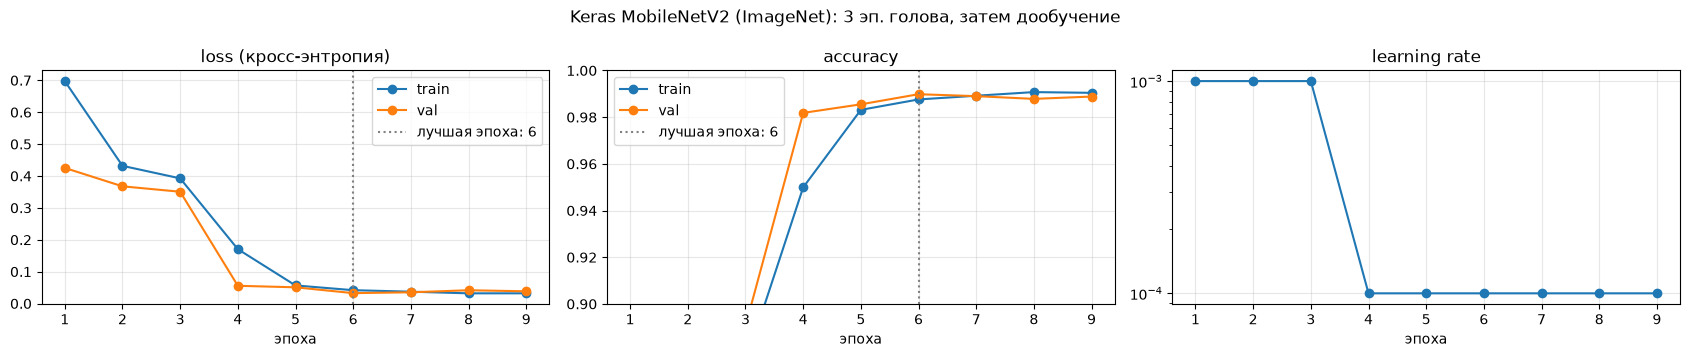

Keras MobileNetV2: test accuracy = 0.9926 (ошибок: 74 из 10000)


In [ ]:
def train_keras_tl(name: str, pretrained: bool = True):
    keras.backend.clear_session(); set_seed(SEED)
    cfg = dict(TL_CFG)
    model, base = build_keras_tl(pretrained, cfg["aug"])
    tracker = Tracker(name, "keras", "transfer", cfg, count_keras(model))
    hist, path = new_hist(), ART_DIR / "keras_tl_best.weights.h5"
    ckpt = keras_ckpt(path)                         # один колбэк на обе фазы, он помнит лучший val_loss
    t0 = time.perf_counter()
    base.trainable = False                          # фаза 1 учится только голова
    fit_keras(model, {**cfg, "early_stopping": False}, 1e-3, TL_EPOCHS[0], hist, tracker, ckpt)
    frozen_acc = max(hist["val_accuracy"])
    base.trainable = True                           # фаза 2 дообучение всей сети с маленьким шагом
    for l in base.layers:                           
        if isinstance(l, layers.BatchNormalization):  
            l.trainable = False
    fit_keras(model, cfg, 1e-4, TL_EPOCHS[1], hist, tracker, ckpt)
    total = time.perf_counter() - t0
    model.load_weights(str(path))
    row = summarize("keras", "transfer", name, cfg, hist, count_keras(model), total)
    row["val_acc_frozen"] = frozen_acc
    RUNS.append(row)
    return model, hist, row, tracker


def train_torch_tl(name: str, pretrained: bool = True):
    set_seed(SEED)
    cfg = dict(TL_CFG)
    model = TorchMobileNet(pretrained, MEAN, STD).to(DEVICE)
    tracker = Tracker(name, "pytorch", "transfer", cfg, count_torch(model))
    hist, best = new_hist(), {"loss": float("inf"), "state": None}
    t0 = time.perf_counter()
    if pretrained:
        for p in model.features.parameters():          # фаза 1 основа заморожена
            p.requires_grad = False
        fit_torch(model, {**cfg, "early_stopping": False}, 1e-3, TL_EPOCHS[0], hist, tracker, best, frozen_bn=model.features)
        frozen_acc = max(hist["val_accuracy"])
        for p in model.features.parameters():          # фаза 2 размораживаю всё
            p.requires_grad = True
        fit_torch(model, cfg, 1e-4, TL_EPOCHS[1], hist, tracker, best, frozen_bn=model.features)
    else:                                              # с нуля всё обучается сразу
        frozen_acc = np.nan
        fit_torch(model, cfg, cfg["lr"], sum(TL_EPOCHS), hist, tracker, best)
    total = time.perf_counter() - t0
    model.load_state_dict(best["state"])
    row = summarize("pytorch", "transfer", name, cfg, hist, count_torch(model), total)
    row["val_acc_frozen"] = frozen_acc
    RUNS.append(row)
    return model, hist, row, tracker


tl_k, hist_tlk, row_tlk, tr = train_keras_tl("mobilenetv2 pretrained")
plot_history(hist_tlk, f"Keras MobileNetV2 (ImageNet): {TL_EPOCHS[0]} эп. голова, затем дообучение")
row_tlk["test_acc"] = test_report(yk_test, keras_logits(tl_k), "Keras MobileNetV2", plots=False)
close_run(tr, row_tlk, test_acc=row_tlk["test_acc"], val_acc_frozen=row_tlk["val_acc_frozen"])
path_tlk = ART_DIR / "keras_mobilenetv2.keras"; tl_k.save(str(path_tlk))

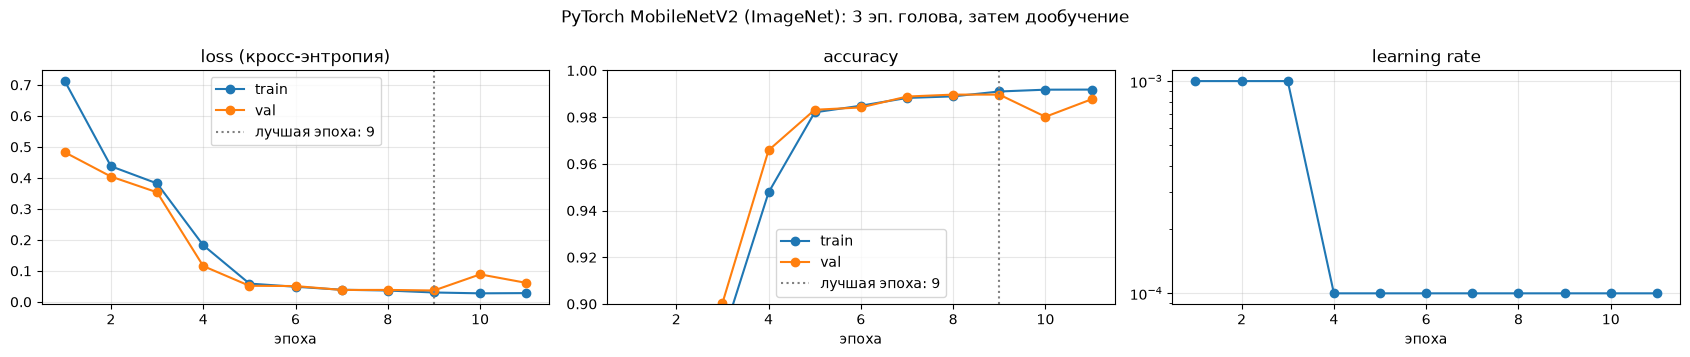

PyTorch MobileNetV2: test accuracy = 0.9923 (ошибок: 77 из 10000)
              precision    recall  f1-score   support

           0     0.9959    1.0000    0.9980       980
           1     0.9904    0.9982    0.9943      1135
           2     0.9903    0.9932    0.9918      1032
           3     0.9834    0.9950    0.9892      1010
           4     0.9939    0.9888    0.9913       982
           5     0.9954    0.9809    0.9881       892
           6     0.9979    0.9896    0.9937       958
           7     0.9884    0.9942    0.9913      1028
           8     0.9959    0.9928    0.9943       974
           9     0.9930    0.9881    0.9906      1009

    accuracy                         0.9923     10000
   macro avg     0.9925    0.9921    0.9923     10000
weighted avg     0.9923    0.9923    0.9923     10000



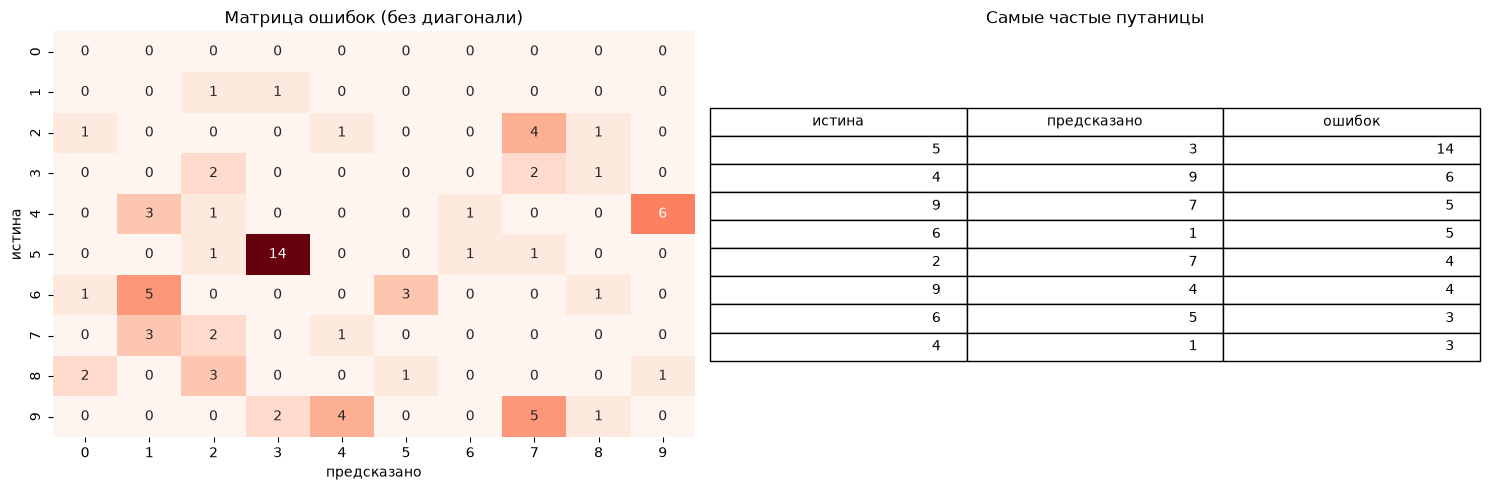

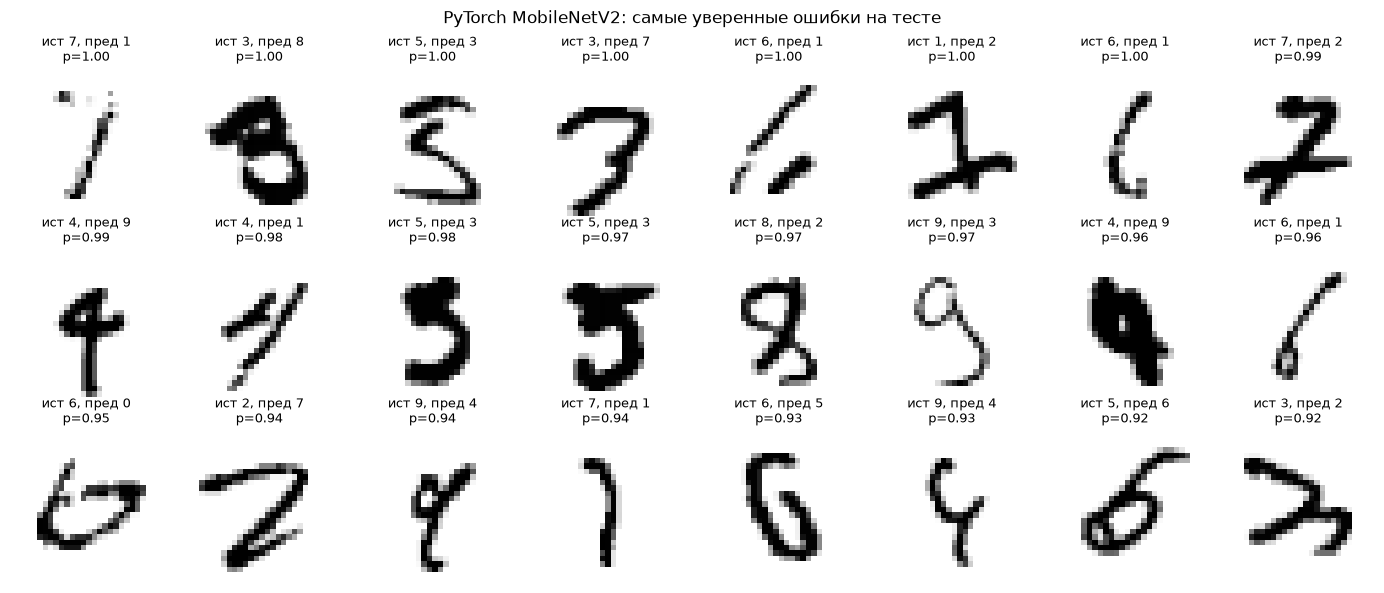

PyTorch MobileNetV2 с нуля: test accuracy = 0.9912 (ошибок: 88 из 10000)


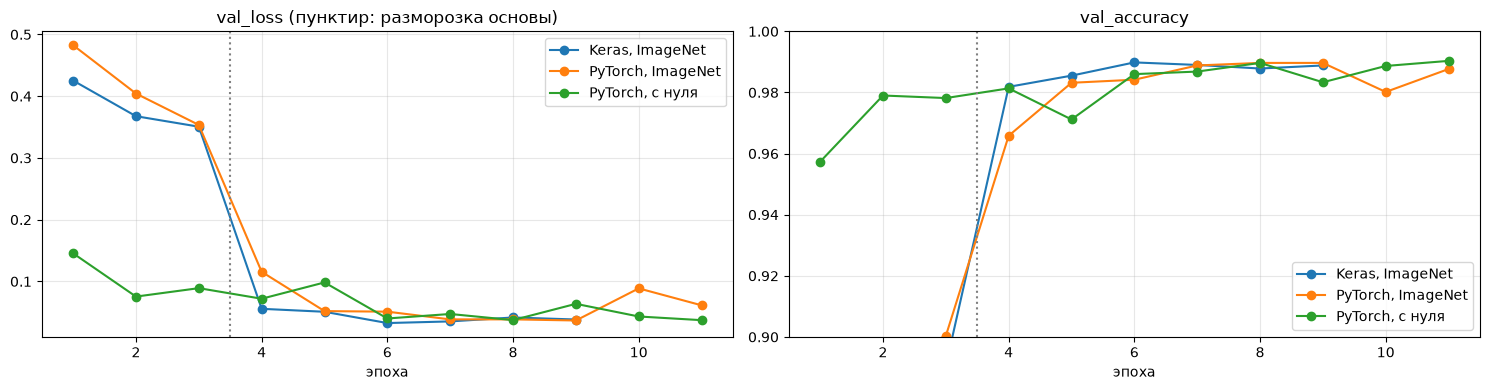

,framework,variant,val_acc_frozen,val_acc,test_acc,best_epoch,epochs,params,s_per_epoch,time_s
0,keras,mobilenetv2 pretrained,0.8905,0.9898,0.9926,6,9,2202570,22.9055,226.7830
1,pytorch,mobilenetv2 pretrained,0.9003,0.9897,0.9923,9,11,2236682,5.5177,86.7494
2,pytorch,mobilenetv2 from scratch,NaN,0.9903,0.9912,11,11,2236682,6.5580,72.7100


In [50]:
tl_t, hist_tlt, row_tlt, tr = train_torch_tl("mobilenetv2 pretrained", pretrained=True)
plot_history(hist_tlt, f"PyTorch MobileNetV2 (ImageNet): {TL_EPOCHS[0]} эп. голова, затем дообучение")
row_tlt["test_acc"] = test_report(y_test, predict_torch(tl_t, Xt_test), "PyTorch MobileNetV2")
close_run(tr, row_tlt, test_acc=row_tlt["test_acc"], val_acc_frozen=row_tlt["val_acc_frozen"])
path_tlt = ART_DIR / "torch_mobilenetv2.pt"
torch.save({"state_dict": tl_t.state_dict(), "mean": MEAN, "std": STD, "size": TL_SIZE}, path_tlt)

tl0_t, hist_tl0, row_tl0, tr = train_torch_tl("mobilenetv2 from scratch", pretrained=False)
row_tl0["test_acc"] = test_report(y_test, predict_torch(tl0_t, Xt_test), "PyTorch MobileNetV2 с нуля", plots=False)
close_run(tr, row_tl0, test_acc=row_tl0["test_acc"])

fig, ax = plt.subplots(1, 2, figsize=(15, 4))
for h, lab in ((hist_tlk, "Keras, ImageNet"), (hist_tlt, "PyTorch, ImageNet"), (hist_tl0, "PyTorch, с нуля")):
    ep = np.arange(1, len(h["val_loss"]) + 1)
    ax[0].plot(ep, h["val_loss"], "o-", label=lab); ax[1].plot(ep, h["val_accuracy"], "o-", label=lab)
for a in ax:
    a.axvline(TL_EPOCHS[0] + 0.5, color="gray", ls=":"); a.grid(alpha=.3); a.legend(); a.set_xlabel("эпоха")
ax[0].set_title("val_loss (пунктир: разморозка основы)"); ax[1].set_title("val_accuracy"); ax[1].set_ylim(0.9, 1.0)
plt.tight_layout(); plt.show()

tl_tab = pd.DataFrame([row_tlk, row_tlt, row_tl0])[["framework", "variant", "val_acc_frozen", "val_acc", "test_acc",
                                                     "best_epoch", "epochs", "params", "s_per_epoch", "time_s"]]
display(tl_tab.round(4))

| Вариант | val, только голова | val после дообучения | test |
|---|---|---|---|
| Keras, ImageNet | 0,8905 | 0,9898 | 0,9926 |
| PyTorch, ImageNet | 0,9003 | 0,9897 | 0,9923 |
| PyTorch, с нуля | | 0,9903 | 0,9912 |

С замороженной основой точность около 0,89-0,90, после дообучения обе сети дошли до 0,99. MobileNetV2 с нуля дала 0,9912,
почти столько же, сколько предобученная: на MNIST хватает своих данных. Моя компактная CNN (72 666 параметров, 0,9970)
точнее MobileNetV2 (2 236 682 параметра).

## 5. Журнал экспериментов и итоговая таблица

Все обучения тетрадки (серии, второй этап, аугментация, готовые модели, демо переобучения и замер скорости) лежат в `RUNS`.
Сохраняю их в `artifacts/runs_log.csv`. Точность на тесте есть только у моделей, которые на нём проверялись.

In [51]:
runs = pd.DataFrame(RUNS)
runs.to_csv(ART_DIR / "runs_log.csv", index=False)
print(f"всего обучений: {len(runs)}")
display(runs.groupby(["group", "framework"]).size().unstack(fill_value=0))

parallel_plot(runs[runs["group"] != "transfer"].reset_index(drop=True),
              f"Все обучения собственной CNN ({(runs['group'] != 'transfer').sum()} шт.): гиперпараметры и val accuracy")

всего обучений: 65


framework,keras,pytorch
group,,
aug,0,6
base,1,1
base_filters,2,2
batch_norm,1,1
batch_size,2,2
compact,1,1
convs_per_block,1,1
dropout,3,3
final_aug,2,2


In [52]:
def file_mb(p: Path) -> float:
    return p.stat().st_size / 2**20


final_rows = [
    ("base (серия)", res_k.iloc[0], None), ("final", row_fk, path_fk), ("final+aug", row_fak, path_fak),
    ("compact", row_ck, path_ck), ("compact+aug", row_cak, path_cak), ("MobileNetV2 ImageNet", row_tlk, path_tlk),
    ("base (серия)", res_t.iloc[0], None), ("final", row_ft, path_ft), ("final+aug", row_fat, path_fat),
    ("compact", row_ct, path_ct), ("compact+aug", row_cat, path_cat), ("MobileNetV2 ImageNet", row_tlt, path_tlt),
    ("MobileNetV2 с нуля", row_tl0, None),
]
summary = pd.DataFrame([dict(модель=n, фреймворк=r["framework"], параметры=int(r["params"]), val_acc=r["val_acc"],
                             test_acc=r["test_acc"], эпох=int(r["epochs"]), лучшая_эпоха=int(r["best_epoch"]),
                             с_на_эпоху=r["s_per_epoch"], время_с=r["time_s"],
                             файл_МБ=file_mb(p) if p is not None else np.nan) for n, r, p in final_rows])
summary.to_csv(ART_DIR / "summary_final.csv", index=False)
display(summary.round(4))

# итоговая таблица с точностью на тесте - отдельным прогоном в WandB
if WANDB_MODE != "disabled":
    run = wandb.init(project=WANDB_PROJECT, name="summary", job_type="summary", mode=WANDB_MODE, dir=str(ART_DIR))
    run.log({"итоговые модели": wandb.Table(dataframe=summary.round(5)),
             "все обучения": wandb.Table(dataframe=runs.drop(columns=["val_acc_frozen"], errors="ignore").astype(str))})
    run.finish()

for fw in ("keras", "pytorch"):
    s = summary[(summary["фреймворк"] == fw) & summary["test_acc"].notna()]
    b = s.loc[s["val_acc"].idxmax()]
    print(f"{fw}: лучшая по валидации - {b['модель']} (val {b['val_acc']:.4f}, test {b['test_acc']:.4f}, {b['параметры']:,} парам.)")

,модель,фреймворк,параметры,val_acc,test_acc,эпох,лучшая_эпоха,с_на_эпоху,время_с,файл_МБ
0,base (серия),keras,468010,0.9895,NaN,9,6,4.6051,45.0290,NaN
1,final,keras,32906,0.9927,0.9929,21,15,5.8666,125.5682,0.4368
2,final+aug,keras,32906,0.9927,0.9945,30,25,7.2306,219.1426,0.4394
3,compact,keras,72666,0.9957,0.9959,21,15,11.7859,249.8183,0.9370
4,compact+aug,keras,72666,0.9942,0.9959,19,13,12.5838,240.8577,0.9388
5,MobileNetV2 ImageNet,keras,2202570,0.9898,0.9926,9,6,22.9055,226.7830,26.0788
6,base (серия),pytorch,468010,0.9925,NaN,15,14,0.9401,21.1611,NaN
7,final,pytorch,468010,0.9928,0.9944,22,16,0.9459,20.8954,1.7968
8,final+aug,pytorch,468010,0.9940,0.9955,30,29,1.2026,36.2677,1.7969
9,compact,pytorch,72666,0.9927,0.9956,28,22,1.1730,35.8547,0.2922


keras: лучшая по валидации - compact (val 0.9957, test 0.9959, 72,666 парам.)
pytorch: лучшая по валидации - compact+aug (val 0.9943, test 0.9970, 72,666 парам.)


In [53]:
# модель для веб-интерфейса и Docker: лучшая по валидации собственная CNN на PyTorch (на CPU она работает быстро)
torch_candidates = {"final": (row_ft, path_ft), "final+aug": (row_fat, path_fat),
                    "compact": (row_ct, path_ct), "compact+aug": (row_cat, path_cat)}
app_name = max(torch_candidates, key=lambda k: torch_candidates[k][0]["val_acc"])
import shutil
shutil.copy(torch_candidates[app_name][1], ART_DIR / "torch_best.pt")
print("для приложения взята модель:", app_name, "->", ART_DIR / "torch_best.pt")

if WANDB_MODE == "online":
    try:
        print("проект в WandB:", f"https://wandb.ai/{wandb.Api().default_entity}/{WANDB_PROJECT}")
    except Exception as e:
        print("не удалось получить ссылку на проект:", e)
elif WANDB_MODE == "offline":
    print("WandB офлайн, прогоны лежат в", ART_DIR / "wandb", "| загрузить: wandb sync", ART_DIR / "wandb" / "offline-run-*")

для приложения взята модель: compact+aug -> artifacts\torch_best.pt
WandB офлайн, прогоны лежат в artifacts\wandb | загрузить: wandb sync artifacts\wandb\offline-run-*


Всего 65 обучений, каждое записано в `runs_log.csv` и в WandB (класс `Tracker`): гиперпараметры и число параметров
в config, loss, accuracy, lr и время по эпохам, в summary лучшие метрики и точность на тесте. Прогоны лежат офлайн
в `artifacts/wandb/`, загрузить их: `wandb login`, затем `wandb sync artifacts/wandb/offline-run-*`.
График в параллельных координатах есть в разделе 2.3.

## 6. Схемы сетей

Прямоугольник это тензор после группы слоёв: высота показывает размер карты, ширина число каналов.
Схема строится по тому же `cfg`, что и модель. Ниже схема `keras.utils.plot_model`, если установлен graphviz.

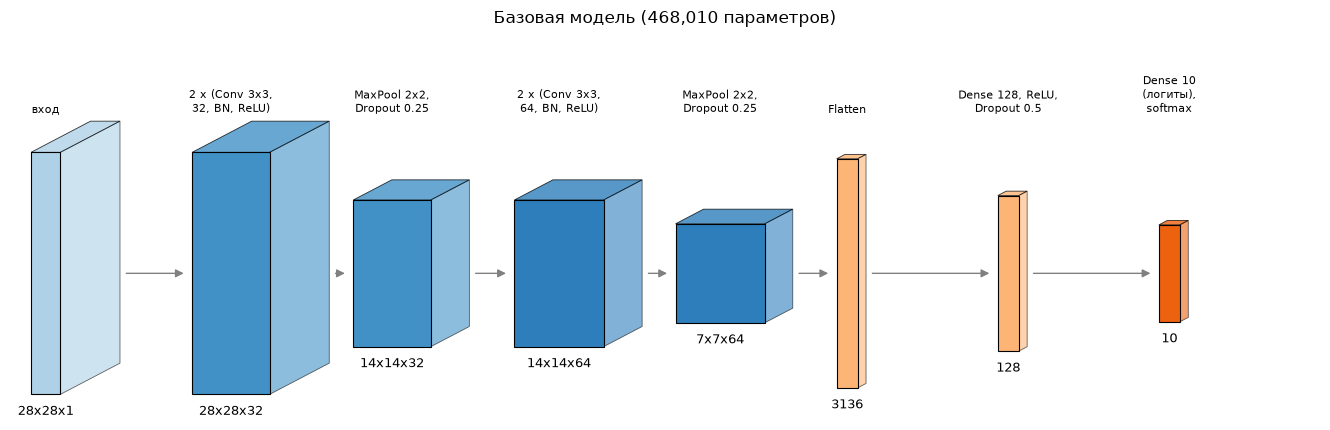

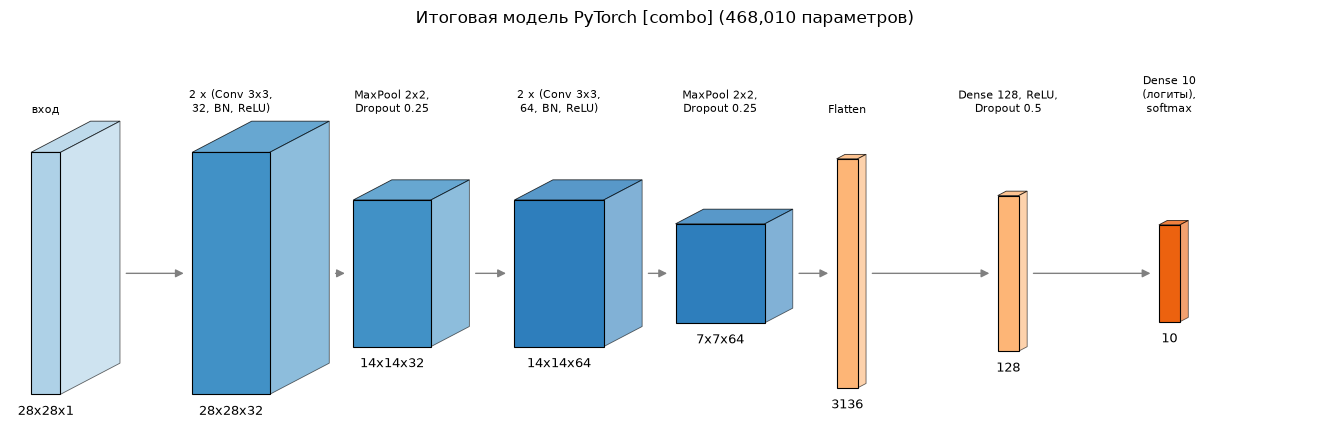

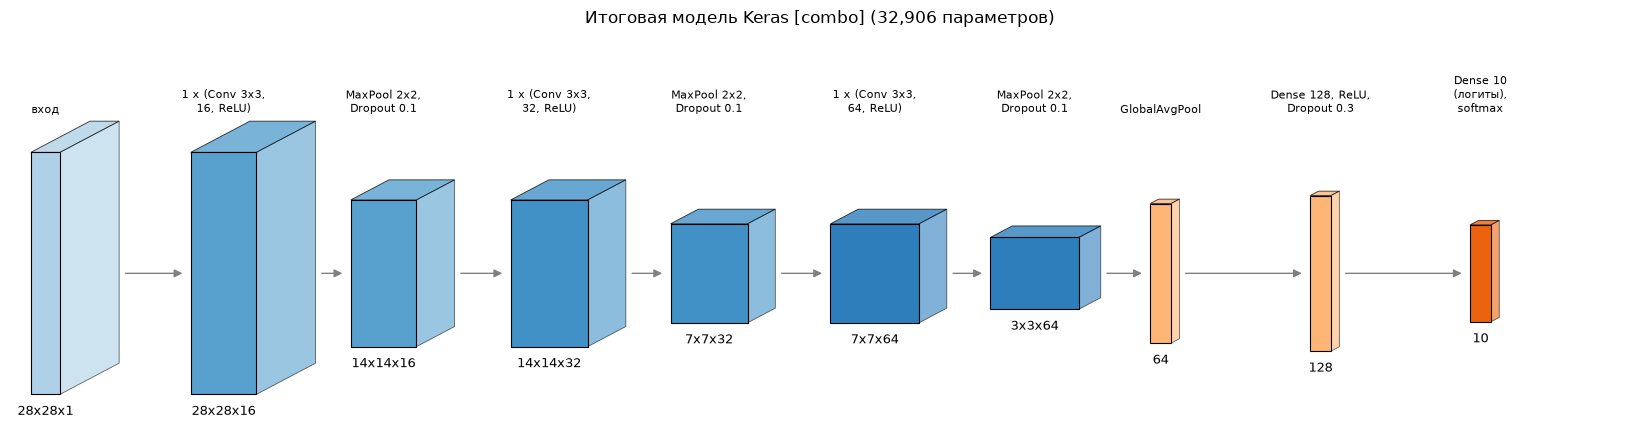

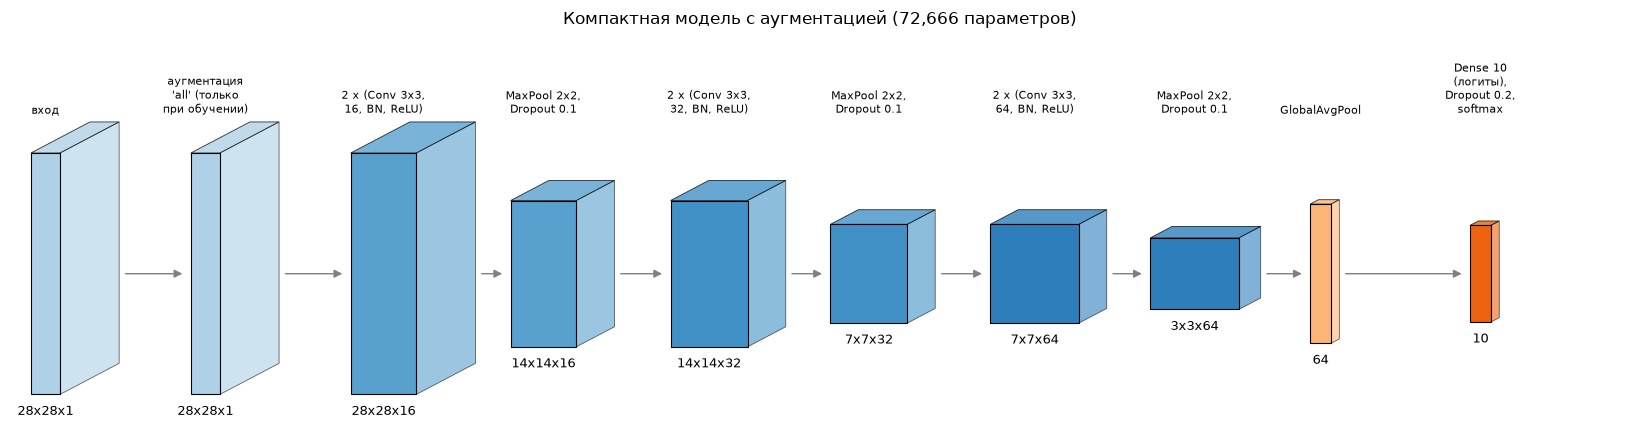

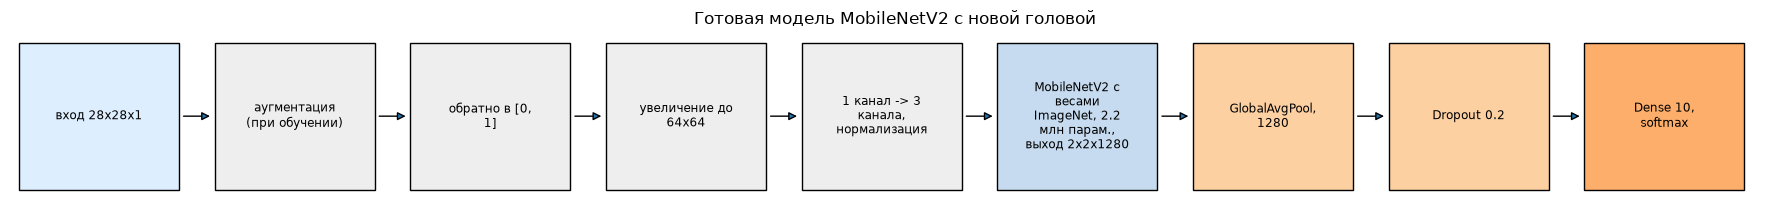

In [54]:
from matplotlib.patches import Rectangle, Polygon, FancyArrowPatch
from textwrap import fill as wrap


def cnn_stages(cfg: dict) -> list:
    """Тензоры по ходу сети: (какие слои, форма выхода)."""
    out, h, k = [("вход", (28, 28, 1))], 28, cfg["kernel_size"]
    if cfg.get("aug", "none") != "none":
        out.append((f"аугментация '{cfg['aug']}' (только при обучении)", (28, 28, 1)))
    for b in range(cfg["n_blocks"]):
        c = cfg["base_filters"] * 2 ** b
        conv = f"{cfg['convs_per_block']} x (Conv {k}x{k}, {c}" + (", BN" if cfg["batch_norm"] else "") + ", ReLU)"
        out.append((conv, (h, h, c)))
        h //= 2
        out.append(("MaxPool 2x2" + (f", Dropout {cfg['conv_dropout']}" if cfg["conv_dropout"] else ""), (h, h, c)))
    out.append(("Flatten", (h * h * c,)) if cfg["head_type"] == "flatten" else ("GlobalAvgPool", (c,)))
    drop = f", Dropout {cfg['dense_dropout']}" if cfg["dense_dropout"] else ""
    if cfg["dense_units"]:
        out.append((f"Dense {cfg['dense_units']}, ReLU{drop}", (cfg["dense_units"],)))
        drop = ""
    out.append((f"Dense 10 (логиты){drop}, softmax", (10,)))
    return out


def draw_cnn(cfg: dict, title: str) -> None:
    st = cnn_stages(cfg)
    step = 2.3
    fig, ax = plt.subplots(figsize=(1.55 * len(st) + 1, 4.4))
    for i, (op, shape) in enumerate(st):
        x0 = i * step
        if len(shape) == 3:
            H, _, C = shape
            h, w, d = 0.7 + 2.6 * H / 28, 0.25 + 0.17 * np.log2(C + 1), 0.25 + 0.6 * H / 28
            color, label = plt.cm.Blues(0.25 + 0.6 * np.log2(C + 1) / 8), f"{H}x{H}x{C}"
        else:
            n = shape[0]
            h, w, d = 0.6 + 2.6 * np.log10(n) / np.log10(4000), 0.3, 0.12
            color, label = plt.cm.Oranges(0.35 + 0.3 * (n == 10)), f"{n}"
        y0 = -h / 2
        ax.add_patch(Polygon([(x0, y0 + h), (x0 + d, y0 + h + d * 0.5), (x0 + w + d, y0 + h + d * 0.5), (x0 + w, y0 + h)],
                             fc=color, ec="k", lw=0.6, alpha=0.8))                  # верхняя грань
        ax.add_patch(Polygon([(x0 + w, y0), (x0 + w + d, y0 + d * 0.5), (x0 + w + d, y0 + h + d * 0.5), (x0 + w, y0 + h)],
                             fc=color, ec="k", lw=0.6, alpha=0.6))                  # боковая грань
        ax.add_patch(Rectangle((x0, y0), w, h, fc=color, ec="k", lw=0.8))         # передняя грань
        ax.text(x0 + w / 2, y0 - 0.15, label, ha="center", va="top", fontsize=9)
        ax.text(x0 + w / 2, 2.15, wrap(op, 16), ha="center", va="bottom", fontsize=8)
        if i < len(st) - 1:
            ax.add_patch(FancyArrowPatch((x0 + w + d + 0.05, 0), ((i + 1) * step - 0.08, 0),
                                         arrowstyle="-|>", mutation_scale=12, color="gray"))
    ax.set_xlim(-0.3, len(st) * step); ax.set_ylim(-2.0, 3.3); ax.axis("off")
    ax.set_title(title); plt.tight_layout(); plt.show()


def draw_flow(boxes: list, title: str) -> None:
    """Простая схема-цепочка из подписанных блоков."""
    fig, ax = plt.subplots(figsize=(2.0 * len(boxes), 2.2))
    for i, (text, color) in enumerate(boxes):
        ax.add_patch(Rectangle((i * 2.2, 0), 1.8, 1.4, fc=color, ec="k"))
        ax.text(i * 2.2 + 0.9, 0.7, wrap(text, 15), ha="center", va="center", fontsize=8.5)
        if i < len(boxes) - 1:
            ax.add_patch(FancyArrowPatch((i * 2.2 + 1.82, 0.7), (i * 2.2 + 2.18, 0.7), arrowstyle="-|>", mutation_scale=12))
    ax.set_xlim(-0.1, len(boxes) * 2.2); ax.set_ylim(-0.1, 1.5); ax.axis("off"); ax.set_title(title)
    plt.tight_layout(); plt.show()


draw_cnn(BASE, f"Базовая модель ({count_torch(TorchCNN(BASE)):,} параметров)")
draw_cnn(final_cfg_t, f"Итоговая модель PyTorch [{final_name_t}] ({count_torch(final_t):,} параметров)")
if final_cfg_k != final_cfg_t:
    draw_cnn(final_cfg_k, f"Итоговая модель Keras [{final_name_k}] ({count_keras(final_k):,} параметров)")
draw_cnn(compact_aug_cfg_t, f"Компактная модель с аугментацией ({count_torch(compact_aug_t):,} параметров)")
draw_flow([("вход 28x28x1", "#ddeeff"), ("аугментация (при обучении)", "#eeeeee"), ("обратно в [0, 1]", "#eeeeee"),
           (f"увеличение до {TL_SIZE}x{TL_SIZE}", "#eeeeee"), ("1 канал -> 3 канала, нормализация", "#eeeeee"),
           ("MobileNetV2 с весами ImageNet, 2.2 млн парам., выход 2x2x1280", "#c6dbef"),
           ("GlobalAvgPool, 1280", "#fdd0a2"), ("Dropout 0.2", "#fdd0a2"), ("Dense 10, softmax", "#fdae6b")],
          "Готовая модель MobileNetV2 с новой головой")

In [ ]:
# схема от самого Keras 
try:
    keras.utils.plot_model(final_k, to_file=str(ART_DIR / "keras_final_plot.png"), show_shapes=True,
                           show_layer_names=True, dpi=60)
    display(IPImage(filename=str(ART_DIR / "keras_final_plot.png")))
except Exception as e:
    print("keras.utils.plot_model пропущен: в системе нет программы graphviz (в Colab она есть). Схемы выше от неё не зависят.")

keras.utils.plot_model пропущен: в системе нет программы graphviz (в Colab она есть). Схемы выше от неё не зависят.


## 7. Классификация сохранённой моделью

Загружаю модели из файлов: `keras.models.load_model` для Keras, для PyTorch собираю `TorchCNN` по `cfg` из файла
и загружаю `state_dict`.

файл PyTorch содержит: ['state_dict', 'cfg', 'mean', 'std'] | cfg: {'lr': 0.001, 'batch_size': 128, 'n_blocks': 3, 'base_filters': 16, 'convs_per_block': 2, 'kernel_size': 3, 'batch_norm': True, 'conv_dropout': 0.1, 'head_type': 'gap', 'dense_units': 0, 'dense_dropout': 0.2, 'init': 'he_uniform', 'aug': 'all'}
точность загруженной модели Keras: 0.9929
точность загруженной модели PyTorch (compact+aug): 0.9970
ответы Keras и PyTorch совпадают на 99.34% тестовых картинок


время на одну картинку: Keras 3.11 мс, PyTorch 0.74 мс (cuda)


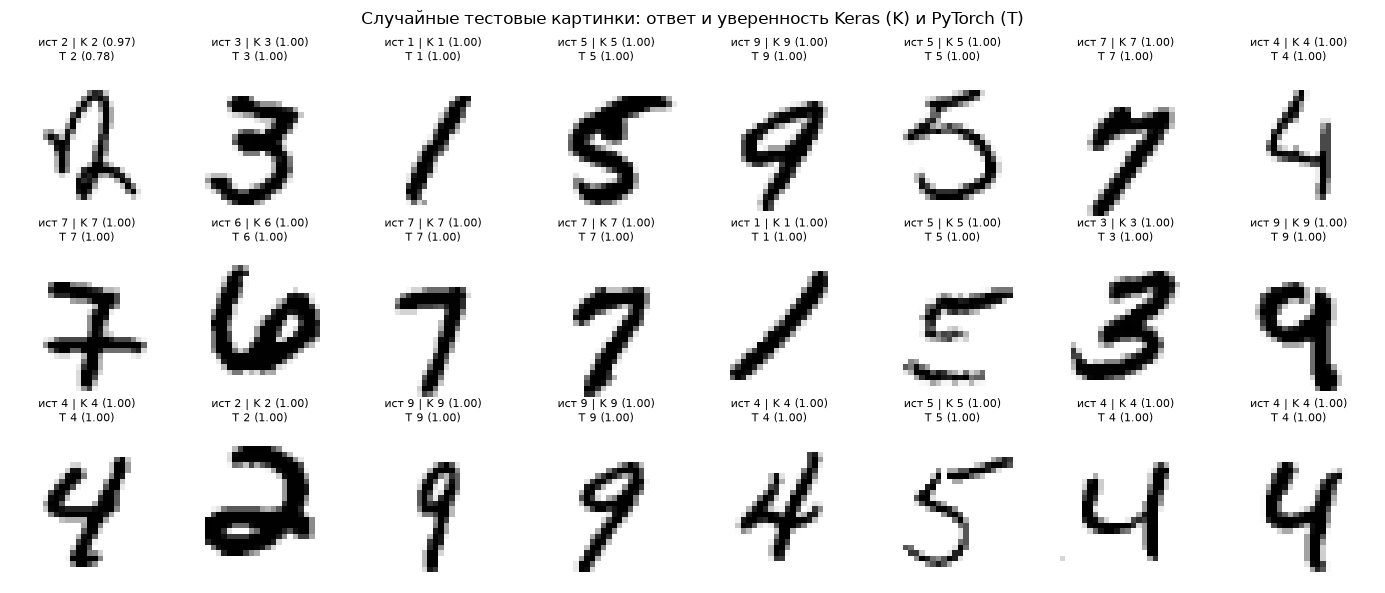

In [ ]:
k_model = keras.models.load_model(str(path_fk))
ckpt = torch.load(ART_DIR / "torch_best.pt", map_location=DEVICE, weights_only=True)
t_model = TorchCNN(ckpt["cfg"]).to(DEVICE).eval()
t_model.load_state_dict(ckpt["state_dict"])
print("файл PyTorch содержит:", list(ckpt), "| cfg:", ckpt["cfg"])

pk = softmax(keras_logits(k_model))
pt = softmax(predict_torch(t_model, Xt_test))
print(f"точность загруженной модели Keras: {accuracy_score(y_test, pk.argmax(1)):.4f}")
print(f"точность загруженной модели PyTorch ({app_name}): {accuracy_score(y_test, pt.argmax(1)):.4f}")
print(f"ответы Keras и PyTorch совпадают на {(pk.argmax(1) == pt.argmax(1)).mean():.2%} тестовых картинок")

# время на одну картинку (батч из одной картинки)
x1k, x1t = Xk_test[:1], Xt_test[:1]
for _ in range(5):
    k_model(x1k, training=False); t_model(x1t)
t0 = time.perf_counter()
for _ in range(100):
    k_model(x1k, training=False)
tk = (time.perf_counter() - t0) / 100
with torch.no_grad():
    t0 = time.perf_counter()
    for _ in range(100):
        t_model(x1t).argmax(1).item()
    tt = (time.perf_counter() - t0) / 100
print(f"время на одну картинку: Keras {tk * 1000:.2f} мс, PyTorch {tt * 1000:.2f} мс ({DEVICE})")

rng = np.random.default_rng(1)
idx = rng.choice(len(x_test), 24, replace=False)
fig, axes = plt.subplots(3, 8, figsize=(14, 6))
for a, i in zip(axes.flat, idx):
    a.imshow(x_test[i], cmap="gray_r"); a.axis("off")
    ok = pt[i].argmax() == y_test[i]
    a.set_title(f"ист {y_test[i]} | K {pk[i].argmax()} ({pk[i].max():.2f})\nT {pt[i].argmax()} ({pt[i].max():.2f})",
                fontsize=8, color="k" if ok else "red")
fig.suptitle("Случайные тестовые картинки: ответ и уверенность Keras (K) и PyTorch (T)"); plt.tight_layout(); plt.show()

Проверяю модели на печатных цифрах, которых сеть не видела. Картинку готовлю функцией `to_mnist`, той же, что в приложении:
обрезка по краям цифры, уменьшение до 20 px, центрирование по центру масс.

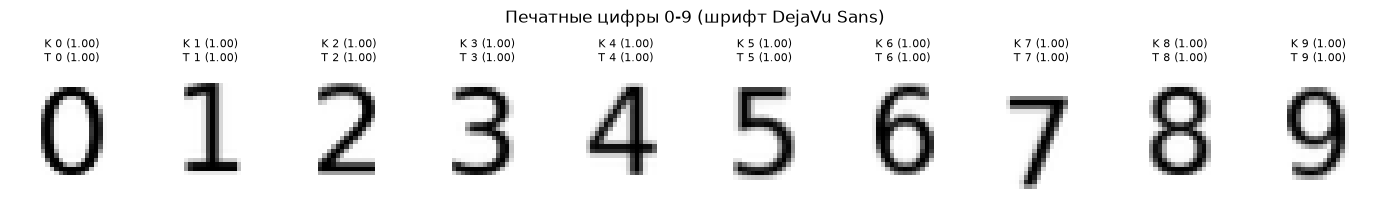

верно: Keras 10 из 10, PyTorch 10 из 10


In [57]:
import matplotlib.font_manager as fm


def to_mnist(img: np.ndarray) -> np.ndarray:
    """Картинка со светлой цифрой на тёмном фоне (uint8, любой размер) -> 28x28 uint8, как в MNIST."""
    ys, xs = np.nonzero(img > 30)
    if len(xs) == 0:
        return np.zeros((28, 28), np.uint8)
    crop = img[ys.min():ys.max() + 1, xs.min():xs.max() + 1]
    h, w = crop.shape
    s = 20 / max(h, w)                                   # большая сторона цифры = 20 px, как у авторов MNIST
    crop = np.asarray(Image.fromarray(crop).resize((max(1, round(w * s)), max(1, round(h * s))), Image.LANCZOS),
                      dtype=np.float32)
    out = np.zeros((28, 28), np.float32)
    h, w = crop.shape
    out[(28 - h) // 2:(28 - h) // 2 + h, (28 - w) // 2:(28 - w) // 2 + w] = crop
    cy, cx = ndimage.center_of_mass(out)                 # центр масс ставлю в центр кадра
    out = ndimage.shift(out, (13.5 - cy, 13.5 - cx), order=1, mode="constant")
    return np.clip(out, 0, 255).astype(np.uint8)


font = ImageFont.truetype(fm.findfont("DejaVu Sans"), 160)
printed = []
for d in range(10):
    im = Image.new("L", (200, 200), 0)
    ImageDraw.Draw(im).text((100, 100), str(d), fill=255, font=font, anchor="mm")
    printed.append(to_mnist(np.array(im)))
printed = np.stack(printed)
pp_k = softmax(keras_logits(k_model, preprocess(printed)[..., None]))
pp_t = softmax(predict_torch(t_model, torch.from_numpy(preprocess(printed)[:, None]).to(DEVICE)))
fig, axes = plt.subplots(1, 10, figsize=(14, 2.2))
for d, a in enumerate(axes):
    a.imshow(printed[d], cmap="gray_r"); a.axis("off")
    a.set_title(f"K {pp_k[d].argmax()} ({pp_k[d].max():.2f})\nT {pp_t[d].argmax()} ({pp_t[d].max():.2f})", fontsize=8,
                color="k" if pp_t[d].argmax() == d else "red")
fig.suptitle("Печатные цифры 0-9 (шрифт DejaVu Sans)"); plt.tight_layout(); plt.show()
print("верно: Keras", (pp_k.argmax(1) == np.arange(10)).sum(), "из 10, PyTorch", (pp_t.argmax(1) == np.arange(10)).sum(), "из 10")

После загрузки из файлов точность та же: Keras 0,9929, PyTorch 0,9970. Ответы двух моделей совпадают на 99,34% тестовых картинок,
одна картинка обрабатывается за 3,11 мс в Keras и 0,74 мс в PyTorch. Печатные цифры обе модели распознали 10 из 10.

## 8. Веб-интерфейс и Docker

Интерфейс на Gradio: рисуешь цифру мышкой, сеть показывает вероятности классов. В Colab он запускается в следующей ячейке.
В папке `app/` то же приложение отдельно: `model.py` (модель и `to_mnist`), `main.py` (сервер FastAPI с `POST /predict`
и интерфейс Gradio на `/`), `Dockerfile`.

```bash
# без Docker, из корня проекта; потом открыть http://127.0.0.1:8000/
python app/main.py
# с Docker
docker build -f app/Dockerfile -t mnist-cnn .
docker run -p 8000:8000 mnist-cnn
```

In [58]:
import gradio as gr


def sketch_to_gray(value) -> np.ndarray:
    """Картинка из gr.Sketchpad (dict с 'composite' или массив) -> светлая цифра на тёмном фоне, uint8."""
    img = value.get("composite") if isinstance(value, dict) else value
    if img is None:
        return np.zeros((28, 28), np.uint8)
    img = np.asarray(img)
    if img.ndim == 3 and img.shape[2] == 4:
        # кладу картинку на белый фон: у холста Gradio вокруг белого листа прозрачная рамка, а штрихи чёрные
        a = img[..., 3:4].astype(np.float32) / 255.0
        gray = (img[..., :3].astype(np.float32) * a + 255.0 * (1 - a)).mean(axis=2)
        if gray.max() - gray.min() < 30 and a.min() < 0.98:   # светлая цифра на прозрачном фоне видна только в альфа-канале
            return img[..., 3].astype(np.uint8)
        img = gray
    elif img.ndim == 3:
        img = img[..., :3].mean(axis=2)
    img = img.astype(np.float32)
    border = np.concatenate([img[0], img[-1], img[:, 0], img[:, -1]])
    if border.mean() > 127:                              # фон светлый (тёмная цифра на белом) -> инвертирую
        img = 255 - img
    return img.astype(np.uint8)


def classify(value):
    x28 = to_mnist(sketch_to_gray(value))
    xt = torch.from_numpy(preprocess(x28[None])[:, None]).to(DEVICE)
    proba = softmax(predict_torch(t_model, xt))[0]
    return {str(d): float(proba[d]) for d in range(10)}, np.kron(x28, np.ones((6, 6), np.uint8))   # картинка 28x28, увеличенная в 6 раз


GR5 = int(gr.__version__.split(".")[0]) >= 5          # в Gradio 4 и 5 немного разные параметры
sketch_kw = dict(label="Нарисуйте цифру", type="numpy", image_mode="RGBA", canvas_size=(280, 280))
if GR5:
    sketch_kw["brush"] = gr.Brush(default_size=18, colors=["#000000"], color_mode="fixed")
demo = gr.Interface(
    fn=classify,
    inputs=gr.Sketchpad(**sketch_kw),
    outputs=[gr.Label(num_top_classes=3, label="Ответ сети"), gr.Image(label="Что видит сеть (28x28)", image_mode="L")],
    title="Распознавание рукописных цифр (CNN, MNIST)",
    description=f"Модель PyTorch: {app_name}, {count_torch(t_model):,} параметров",
    **({"flagging_mode": "never"} if GR5 else {"allow_flagging": "never"}),
)
RUN_GRADIO = IN_COLAB      # дома запускаю отдельно: python app/main.py
if RUN_GRADIO:
    demo.launch(share=True, debug=False)
else:   # без интерфейса просто проверяю classify на тестовой картинке, нарисованной "тёмным по белому"
    canvas = np.pad(np.asarray(Image.fromarray(255 - x_test[0]).resize((250, 250))), 15, constant_values=255)
    probs, _ = classify({"composite": canvas})
    print(f"classify: истина {y_test[0]}, ответ {max(probs, key=probs.get)} ({max(probs.values()):.3f})")

classify: истина 7, ответ 7 (1.000)


## 10. Выводы

| Модель | Параметров | Тест |
|---|---|---|
| Keras, итоговая с аугментацией | 32 906 | 0,9945 |
| Keras, компактная | 72 666 | 0,9959 |
| PyTorch, итоговая с аугментацией | 468 010 | 0,9955 |
| PyTorch, компактная с аугментацией | 72 666 | 0,9970 |
| MobileNetV2 (ImageNet), Keras / PyTorch | 2 202 570 / 2 236 682 | 0,9926 / 0,9923 |

1. Большинство гиперпараметров меняют точность на валидации совсем немного (от 0,9843 до 0,9940), и порядок вариантов
   в Keras и PyTorch часто разный. Надёжно повторились только плохие варианты: голова flatten/32, один блок, lr 1e-2.
2. Больше всего параметров даёт Dense после Flatten. С GAP модель стала меньше и точнее.
3. Аугментация немного подняла точность на тесте и сильно повысила устойчивость к сдвигам.
4. Предобученная MobileNetV2 на MNIST почти ничего не дала и проиграла компактной CNN.
5. Keras и PyTorch при явно заданных гиперпараметрах дают одинаковое число параметров и близкую точность. Эпоха в PyTorch
   быстрее, потому что данные лежат на GPU.

Что можно улучшить: повторять эксперименты с разными seed, вместо OFAT использовать случайный или байесовский поиск,
учить модели с аугментацией дольше, для уменьшения модели попробовать depthwise-separable свёртки и квантование.

In [59]:
print(f"общее время выполнения тетрадки: {(time.perf_counter() - T_NOTEBOOK) / 60:.1f} мин")
print(f"обучений за тетрадку: {len(RUNS)}")

общее время выполнения тетрадки: 60.2 мин
обучений за тетрадку: 65
